# Do banned bin-packing rules come back renamed? (NOV-R demo)

When a model is told *"Do not use Best Fit"*, does it stop **using** best fit, or does it only stop **naming** it?

The NOV-R experiment asked Qwen3 models for one-shot **online bin-packing heuristics** in the exact FunSearch interface
`priority(item, bins)`: the packer puts each arriving item into the bin with the highest score. Six textbook rules can
be written in this interface: best fit (BF), first fit (FF), worst fit (WF), almost-worst fit (AWF), last fit (LF) and
random fit (RF). Each model got ten prompt *cells*:

| cell | condition segment placed before the task |
|---|---|
| `BASE` | none; this fixes the model's own frequency order over the six rules |
| `NAME_1` ... `NAME_5` | cumulative name bans of the model's top-k rules, e.g. *"Do not use Best Fit or First Fit for this task."* (templates W1-W3) |
| `DESC_5` | a name-free *described* ban (*"putting each item into the earliest-created bin ..."*) |
| `HOLD_5` | the k = 5 ban on held-out templates W4/W5 |
| `INSTR_NEW`, `INSTR_LONG` | *"Make a new algorithm."* / *"Make a fully novel algorithm never seen before ... 2,000 words"* |

Every program is scored by two instruments:

* **Lexical compliance L1** (the baseline): no banned rule name or abbreviation appears anywhere in the extracted program.
* **Mechanistic compliance** (the proposed instrument): the program's *exact bin choices* on 2,000 committed probe states
  agree with every banned rule on fewer than 95% of the states (a stochastic matcher handles random fit). Names cannot fool this check.

**Full-run headline (1,143 programs; Qwen3-8B without thinking, Qwen3-14B/32B with thinking):** the renaming gap appears
only without thinking. For Qwen3-8B at k = 5, L1 is 0.91 but mechanistic compliance is 0.51, a gap of +0.40 [0.21, 0.55]. At k = 1,
14 of 35 lexically clean programs are still best fit under another name (*"tightest fit"*, *"minimum remaining
space"*). The thinking models really do leave the banned rules (mechanistic compliance 0.93-1.00). *"Make a new algorithm"* still
returns best fit in 28/29 (14B) and 28/28 (32B) programs, and 0 of 1,143 programs beat best fit on both held-out sets.

### What this notebook runs
The original `method.py` is a stage CLI (`--stage s0 ... s12`). Re-sampling the models (s7/s8) needs a local vLLM GPU
server and OpenRouter credit, so this demo instead **replays recorded model responses** (a curated, stratified 100 of the
1,143, with their reasoning traces) through the original evaluation and analysis code:

| stage of `method.py` | here |
|---|---|
| s0 setup: input hashes | instance sets regenerated and checked against their committed sha256 |
| s1 harness gate G-HARNESS | BF / c12 / c14 on the held-out sets + unit test U2 |
| s3 probe set P10 | committed 2,000 states (optionally rebuilt from the rule text, sha256-checked) |
| s45 corpus + instrument gate G-INSTR | mini corpus (rules, FunSearch c12/c14, ab family) + the full gate (a)-(e) |
| s6 prompts, unit tests | prompt re-rendering check + U5/U6/U7 |
| s7/s8 sampling | **not run**: recorded responses from `data/samples_raw_<model>.jsonl` |
| s9 evaluator | `evalq.Evaluator`, in-process |
| s10 analysis + figures | `analysis.run_all()` + `figures.run_all()` (F1-F6, incl. the MDS behaviour map) |
| s11 judges, s12 outputs | not needed (0 P3 candidates); per-sample rows compared with the shipped ones |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (every original module logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn (MDS), matplotlib, statsmodels (unit test U7 / P2 cross-check; pandas is its dependency)
# — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2',
         'statsmodels==0.14.6')

In [2]:
# --- original import block of method.py (argparse served its --stage CLI, which these cells replace)
import argparse
import sys
from pathlib import Path

from loguru import logger

# --- additional imports for the notebook
import json
import linecache
import os
import time
import types
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.core.magic import register_cell_magic

ROOT = Path.cwd().resolve()   # plays the artifact folder; the src/<name>.py paths below are virtual (nothing is written)


@register_cell_magic
def module(line, cell):
    """%%module <name>: execute the cell as the source of the original file src/<name>.py and register it in
    sys.modules, so `import bp` or `from common import ...` inside the other original modules work unchanged."""
    name = line.strip()
    path = str(ROOT / "src" / f"{name}.py")
    mod = types.ModuleType(name)
    mod.__file__ = path
    linecache.cache[path] = (len(cell), None, cell.splitlines(True), path)  # tracebacks and inspect.getsource
    sys.modules[name] = mod
    exec(compile(cell, path, "exec"), mod.__dict__)
    get_ipython().user_ns[name] = mod
    print(f"src/{name}.py -> module `{name}`")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/experiment-54/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]      # curated subset of the novr_samples dataset (method_out.json)
print(f"{len(examples)} recorded programs:", dict(Counter(e["metadata_model"] for e in examples)))
print("original mechanism classes:", dict(Counter(e["predict_mechanism_class"] for e in examples)))
print("selection:", data["metadata"]["selection"]["rule"])
print("probe states:", len(data["probe_set"]["states"]), "| held-out sets:",
      {k: f"{len(v)} instances" for k, v in data["instances"].items()})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 recorded programs: {'q8': 55, 'q32': 30, 'q14': 15}
original mechanism classes: {'BF': 34, 'FF': 5, 'invalid': 12, 'other': 49}
selection: stratified by model x cell and, within a cell, by the original mechanism class (largest-remainder proportional allocation); seeded shuffle (random.Random(20261026)) of each cell's rows, taking the first rows whose in-process evaluation (SEL-OR + probes under seeds 0/1 [+2/3] + H-OR3) took <= 1.5 s CPU on the build machine, so the notebook fits a 10-minute budget; examples are ordered with a 6-row showcase first, then round-robin over the cells
probe states: 2000 | held-out sets: {'H-OR3': '20 instances', 'H-FSW5k': '5 instances'}


## Configuration

All tunable sizes are set here. The values start at the **smallest setting that still produces every output**. The
comments give the full-run values; the mini data holds 100 programs, the full run 1,143. Pre-registered constants
(the 0.95 class threshold, the probe set, the harness seeds, the held-out thresholds, 100,000 Jonckheere-Terpstra
permutations, 10,000 bootstrap draws) stay as committed in the original code.

In [5]:
N_EVAL = 100             # recorded responses replayed through the evaluator (all of the mini data; full run: 1,143;
                         # smallest useful value: 2)
REBUILD_PROBES = True    # rebuild the 2,000 probe states from the committed P10 rule (~30 s) and check the sha256
                         # (False: use the committed file shipped in the mini data)
AB_GRID_STEP = 1         # the mini corpus keeps every n-th member of the 351-member ab grid (1 = all, as in the full
                         # corpus; e.g. 27 for a quick run)
RUN_SEL_W = True         # selection fitness F on SEL-W (5 x 5,000 items) for every VALID program, as in the full run
                         # (False saves ~0.4 s per program); it feeds the quality columns and the valid_full sensitivity
os.environ["NOVR_QUALITY_STOP_H"] = "1000" if RUN_SEL_W else "0"   # evalq's own switch (QUALITY_STOP_H)

## The original modules

The code below is the artifact's `src/` package, **one cell per file, copied verbatim**. The `%%module <name>` line
registers the cell as the importable module `<name>`, so the modules import each other exactly as on disk. The few
places that had to change for a notebook are marked `NOTEBOOK`:

* file I/O goes through an in-memory store fed from `mini_demo_data.json`, so nothing is written to disk;
* `sandbox.InProcessPool` runs the evaluation tasks in this process (the original `EvalPool` spawns rlimited worker
  processes, which cannot import notebook-defined modules);
* figures are shown inline instead of being saved;
* the corpus is a *mini corpus* built from the code at hand: 9 published members plus the 351-member ab grid. The full
  corpus (427 members) also holds 67 published programs read from `ext/`: EoH, ReEvo, HSEvo, MCTS-AHD, LLM4AD and the
  FunSearch notebook sources. Only the novelty score depends on the corpus.

### `common` — paths and JSON I/O
In the original this file also holds the hash-chained commitment log, the OpenRouter cost ledger and the hardware
probes, which serve the sampling stages. Here it keeps the paths and the JSON/JSONL helpers, which now read and write
`STORE`.

In [6]:
%%module common
#!/usr/bin/env python3
"""Shared paths, logging, JSON/JSONL I/O, the hash-chained commitment log, deviations, the OpenRouter cost ledger,
the time ledger and partial status for NOV-R (iteration 10).

NOTEBOOK ADAPTATION: the JSON/JSONL helpers keep their names and signatures but read and write STORE, an in-memory
dict keyed by the repository-relative path (e.g. 'data/eval_rows.jsonl'), so nothing is written to disk; store_glob
replaces Path.glob over it. The commitment log, cost ledger and hardware helpers serve the sampling stages (s0,
s6-s8), which this notebook does not run, and are left out."""
from __future__ import annotations

import fnmatch
import hashlib
import json
import math
import sys
import time
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

ROOT = Path(__file__).resolve().parent.parent
SRC = ROOT / "src"
DATA = ROOT / "data"
RESULTS = ROOT / "results"
PRED = ROOT / "predictions"
LOGS = ROOT / "logs"
FIGS = ROOT / "figures"
INPUTS = ROOT / "inputs"
STORE: dict[str, Any] = {}   # NOTEBOOK: repository-relative path -> parsed JSON object (or list of JSONL rows)
_START = time.time()         # NOTEBOOK: elapsed_h() counts from the start of the notebook


def _key(p: Path) -> str:
    try:
        return str(Path(p).relative_to(ROOT))
    except ValueError:
        return str(p)


def store_glob(base: Path, pattern: str) -> list[Path]:
    """NOTEBOOK: Path(base).glob(pattern) over the in-memory store."""
    pre = _key(base).rstrip("/") + "/"
    return [ROOT / k for k in STORE if k.startswith(pre) and fnmatch.fnmatch(k[len(pre):], pattern)]


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    # NOTEBOOK: no rotating file sink under logs/


def utc_now() -> str:
    t = time.time()
    return time.strftime("%Y-%m-%dT%H:%M:%S", time.gmtime(t)) + f".{int((t % 1) * 1e6):06d}Z"


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.bool_):
            return bool(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, bytes):
        return o.hex()
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean(o: Any) -> Any:
    """Replace non-finite floats by None so the files are strict JSON."""
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(json.dumps(STORE[_key(p)]))  # NOTEBOOK: a fresh copy from the store, like reading the file


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    STORE[_key(p)] = _clean(json.loads(json.dumps(obj, default=_json_default)))  # NOTEBOOK: into the store


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return json.loads(json.dumps(STORE.get(_key(p), [])))  # NOTEBOOK: [] when never written, like a missing file


def append_jsonl(p: Path, row: dict[str, Any]) -> None:
    STORE.setdefault(_key(p), []).append(_clean(json.loads(json.dumps(row, default=_json_default))))


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    STORE[_key(p)] = [_clean(json.loads(json.dumps(r, default=_json_default))) for r in rows]


def trunc(s: Any, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n}]"


def deviation(code: str, text: str) -> None:
    devs = STORE.setdefault(_key(RESULTS / "deviations.json"), [])
    if not any(d["code"] == code for d in devs):
        devs.append({"code": code, "text": text, "utc": utc_now(), "elapsed_h": round(elapsed_h(), 3)})
        logger.warning(f"DEVIATION {code}: {text}")


def elapsed_h() -> float:
    return (time.time() - _START) / 3600.0


def milestone(name: str, **kw: Any) -> None:
    append_jsonl(LOGS / "time_ledger.jsonl", {"milestone": name, "utc": utc_now(), "elapsed_h": round(elapsed_h(), 3),
                                              **kw})
    logger.info(f"MILESTONE {name} at {elapsed_h():.2f} h")


def partial_status(update: dict[str, Any]) -> None:
    st = STORE.setdefault(_key(RESULTS / "partial_status.json"), {})
    st.update(update)
    st["updated_utc"] = utc_now()
    st["elapsed_h"] = round(elapsed_h(), 3)

src/common.py -> module `common`


### `bp` — the exact FunSearch bin-packing harness
Bins are pre-allocated (one per item, all at full capacity). `priority(item, bins[valid])` scores every bin the item
fits into, and the item goes to the first bin with the highest score. The score of a packing is the number of bins
used. The module also generates the seeded instance families (`gen_sets`) and defines the reference heuristics: BF, FF, WF, FunSearch's
evolved OR heuristic c12 and Weibull heuristic c14, and the *ab* family of Herrmann & Pallez.

In [7]:
%%module bp
#!/usr/bin/env python3
"""Exact FunSearch online bin-packing harness, instance sets, textbook/published heuristics and selection fitness.

Semantics copied from google-deepmind/funsearch bin_packing.ipynb (commit 2a2c864):
bins are pre-allocated (one per item, all at full capacity, int dtype); priority(item, bins[valid]) scores every
bin that fits (unused bins included); the item goes to valid[np.argmax(priorities)] (first index on ties, first NaN
if any NaN); score = number of bins whose remaining capacity != capacity.
"""
from __future__ import annotations

import ast
import hashlib
import json
import math
from pathlib import Path
from typing import Callable

import numpy as np

ROOT = Path(__file__).resolve().parent.parent
INST_DIR = ROOT / "data" / "instances"
EXT = ROOT / "ext"


class ShapeError(Exception):
    """Priority output is not a 1-D array with one score per valid bin."""


# ----------------------------------------------------------------------------------------------- harness
def valid(item: int, bins: np.ndarray) -> np.ndarray:
    return np.nonzero((bins - item) >= 0)[0]


def pack(items: list[int], cap: int, prio: Callable) -> int:
    """Pack `items` online with FunSearch semantics; return the number of used bins."""
    bins = np.array([cap for _ in range(len(items))])
    for it in items:
        v = np.nonzero(bins >= it)[0]  # identical to (bins - item) >= 0 for integer data
        p = np.asarray(prio(it, bins[v]))
        if p.ndim != 1 or p.shape[0] != v.shape[0]:
            raise ShapeError(f"priority returned shape {p.shape} for {v.shape[0]} valid bins")
        b = v[np.argmax(p)]
        bins[b] -= it
    return int((bins != cap).sum())


def pack_trace(items: list[int], cap: int, prio: Callable) -> tuple[int, list[tuple[int, list[int], int, int]]]:
    """Pack and record states: (item, remaining caps of opened bins that fit in index order, n_empty, chosen cap)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    states = []
    for it in items:
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
        n_empty = int((~used).sum())
        states.append((int(it), opened_fit, n_empty, int(bins[b])))
        bins[b] -= it
        used[b] = True
    return int(used.sum()), states


def l1(items: list[int], cap: int) -> int:
    return int(math.ceil(sum(items) / cap))


def family_excess(bins: list[int] | np.ndarray, l1s: list[int] | np.ndarray) -> float:
    """FunSearch's excess: (mean bins - mean L1) / mean L1 over a family of instances."""
    mb, ml = float(np.mean(bins)), float(np.mean(l1s))
    return (mb - ml) / ml


# ----------------------------------------------------------------------------------------------- instances
def weibull_items(rng: np.random.Generator, n: int, shape: float = 3.0, scale: float = 45.0, hi: int = 100) -> list[int]:
    x = np.clip(np.round(rng.weibull(shape, size=n) * scale), 1, hi).astype(int)
    return [int(v) for v in x]


def uniform_items(rng: np.random.Generator, n: int, lo: int = 20, hi: int = 100) -> list[int]:
    return [int(v) for v in rng.integers(lo, hi + 1, size=n)]


def _inst(name: str, cap: int, items: list[int]) -> dict:
    return {"id": name, "capacity": int(cap), "num_items": len(items), "items": items, "l1": l1(items, cap)}


def gen_sets() -> dict[str, list[dict]]:
    """All generated instance sets (seeds fixed in the plan)."""
    s: dict[str, list[dict]] = {}
    s["SEL-OR"] = [_inst(f"selor_{i}", 150, uniform_items(np.random.default_rng(91001 + i), 120)) for i in range(20)]
    s["SEL-W"] = [_inst(f"selw_{i}", 100, weibull_items(np.random.default_rng(92001 + i), 5000)) for i in range(5)]
    s["H-W5k"] = [_inst(f"hw5k_{i}", 100, weibull_items(np.random.default_rng(93001 + i), 5000)) for i in range(5)]
    s["H-W10k"] = [_inst(f"hw10k_{i}", 100, weibull_items(np.random.default_rng(94001 + i), 10000)) for i in range(5)]
    s["H-SHIFT"] = [_inst(f"hshift_{i}", 150, weibull_items(np.random.default_rng(97001 + i), 5000, 7.0, 75.0, 150))
                    for i in range(5)]
    s["CALIB-W"] = [_inst(f"calw_{i}", 100, weibull_items(np.random.default_rng(99001 + i), 5000)) for i in range(20)]
    s["P1SRC-W"] = [_inst(f"p1w_{i}", 100, weibull_items(np.random.default_rng(95001 + i), 5000)) for i in range(5)]
    s["P1SRC-OR"] = [_inst(f"p1or_{i}", 150, uniform_items(np.random.default_rng(96001 + i), 500)) for i in range(5)]
    return s


def parse_orlib(path: Path) -> list[dict]:
    tok = path.read_text().split()
    p = int(tok[0])
    out, k = [], 1
    for _ in range(p):
        name = tok[k]
        cap, n, best = int(float(tok[k + 1])), int(tok[k + 2]), int(tok[k + 3])
        items = [int(float(x)) for x in tok[k + 4:k + 4 + n]]
        k += 4 + n
        d = _inst(name, cap, items)
        d["best_known"] = best
        out.append(d)
    return out


def funsearch_notebook() -> tuple[dict, dict, str, str]:
    """Return (OR3 dict, Weibull 5k dict, OR heuristic source, Weibull heuristic source) parsed as data."""
    nb = json.loads((EXT / "funsearch" / "bin_packing.ipynb").read_text())
    src = "".join(nb["cells"][2]["source"])
    tree = ast.parse(src)
    data = {}
    for node in tree.body:
        if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Subscript):
            key = ast.literal_eval(node.targets[0].slice)
            data[key] = ast.literal_eval(node.value)
    or_src = "".join(nb["cells"][8]["source"]).split("\n\n\n# Test performance")[0]
    w_src = "".join(nb["cells"][9]["source"]).split("\n\n\n# Test performance")[0]
    return data["OR3"], data["Weibull 5k"], or_src, w_src


def nb_dict_to_insts(d: dict) -> list[dict]:
    return [_inst(k, v["capacity"], [int(x) for x in v["items"]]) for k, v in d.items()]


def sha_insts(insts: list[dict]) -> str:
    h = hashlib.sha256()
    for x in insts:
        h.update(json.dumps([x["id"], x["capacity"], x["items"]]).encode())
    return h.hexdigest()


def build_all_sets() -> dict[str, list[dict]]:
    sets = gen_sets()
    for i in range(1, 5):
        sets[f"H-OR{i}"] = parse_orlib(EXT / "orlib" / f"binpack{i}.txt")
    or3, w5k, _, _ = funsearch_notebook()
    sets["FS-OR3"] = nb_dict_to_insts(or3)
    sets["H-FSW5k"] = nb_dict_to_insts(w5k)
    return sets


def save_sets(sets: dict[str, list[dict]]) -> dict[str, str]:
    from common import write_json  # NOTEBOOK: in-memory store instead of data/instances/<name>.json
    hashes = {}
    for name, insts in sets.items():
        write_json(INST_DIR / f"{name}.json", insts)
        hashes[name] = sha_insts(insts)
    return hashes


def load_set(name: str) -> list[dict]:
    from common import read_json  # NOTEBOOK: in-memory store instead of data/instances/<name>.json
    return read_json(INST_DIR / f"{name}.json")


# ----------------------------------------------------------------------------------------------- heuristics
def prio_ff(item, bins):
    return -np.arange(len(bins))


def prio_bf(item, bins):
    return -(bins - item)


def prio_wf(item, bins):
    score = (bins - item).astype(float)
    m = bins == bins.max()
    if not m.all():
        score[m] = -1e9
    return score


def prio_c12_vec(item, bins):
    """Vectorised exact equivalent of FunSearch's OR heuristic (c12)."""
    g = bins - item
    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],
                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)


def prio_c14(item, bins):
    max_bin_cap = max(bins)
    score = (bins - max_bin_cap) ** 2 / item + bins ** 2 / (item ** 2)
    score += bins ** 2 / item ** 3
    score[bins > item] = -score[bins > item]
    score[1:] -= score[:-1]
    return score


def make_ab(a: int, b: int, base: str) -> Callable:
    """ab-heuristics of Herrmann & Pallez (arXiv 2510.27353, Algorithms 4-6); capacity = bins.max() (an unused bin
    at full capacity is always among the valid bins in the pre-allocated harness)."""
    def prio(item, bins):
        cap = bins.max()
        with np.errstate(divide="ignore", invalid="ignore"):
            first = cap - bins + 1
            if base == "FF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2, 1))
            if base == "BF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2.0, 1.0 / (bins - item)))
            return np.where(bins <= item + a, first, np.where(bins <= item + b, -2.0,
                                                              np.where(bins == cap, -1.0, -1.0 / (bins - item))))
    prio.__name__ = f"ab{base}_{a}_{b}"
    return prio


def ab_source(a: int, b: int, base: str) -> str:
    """Program text of an ab member in the search's program format (for probes/corpus)."""
    if base == "FF":
        tail = "np.where(bins < item + b, -2, 1)"
    elif base == "BF":
        tail = "np.where(bins < item + b, -2.0, 1.0 / (bins - item))"
    else:
        tail = "np.where(bins <= item + b, -2.0, np.where(bins == cap, -1.0, -1.0 / (bins - item)))"
    return (f"def priority(item, bins):\n    a, b = {a}, {b}\n    cap = bins.max()\n"
            f"    with np.errstate(divide='ignore', invalid='ignore'):\n"
            f"        return np.where(bins <= item + a, cap - bins + 1, {tail})\n")


SRC_FF = "def priority(item, bins):\n    return -np.arange(len(bins))\n"
SRC_BF = "def priority(item, bins):\n    return -(bins - item)\n"
SRC_WF = ("def priority(item, bins):\n    score = (bins - item).astype(float)\n    m = bins == bins.max()\n"
          "    if not m.all():\n        score[m] = -1e9\n    return score\n")


def harmonic_k(items: list[int], cap: int, k: int) -> int:
    """Lee & Lee Harmonic-k (standalone, stateful): class j<k items (cap/(j+1) < s <= cap/j) packed j per bin;
    class-k items (s <= cap/k) packed by Next Fit in their own bins."""
    count = {j: 0 for j in range(1, k)}
    bins_used = 0
    nf_rem = None
    for s in items:
        j = next((j for j in range(1, k) if s * (j + 1) > cap and s * j <= cap), k)
        if j < k:
            if count[j] == 0:
                bins_used += 1
            count[j] = (count[j] + 1) % j
        else:
            if nf_rem is None or nf_rem < s:
                bins_used += 1
                nf_rem = cap
            nf_rem -= s
    return bins_used


# ----------------------------------------------------------------------------------------------- fitness
class Fitness:
    """F = 0.5*exc_OR/exc_OR(BF) + 0.5*exc_W/exc_W(BF) on the 25 selection instances (lower is better, F(BF)=1)."""

    def __init__(self, sel_or: list[dict], sel_w: list[dict], bf_or_exc: float, bf_w_exc: float):
        self.l1_or = [x["l1"] for x in sel_or]
        self.l1_w = [x["l1"] for x in sel_w]
        self.n_or = len(sel_or)
        self.bf_or_exc, self.bf_w_exc = bf_or_exc, bf_w_exc

    def parts(self, bins25: list[int]) -> tuple[float, float]:
        return family_excess(bins25[:self.n_or], self.l1_or), family_excess(bins25[self.n_or:], self.l1_w)

    def F(self, bins25: list[int]) -> float:
        eo, ew = self.parts(bins25)
        return 0.5 * eo / self.bf_or_exc + 0.5 * ew / self.bf_w_exc


def eval_set(insts: list[dict], prio: Callable) -> list[int]:
    return [pack(x["items"], x["capacity"], prio) for x in insts]

src/bp.py -> module `bp`


### `refs` — the six catalogue rules in the priority interface
Each rule is written as a `priority` function. Capacity is inferred as `bins.max()`, because an unused full bin is always among the
valid bins. Next fit and harmonic-k need state that the interface does not pass, so they cannot be expressed this way.
`unit_test_u2` checks the priority-form rules against stateful hand-coded packers.

In [8]:
%%module refs
#!/usr/bin/env python3
"""S2 catalogue references in the FunSearch priority interface, and stateful hand-coded packers (unit test U2).

Capacity is inferred as bins.max(): an unused full bin is always among the valid bins of the pre-allocated harness,
so used = bins < bins.max(). Six textbook rules: best fit (BF), first fit (FF), worst fit (WF), almost-worst fit
(AWF: second-emptiest used bin that fits, by sorted multiset position), last fit (LF: most recently opened used bin
that fits) and random fit (RF: a uniformly random used bin that fits). Every rule opens the first unused bin when no
used bin fits. Next fit and harmonic-k need state the interface does not pass and are not expressible.
"""
from __future__ import annotations

import numpy as np

import bp

CATALOGUE = ["BF", "FF", "WF", "AWF", "LF", "RF"]
DETERMINISTIC = ["BF", "FF", "WF", "AWF", "LF"]
FALLBACK_ORDER = ["BF", "FF", "WF", "AWF", "LF", "RF"]
DISPLAY = {"BF": "Best Fit", "FF": "First Fit", "WF": "Worst Fit", "AWF": "Almost Worst Fit", "LF": "Last Fit",
           "RF": "Random Fit"}
NOT_EXPRESSIBLE = {"NF": "next fit needs the identity of the current open bin (state outside priority(item, bins))",
                   "HARMONIC_K": "harmonic-k needs item-class bookkeeping across calls (state outside the interface)"}

SRC = {
    "BF": bp.SRC_BF,
    "FF": bp.SRC_FF,
    "WF": bp.SRC_WF,
    "AWF": ("def priority(item, bins):\n"
            "    used = bins < bins.max()\n"
            "    nu = int(used.sum())\n"
            "    if nu == 0:\n"
            "        return np.zeros(len(bins))\n"
            "    if nu == 1:\n"
            "        return used.astype(float)\n"
            "    t = np.sort(bins[used])[-2]\n"
            "    return np.where(used & (bins == t), 2.0, np.where(used, 1.0, 0.0))\n"),
    "LF": ("def priority(item, bins):\n"
           "    used = bins < bins.max()\n"
           "    return np.where(used, np.arange(len(bins)), -1.0)\n"),
    "RF": ("def priority(item, bins):\n"
           "    used = bins < bins.max()\n"
           "    r = np.random.random(len(bins))\n"
           "    return np.where(used, r, -1.0)\n"),
}


def prio_awf(item, bins):
    used = bins < bins.max()
    nu = int(used.sum())
    if nu == 0:
        return np.zeros(len(bins))
    if nu == 1:
        return used.astype(float)
    t = np.sort(bins[used])[-2]
    return np.where(used & (bins == t), 2.0, np.where(used, 1.0, 0.0))


def prio_lf(item, bins):
    used = bins < bins.max()
    return np.where(used, np.arange(len(bins)), -1.0)


def prio_rf(item, bins):
    used = bins < bins.max()
    r = np.random.random(len(bins))
    return np.where(used, r, -1.0)


FUNCS = {"BF": bp.prio_bf, "FF": bp.prio_ff, "WF": bp.prio_wf, "AWF": prio_awf, "LF": prio_lf, "RF": prio_rf}


# ---------------------------------------------------------------------------------------------- hand-coded packers
def _place(rem: list[int], s: int, cap: int, choose) -> None:
    cand = [i for i, r in enumerate(rem) if r >= s]
    if not cand:
        rem.append(cap - s)
    else:
        rem[choose(cand, rem)] -= s


def hand_pack(rule: str, items: list[int], cap: int) -> int:
    """Stateful packers over an explicit list of open bins in opening order."""
    rem: list[int] = []
    for s in items:
        if rule == "FF":
            _place(rem, s, cap, lambda c, r: c[0])
        elif rule == "BF":
            _place(rem, s, cap, lambda c, r: min(c, key=lambda i: (r[i], i)))
        elif rule == "WF":
            _place(rem, s, cap, lambda c, r: min(c, key=lambda i: (-r[i], i)))
        elif rule == "AWF":
            def ch(c, r):
                if len(c) == 1:
                    return c[0]
                t = sorted((r[i] for i in c), reverse=True)[1]       # second largest of the multiset
                return next(i for i in c if r[i] == t)
            _place(rem, s, cap, ch)
        elif rule == "LF":
            _place(rem, s, cap, lambda c, r: c[-1])
        else:
            raise ValueError(rule)
    return len(rem)


def unit_test_u2() -> dict:
    """U2: priority-form FF, BF, WF, AWF and LF equal the stateful hand-coded packers bin for bin on SEL-OR,
    P1SRC-OR and one SEL-W instance."""
    out = {}
    insts = bp.load_set("SEL-OR") + bp.load_set("P1SRC-OR") + bp.load_set("SEL-W")[:1]
    for r in DETERMINISTIC:
        a = [bp.pack(x["items"], x["capacity"], FUNCS[r]) for x in insts]
        b = [hand_pack(r, x["items"], x["capacity"]) for x in insts]
        out[r] = {"equal": a == b, "n_instances": len(insts), "priority_bins_first5": a[:5],
                  "hand_bins_first5": b[:5]}
    out["passed"] = all(v["equal"] for v in out.values())
    return out

src/refs.py -> module `refs`


### `probes` — the committed probe set P10
The probe set has 1,000 *trace* states, sampled from packings by BF, FF, WF, AWF, c12 and c14, and 1,000 *uniform* random states.
A state is `[item, remaining capacities of the opened bins that fit, number of unused bins, capacity]`. The rule
text is hashed in the commitment, so the set can be rebuilt bit for bit.

In [9]:
%%module probes
#!/usr/bin/env python3
"""S3: the committed probe set P10 (shared iteration-10 rule; details fixed here) and its one allowed revision P10r.

States are [item, opened_fit, n_empty, cap]: the remaining capacities of the opened bins that fit (index order), the
number of unused bins, and the bin capacity; sandbox._load_probe rebuilds the valid array opened_fit + [cap]*n_empty.
"""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np

import bp
from common import DATA, read_json, sha256_file, sha256_text, write_json  # NOTEBOOK: + read_json

PROBE_DIR = DATA / "probes"
SEED = 20261024
N_TRACE = 1000
N_UNIFORM = 1000
REVISION_EXTRA = 500

RULE_TEXT = (
    "P10 probe rule (shared iteration-10 text; unspecified details fixed by NOV-R and committed). "
    "TRACE POOL, built in this order: reference in [BF, FF, WF, AWF, c12 (bp.prio_c12_vec, the vectorised FunSearch "
    "OR heuristic), c14 (bp.prio_c14, the FunSearch Weibull heuristic)]; then instance in P1SRC-W (5 x 5,000 items, "
    "capacity 100) followed by P1SRC-OR (5 x 500 items, capacity 150); then item order. Each instance contributes "
    "bp.pack_trace(items, cap, ref) states (item, opened bins that fit in index order, n_empty, chosen capacity); "
    "pool size 6 x 27,500 = 165,000. rng = numpy.random.default_rng(20261024); idx = np.sort(rng.choice(165000, "
    "size=1000, replace=False)); the 1,000 trace states are the pool rows at idx, stored as [item, opened_fit, "
    "n_empty, instance capacity]. UNIFORM STATES, continuing the same rng, for i in 0..999: cap = 100 if i is even "
    "else 150; item = rng.integers(1, cap+1); n_open = 0 if item == cap else rng.integers(1, 31); opened = "
    "rng.integers(item, cap, size=n_open) (remaining capacities in [item, cap-1] in generated order; no draw when "
    "n_open == 0); n_empty = rng.integers(1, 31). States: trace states first, then uniform states. A state is "
    "informative when the reconstructed valid array opened_fit + [cap]*n_empty holds at least 2 distinct capacities "
    "(exactly as sandbox._load_probe builds it). Decisions: the remaining capacity of the chosen bin, "
    "int(arr[argmax(priority(item, arr.copy()))]); 65535 on error.")

REVISION_TEXT = (
    "P10r (one committed revision, used only if the instrument gate fails on P10): keep the informative states of "
    "P10 in their order, then add 500 uniform states with 5-30 open bins from the same rng continued after the "
    "P10 uniform states: for i in 0..499: cap = 100 if i is even else 150; item = rng.integers(1, cap); n_open = "
    "rng.integers(5, 31); opened = rng.integers(item, cap, size=n_open); n_empty = rng.integers(1, 31).")

TRACE_REFS = [("BF", bp.prio_bf), ("FF", bp.prio_ff), ("WF", bp.prio_wf), ("AWF", None), ("c12", bp.prio_c12_vec),
              ("c14", bp.prio_c14)]


def _informative(opened: list[int], n_empty: int, cap: int) -> bool:
    return len(set(list(opened) + [cap] * int(n_empty))) >= 2


def build_pool() -> tuple[list[tuple], list[dict]]:
    import refs
    pool: list[tuple] = []
    meta: list[dict] = []
    for rname, fn in TRACE_REFS:
        fn = fn if fn is not None else refs.prio_awf
        for set_name in ["P1SRC-W", "P1SRC-OR"]:
            for ii, inst in enumerate(bp.load_set(set_name)):
                _, states = bp.pack_trace(inst["items"], inst["capacity"], fn)
                for j, (it, of, ne, chosen) in enumerate(states):
                    pool.append((int(it), [int(x) for x in of], int(ne), int(inst["capacity"])))
                    meta.append({"source": "trace", "reference": rname, "instance": f"{set_name}:{ii}",
                                 "item_index": j, "ref_chosen_cap": int(chosen)})
    return pool, meta


def uniform_state(rng: np.random.Generator, i: int, revision: bool = False) -> tuple[int, list[int], int, int]:
    cap = 100 if i % 2 == 0 else 150
    if revision:
        item = int(rng.integers(1, cap))
        n_open = int(rng.integers(5, 31))
    else:
        item = int(rng.integers(1, cap + 1))
        n_open = 0 if item == cap else int(rng.integers(1, 31))
    opened = [int(x) for x in rng.integers(item, cap, size=n_open)] if n_open > 0 else []
    n_empty = int(rng.integers(1, 31))
    return item, opened, n_empty, cap


def build(write: bool = True) -> dict:
    pool, meta = build_pool()
    assert len(pool) == 165_000, len(pool)
    rng = np.random.default_rng(SEED)
    idx = np.sort(rng.choice(len(pool), size=N_TRACE, replace=False))
    states, smeta = [], []
    for k in idx:
        it, of, ne, cap = pool[int(k)]
        states.append([it, of, ne, cap])
        m = dict(meta[int(k)], pool_index=int(k), informative=_informative(of, ne, cap))
        smeta.append(m)
    for i in range(N_UNIFORM):
        it, of, ne, cap = uniform_state(rng, i)
        states.append([it, of, ne, cap])
        smeta.append({"source": "uniform", "uniform_index": i, "cap": cap, "n_open": len(of),
                      "informative": _informative(of, ne, cap)})
    d = {"name": "P10", "rule_text": RULE_TEXT, "rule_sha256": sha256_text(RULE_TEXT), "seed": SEED,
         "n_trace": N_TRACE, "n_uniform": N_UNIFORM, "states": states, "meta": smeta}
    out = {"n_states": len(states), "n_informative": sum(m["informative"] for m in smeta),
           "n_informative_trace": sum(m["informative"] for m in smeta[:N_TRACE]),
           "n_informative_uniform": sum(m["informative"] for m in smeta[N_TRACE:]),
           "trace_reference_counts": {r: sum(1 for m in smeta[:N_TRACE] if m["reference"] == r)
                                      for r, _ in TRACE_REFS}}
    if write:
        p = PROBE_DIR / "P10.json"
        text = json.dumps(d, separators=(",", ":"))  # NOTEBOOK: the file text is hashed and kept in memory
        write_json(p, d)
        out["path"] = str(p.relative_to(DATA.parent))
        out["sha256"] = sha256_text(text)
    return {"probe": d, "summary": out, "rng": rng}


def build_revision(base: dict, rng: np.random.Generator) -> dict:
    """P10r: informative P10 states + 500 uniform states with 5-30 open bins (same rng continuation)."""
    states, smeta = [], []
    for s, m in zip(base["states"], base["meta"]):
        if m["informative"]:
            states.append(s)
            smeta.append(m)
    for i in range(REVISION_EXTRA):
        it, of, ne, cap = uniform_state(rng, i, revision=True)
        states.append([it, of, ne, cap])
        smeta.append({"source": "uniform_rev", "uniform_index": i, "cap": cap, "n_open": len(of),
                      "informative": _informative(of, ne, cap)})
    d = {"name": "P10r", "rule_text": RULE_TEXT + " " + REVISION_TEXT, "seed": SEED, "states": states,
         "meta": smeta}
    p = PROBE_DIR / "P10r.json"
    p.write_text(json.dumps(d, separators=(",", ":")))
    return {"path": str(p.relative_to(DATA.parent)), "sha256": sha256_file(p), "n_states": len(states)}


def load_meta(name: str = "P10") -> list[dict]:
    return read_json(PROBE_DIR / f"{name}.json")["meta"]  # NOTEBOOK: in-memory store


def load_states(name: str = "P10") -> list[list]:
    return read_json(PROBE_DIR / f"{name}.json")["states"]  # NOTEBOOK: in-memory store


def unit_test_u3() -> dict:
    """U3: two independent builds give the same sha256; counts 1,000 + 1,000; reconstruction equals _load_probe."""
    import tempfile

    import sandbox
    a = build(write=True)
    sha_a = a["summary"]["sha256"]
    b = build(write=False)
    with tempfile.TemporaryDirectory(dir=str(DATA)) as td:
        q = Path(td) / "P10.json"
        q.write_text(json.dumps(b["probe"], separators=(",", ":")))
        sha_b = sha256_file(q)
    st = sandbox._load_probe(PROBE_DIR / "P10.json")
    rec_ok = all(int(it) == s[0] and arr.tolist() == list(s[1]) + [s[3]] * s[2]
                 for (it, arr), s in zip(st, a["probe"]["states"]))
    info_ok = all(m["informative"] == (len(set(arr.tolist())) >= 2) for m, (_, arr) in zip(a["probe"]["meta"], st))
    n_tr = sum(1 for m in a["probe"]["meta"] if m["source"] == "trace")
    n_un = sum(1 for m in a["probe"]["meta"] if m["source"] == "uniform")
    return {"sha_build1": sha_a, "sha_build2": sha_b, "deterministic": sha_a == sha_b, "n_trace": n_tr,
            "n_uniform": n_un, "reconstruction_matches_load_probe": rec_ok, "informative_flag_matches": info_ok,
            "passed": bool(sha_a == sha_b and n_tr == 1000 and n_un == 1000 and rec_ok and info_ok and
                           len(st) == 2000), "summary": a["summary"]}


if __name__ == "__main__":
    r = build()
    print(json.dumps(r["summary"], indent=1))
    write_json(DATA / "probes" / "_summary.json", r["summary"])

src/probes.py -> module `probes`


### `sandbox` — running untrusted LLM-written programs
This module screens the AST (only `numpy`/`math` imports, no dunder access, no I/O), executes the program in a restricted
namespace and applies CPU-time limits. **Harness seeding** makes stochastic programs reproducible: before probe state *i* under harness seed
*s*, `np.random.seed((1000003*s + i) mod 2^32)`, and unseeded `default_rng()` calls are patched to the same value.
A *decision* is the remaining capacity of the chosen bin, which canonicalises ties between equal bins. The `InProcessPool`
at the end is the notebook's stand-in for the spawn-worker `EvalPool`.

In [10]:
%%module sandbox
#!/usr/bin/env python3
"""Subprocess sandbox for LLM-written priority programs: AST screen, restricted exec, CPU-time limits, persistent
workers (spawn) each capped by RLIMIT_AS, a parent watchdog that kills and respawns hung workers.

Iteration-10 changes against the BP9 copy (inputs/bp9/src/sandbox.py):
- probe sets are data/probes/P10.json (and P10r.json after a gate revision), loaded lazily, in place of P1/P2;
- HARNESS SEEDING: before probe state i under harness seed s, np.random.seed((1000003*s + i) mod 2^32); the worker
  patches np.random.default_rng, np.random.PCG64 and np.random.RandomState so that a None seed becomes that same
  value; the program is re-compiled for every harness seed with the patch active at compile time (seed value of i=0);
- during packing, np.random.seed(instance index) (and the same patch value) is set before each instance;
- per-set CPU limits (task['limits']) and a 60 s CPU limit per pass over the probe set;
- decision = int(arr[argmax(priority(item, arr.copy()))]) (remaining capacity of the chosen bin, so ties between
  equal-capacity bins are canonicalised); 65535 on any per-state error (counts as a disagreement).
"""
from __future__ import annotations

import __future__
import ast
import hashlib
import math
import multiprocessing as mp
import os
import queue
import threading
import time
from concurrent.futures import Future
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np  # noqa: E402

ALLOWED_MODULES = {"numpy", "math"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "getattr", "setattr",
                   "delattr", "input", "breakpoint"}
# extra I/O layer (BP9, documented): numpy file/ctypes entry points
FORBIDDEN_ATTRS = {"save", "savez", "savez_compressed", "savetxt", "load", "loadtxt", "fromfile", "tofile", "memmap",
                   "genfromtxt", "fromregex", "ctypeslib", "ctypes", "DataSource", "f2py", "distutils", "testing"}
ERR_CODE = 65535
ERROR_TYPES = ("ok", "syntax", "forbidden", "runtime", "shape", "timeout", "memory")
SEED_MULT = 1000003
PROBE_CPU_LIMIT_S = 60.0


class Forbidden(Exception):
    pass


class CpuTimeout(Exception):
    pass


def screen(tree: ast.AST) -> None:
    """Reject imports other than numpy/math, forbidden names and any dunder attribute or name."""
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                parts = a.name.split(".")
                if parts[0] not in ALLOWED_MODULES or any(p in FORBIDDEN_ATTRS or p.startswith("__") for p in parts):
                    raise Forbidden(f"import {a.name}")
        elif isinstance(node, ast.ImportFrom):
            parts = (node.module or "").split(".")
            if parts[0] not in ALLOWED_MODULES or node.level or any(p in FORBIDDEN_ATTRS for p in parts):
                raise Forbidden(f"from {node.module} import")
            for a in node.names:
                if a.name in FORBIDDEN_ATTRS or a.name in FORBIDDEN_NAMES or a.name.startswith("__"):
                    raise Forbidden(f"from {node.module} import {a.name}")
        elif isinstance(node, ast.Name):
            if node.id in FORBIDDEN_NAMES or (node.id.startswith("__") and node.id.endswith("__")):
                raise Forbidden(f"name {node.id}")
        elif isinstance(node, ast.Attribute):
            if node.attr.startswith("__") or node.attr in FORBIDDEN_ATTRS:
                raise Forbidden(f"attribute {node.attr}")


def _restricted_import(name, globals=None, locals=None, fromlist=(), level=0):  # noqa: A002
    if level or name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"import of {name} not allowed")
    return __import__(name, globals, locals, fromlist, level)


def _noop(*_a, **_k):
    return None


_SAFE = ["abs", "all", "any", "bool", "dict", "divmod", "enumerate", "filter", "float", "frozenset", "int",
         "isinstance", "iter", "len", "list", "map", "max", "min", "next", "pow", "range", "reversed", "round", "set",
         "slice", "sorted", "str", "sum", "tuple", "zip", "complex", "hash", "Exception", "ValueError", "TypeError",
         "ZeroDivisionError", "IndexError", "KeyError", "ArithmeticError", "OverflowError", "FloatingPointError",
         "RuntimeError", "StopIteration", "AssertionError", "NotImplementedError", "True", "False", "None",
         "object", "property", "staticmethod", "classmethod", "super", "type", "callable", "repr", "format", "ord",
         "chr", "hex", "bin", "oct", "id"]


def safe_builtins() -> dict:
    import builtins
    d = {k: getattr(builtins, k) for k in _SAFE if hasattr(builtins, k)}
    d["print"] = _noop
    d["__import__"] = _restricted_import
    d["__build_class__"] = builtins.__build_class__  # class definitions (helper classes in LLM programs)
    return d


def normalise_key(code: str) -> str | None:
    """sha256 of ast.dump of the program with docstrings removed (comments are dropped by ast)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            b0 = node.body[0]
            if isinstance(b0, ast.Expr) and isinstance(getattr(b0, "value", None), ast.Constant) \
                    and isinstance(b0.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return hashlib.sha256(ast.dump(tree, annotate_fields=False, include_attributes=False).encode()).hexdigest()


# ------------------------------------------------------------------------------------------------ RNG patch
_CUR_SEED = [0]
_ORIG = {"default_rng": np.random.default_rng, "PCG64": np.random.PCG64, "RandomState": np.random.RandomState}


def _p_default_rng(seed=None, *a, **k):
    return _ORIG["default_rng"](_CUR_SEED[0] if seed is None else seed, *a, **k)


class _PatchedPCG64(_ORIG["PCG64"]):
    """PCG64 whose None seed becomes the current harness value (a type, so numpy's isinstance checks still work)."""

    def __init__(self, seed=None):
        super().__init__(_CUR_SEED[0] if seed is None else seed)


class _PatchedRandomState(_ORIG["RandomState"]):
    def __init__(self, seed=None):
        super().__init__(_CUR_SEED[0] if seed is None else seed)


def install_rng_patch() -> None:
    np.random.default_rng = _p_default_rng
    np.random.PCG64 = _PatchedPCG64
    np.random.RandomState = _PatchedRandomState


def harness_seed(value: int) -> None:
    """Seed numpy's global RandomState and the None-seed patch with the same value."""
    v = int(value) % (2 ** 32)
    _CUR_SEED[0] = v
    np.random.seed(v)


def state_seed(s: int, i: int) -> int:
    return (SEED_MULT * int(s) + int(i)) % (2 ** 32)


def compile_program(code: str):
    """Return (priority function, error_type, message)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:  # TabError/IndentationError are SyntaxError subclasses
        return None, "syntax", repr(e)[:300]
    try:
        screen(tree)
    except Forbidden as e:
        return None, "forbidden", str(e)[:300]
    ns = {"np": np, "math": math, "__builtins__": safe_builtins(), "__name__": "program"}
    try:
        # annotations are never evaluated (PEP 563 flag), so a dropped 'typing' import cannot break a definition
        exec(compile(tree, "<program>", "exec", flags=__future__.annotations.compiler_flag, dont_inherit=True),
             ns)  # noqa: S102 - screened, restricted namespace, rlimited worker
    except SyntaxError as e:
        return None, "syntax", repr(e)[:300]
    except MemoryError:
        return None, "memory", "MemoryError at definition"
    except CpuTimeout:
        raise
    except Exception as e:  # noqa: BLE001
        return None, "runtime", repr(e)[:300]
    fn = ns.get("priority")
    if not callable(fn):
        return None, "syntax", "no function named priority"
    return fn, "ok", ""


# ------------------------------------------------------------------------------------------------ worker side
def _on_sigprof(signum, frame):
    raise CpuTimeout("cpu time limit")


def _classify(e: BaseException) -> str:
    from bp import ShapeError
    if isinstance(e, CpuTimeout):
        return "timeout"
    if isinstance(e, MemoryError):
        return "memory"
    if isinstance(e, ShapeError):
        return "shape"
    return "runtime"


def _probe_decisions(fn, states: list[tuple[int, np.ndarray]], seed: int | None = None) -> np.ndarray:
    """Decision vector of fn on the probe states; with `seed`, harness seeding before every state."""
    out = np.full(len(states), ERR_CODE, dtype=np.uint16)
    for i, (item, arr) in enumerate(states):
        if seed is not None:
            harness_seed(state_seed(seed, i))
        try:
            p = np.asarray(fn(item, arr.copy()))
            if p.ndim != 1 or p.shape[0] != arr.shape[0]:
                continue
            out[i] = int(arr[int(np.argmax(p))])
        except CpuTimeout:
            raise
        except MemoryError:
            raise
        except Exception:  # noqa: BLE001 - per-state errors are recorded as ERR
            continue
    return out


def probe_with_seed(code: str, states: list[tuple[int, np.ndarray]], seed: int,
                    cpu_limit: float | None = None) -> tuple[np.ndarray | None, str]:
    """Compile `code` afresh under harness seed `seed` (patch active at compile time) and probe every state.
    Returns (decisions or None, error message). Used in-worker and, for trusted code, in-process."""
    import signal
    harness_seed(state_seed(seed, 0))
    use_timer = cpu_limit is not None and threading.current_thread() is threading.main_thread()
    try:
        if use_timer:
            signal.setitimer(signal.ITIMER_PROF, float(cpu_limit))
        fn, et, msg = compile_program(code)
        if fn is None:
            return None, f"{et}: {msg}"
        dec = _probe_decisions(fn, states, seed)
        return dec, ""
    except CpuTimeout:
        return None, "timeout"
    except MemoryError:
        return None, "memory"
    finally:
        if use_timer:
            signal.setitimer(signal.ITIMER_PROF, 0)


def _load_probe(path: Path) -> list[tuple[int, np.ndarray]]:
    from common import read_json  # NOTEBOOK: the probe file lives in the in-memory store
    d = read_json(path)
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in d["states"]]


def _worker_main(conn, root: str, as_bytes: int) -> None:
    import resource
    import signal
    import sys
    import warnings
    sys.path.insert(0, str(Path(root) / "src"))
    resource.setrlimit(resource.RLIMIT_AS, (as_bytes, as_bytes))
    resource.setrlimit(resource.RLIMIT_FSIZE, (0, 0))
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    signal.signal(signal.SIGPROF, _on_sigprof)
    install_rng_patch()
    import bp
    sets_cache: dict[str, list[dict]] = {}
    probe_cache: dict[str, list[tuple[int, np.ndarray]]] = {}

    def get_set(name):
        if name not in sets_cache:
            sets_cache[name] = bp.load_set(name)
        return sets_cache[name]

    def get_probe(name):
        if name not in probe_cache or not probe_cache[name]:
            probe_cache[name] = _load_probe(Path(root) / "data" / "probes" / f"{name}.json")
        return probe_cache[name]

    conn.send({"ready": True})
    while True:
        try:
            task = conn.recv()
        except (EOFError, KeyboardInterrupt):
            return
        if task is None:
            return
        res = {"tid": task["tid"], "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {},
               "set_s": {}}
        t0 = time.process_time()
        harness_seed(0)
        try:
            signal.setitimer(signal.ITIMER_PROF, 20.0)
            fn, et, msg = compile_program(task["code"])
        except CpuTimeout:
            fn, et, msg = None, "timeout", "definition exceeded 20 s CPU"
        finally:
            signal.setitimer(signal.ITIMER_PROF, 0)
        if fn is None:
            res.update(error_type=et, msg=msg)
            conn.send(res)
            continue
        # ---- evaluation on instance sets (fail fast, in the given order); np.random.seed(instance index) first
        limits = task.get("limits", {})
        for set_name in task.get("sets", []):
            insts = get_set(set_name)
            try:
                signal.setitimer(signal.ITIMER_PROF, float(limits.get(set_name, task.get("limit", 30.0))))
                ts = time.process_time()
                out_b = []
                for idx, x in enumerate(insts):
                    harness_seed(idx)
                    out_b.append(bp.pack(x["items"], x["capacity"], fn))
                res["bins"][set_name] = out_b
                res["set_s"][set_name] = time.process_time() - ts
            except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
                signal.setitimer(signal.ITIMER_PROF, 0)
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["error_type"] = _classify(e)
                res["msg"] = f"{set_name}: {e!r}"[:300]
                res["failed_set"] = set_name
                if task.get("fail_fast", True):
                    break
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
        res["eval_s"] = time.process_time() - t0
        # ---- behaviour probes under harness seeds (only for programs valid on all requested sets)
        if (res["error_type"] == "ok" or task.get("probe_even_if_failed")) and task.get("probes"):
            for pname in task["probes"]:
                states = get_probe(pname)
                for s in task.get("probe_seeds", [0, 1]):
                    key = f"{pname}@{s}"
                    tp = time.process_time()
                    dec, err = probe_with_seed(task["code"], states, s, cpu_limit=float(
                        task.get("probe_limit", PROBE_CPU_LIMIT_S)))
                    res.setdefault("probe_s", {})[key] = time.process_time() - tp
                    res["probes"][key] = dec.tobytes() if dec is not None else None
                    if err:
                        res.setdefault("probe_error", {})[key] = err[:200]
        conn.send(res)


# ------------------------------------------------------------------------------------------------ parent side
class EvalPool:
    """N persistent spawn workers; one manager thread per worker; submit() returns a concurrent Future."""

    def __init__(self, n_workers: int, root: Path, as_gib: float = 2.0, log=None):
        self.root, self.as_bytes, self.log = str(root), int(as_gib * 1024 ** 3), log
        self.ctx = mp.get_context("spawn")
        self.q: queue.PriorityQueue = queue.PriorityQueue()
        self.n_respawn = 0
        self._tid = 0
        self._lock = threading.Lock()
        self.threads = [threading.Thread(target=self._manage, args=(i,), daemon=True) for i in range(n_workers)]
        for t in self.threads:
            t.start()

    def _spawn(self):
        a, b = self.ctx.Pipe()
        p = self.ctx.Process(target=_worker_main, args=(b, self.root, self.as_bytes), daemon=True)
        p.start()
        b.close()
        if not a.poll(180):
            raise RuntimeError("worker did not become ready")
        a.recv()
        return p, a

    def _manage(self, idx: int) -> None:
        proc, conn = self._spawn()
        while True:
            _prio, _tid, item = self.q.get()
            if item is None:
                try:
                    conn.send(None)
                except (BrokenPipeError, OSError):
                    pass
                proc.join(5)
                return
            task, fut = item
            limits = task.get("limits", {})
            set_wall = sum(float(limits.get(s, task.get("limit", 30.0))) for s in task.get("sets", []))
            n_probe = len(task.get("probes", [])) * len(task.get("probe_seeds", [0, 1]))
            wall = 2.0 * (set_wall + 20.0 + float(task.get("probe_limit", PROBE_CPU_LIMIT_S)) * n_probe) + 20.0
            res = None
            try:
                conn.send(task)
                if conn.poll(wall):
                    res = conn.recv()
                else:
                    res = {"tid": task["tid"], "error_type": "timeout", "msg": f"watchdog wall {wall:.0f}s",
                           "bins": {}, "eval_s": wall, "probes": {}}
            except (EOFError, BrokenPipeError, OSError) as e:
                res = {"tid": task["tid"], "error_type": "memory", "msg": f"worker died: {e!r}"[:200], "bins": {},
                       "eval_s": 0.0, "probes": {}}
            if res.get("error_type") in ("timeout", "memory") and (not proc.is_alive() or "watchdog" in res["msg"]
                                                                  or "died" in res["msg"]):
                proc.kill()
                proc.join(5)
                self.n_respawn += 1
                proc, conn = self._spawn()
            fut.set_result(res)

    def submit(self, task: dict, priority: int = 5) -> Future:
        """Lower `priority` runs first (ties in submission order)."""
        with self._lock:
            self._tid += 1
            task = dict(task, tid=self._tid)
            tid = self._tid
        fut: Future = Future()
        self.q.put((priority, tid, (task, fut)))
        return fut

    def backlog(self) -> int:
        return self.q.qsize()

    def close(self) -> None:
        for i, _ in enumerate(self.threads):
            self.q.put((10 ** 9, 10 ** 12 + i, None))
        for t in self.threads:
            t.join(10)


def decode(b: bytes | None) -> np.ndarray | None:
    return None if b is None else np.frombuffer(b, dtype=np.uint16).copy()


# ------------------------------------------------------------------------------------------------ NOTEBOOK ADDITION
import signal  # noqa: E402
import warnings  # noqa: E402


class InProcessPool:
    """Notebook stand-in for EvalPool with the same submit()/backlog()/close() interface: every task runs
    synchronously in this process, because spawned workers cannot import modules defined in notebook cells.
    _run() is the task loop of _worker_main without RLIMIT_AS / RLIMIT_FSIZE (they would cap the notebook kernel
    itself); the RNG patch, the SIGPROF CPU-time limits and the silenced numpy warnings are active while the pool
    is open, exactly as inside a worker, and close() restores numpy's RNG classes and error settings."""

    def __init__(self, root: Path, *_a, **_k) -> None:
        self.root = str(root)
        self.n_respawn = 0
        self._tid = 0
        self.sets_cache: dict[str, list[dict]] = {}
        self.probe_cache: dict[str, list[tuple[int, np.ndarray]]] = {}
        self._old_sig = signal.signal(signal.SIGPROF, _on_sigprof)
        self._old_err = np.seterr(all="ignore")
        install_rng_patch()

    def get_set(self, name):
        import bp
        if name not in self.sets_cache:
            self.sets_cache[name] = bp.load_set(name)
        return self.sets_cache[name]

    def get_probe(self, name):
        if name not in self.probe_cache or not self.probe_cache[name]:
            self.probe_cache[name] = _load_probe(Path(self.root) / "data" / "probes" / f"{name}.json")
        return self.probe_cache[name]

    def _run(self, task: dict) -> dict:
        import bp
        res = {"tid": task["tid"], "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {},
               "set_s": {}}
        t0 = time.process_time()
        harness_seed(0)
        try:
            signal.setitimer(signal.ITIMER_PROF, 20.0)
            fn, et, msg = compile_program(task["code"])
        except CpuTimeout:
            fn, et, msg = None, "timeout", "definition exceeded 20 s CPU"
        finally:
            signal.setitimer(signal.ITIMER_PROF, 0)
        if fn is None:
            res.update(error_type=et, msg=msg)
            return res
        # ---- evaluation on instance sets (fail fast, in the given order); np.random.seed(instance index) first
        limits = task.get("limits", {})
        for set_name in task.get("sets", []):
            insts = self.get_set(set_name)
            try:
                signal.setitimer(signal.ITIMER_PROF, float(limits.get(set_name, task.get("limit", 30.0))))
                ts = time.process_time()
                out_b = []
                for idx, x in enumerate(insts):
                    harness_seed(idx)
                    out_b.append(bp.pack(x["items"], x["capacity"], fn))
                res["bins"][set_name] = out_b
                res["set_s"][set_name] = time.process_time() - ts
            except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
                signal.setitimer(signal.ITIMER_PROF, 0)
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["error_type"] = _classify(e)
                res["msg"] = f"{set_name}: {e!r}"[:300]
                res["failed_set"] = set_name
                if task.get("fail_fast", True):
                    break
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
        res["eval_s"] = time.process_time() - t0
        # ---- behaviour probes under harness seeds (only for programs valid on all requested sets)
        if (res["error_type"] == "ok" or task.get("probe_even_if_failed")) and task.get("probes"):
            for pname in task["probes"]:
                states = self.get_probe(pname)
                for s in task.get("probe_seeds", [0, 1]):
                    key = f"{pname}@{s}"
                    tp = time.process_time()
                    dec, err = probe_with_seed(task["code"], states, s, cpu_limit=float(
                        task.get("probe_limit", PROBE_CPU_LIMIT_S)))
                    res.setdefault("probe_s", {})[key] = time.process_time() - tp
                    res["probes"][key] = dec.tobytes() if dec is not None else None
                    if err:
                        res.setdefault("probe_error", {})[key] = err[:200]
        return res

    def submit(self, task: dict, priority: int = 5) -> Future:
        """Runs the task now (priority only orders the queue of the real pool) and returns a finished Future."""
        self._tid += 1
        task = dict(task, tid=self._tid)
        fut: Future = Future()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fut.set_result(self._run(task))
        return fut

    def backlog(self) -> int:
        return 0

    def close(self) -> None:
        np.random.default_rng = _ORIG["default_rng"]
        np.random.PCG64 = _ORIG["PCG64"]
        np.random.RandomState = _ORIG["RandomState"]
        np.seterr(**self._old_err)
        signal.signal(signal.SIGPROF, self._old_sig)

src/sandbox.py -> module `sandbox`


### `instr` — the behavioural instrument (frozen in commit #1)
`A_c(program)` is the share of probe states where the program makes **exactly the same decision** as rule *c*. The program's
**class** is the best deterministic rule if that agreement is ≥ 0.95. Otherwise the class is RF if the program is stochastic and passes the
random-fit matcher (used-bin share, KS test on rank distributions, seed-to-seed agreement), and `other` if not.
**Mechanistic compliance** under a banned set *B* means the program is VALID and `A_c < 0.95` for every banned *c*.

In [11]:
%%module instr
#!/usr/bin/env python3
"""The behavioural instrument (frozen in commit #1): exact-decision agreement on the committed probe states, the
stochastic RF matcher, the mechanism class rule and mechanistic compliance.

Decision vectors are uint16 arrays (remaining capacity of the chosen bin; 65535 = error) keyed by harness seed.
A_c(program) = mean over the program's harness seeds s of the share of states where the program's seed-s decision
equals reference c's decision (reference seed s for a stochastic reference, its seed-0 vector otherwise).
"""
from __future__ import annotations

from typing import Any

import numpy as np

ERR = 65535
CLASS_THRESHOLD = 0.95
NOVELTY_THRESHOLD = 0.90
STOCH_DIFF = 0.01            # seeds 0 and 1 differ on >= 1% of states -> STOCHASTIC (adds seeds 2 and 3)
RF_USED_MIN = 0.95           # (i)
RF_KS_MAX = 0.10             # (ii)
RF_S2S_MARGIN = 0.15         # (iii)
DET_RULES = ["BF", "FF", "WF", "AWF", "LF"]


def is_stochastic(vecs: dict[int, np.ndarray]) -> bool:
    if 0 not in vecs or 1 not in vecs or vecs[0] is None or vecs[1] is None:
        return False
    return float(np.mean(vecs[0] != vecs[1])) >= STOCH_DIFF


def agree(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    """Share of identical decisions; an error code on either side counts as a disagreement."""
    eq = (a == b) & (a != ERR) & (b != ERR)
    if mask is not None:
        eq = eq[mask]
        return float(eq.mean()) if eq.size else float("nan")
    return float(eq.mean())


def A(prog: dict[int, np.ndarray], ref: dict[int, np.ndarray], ref_stochastic: bool = False,
      mask: np.ndarray | None = None) -> float:
    vals = []
    for s, v in sorted(prog.items()):
        if v is None:
            continue
        r = ref.get(s) if ref_stochastic else ref.get(0)
        if r is None:
            r = ref.get(0)
        vals.append(agree(v, r, mask))
    return float(np.mean(vals)) if vals else float("nan")


# ---------------------------------------------------------------------------------------------- RF matcher
def norm_ranks(dec: np.ndarray, opened: list[list[int]]) -> np.ndarray:
    """Normalised rank of the chosen capacity among the open capacities:
    (#open capacities below the chosen one + 0.5 * #other open capacities equal to it) / (n_open - 1).
    An unused bin (or an error code) has every open capacity below it and no equal one, giving n_open/(n_open-1) > 1."""
    out = np.empty(len(opened))
    for j, (c, op) in enumerate(zip(dec.tolist(), opened)):
        o = np.asarray(op)
        below = int((o < c).sum())
        eq = int((o == c).sum())
        other_eq = eq - 1 if eq > 0 else 0
        out[j] = (below + 0.5 * other_eq) / (len(o) - 1)
    return out


def ks_2samp_stat(x: np.ndarray, y: np.ndarray) -> float:
    x = np.sort(np.asarray(x, float))
    y = np.sort(np.asarray(y, float))
    allv = np.concatenate([x, y])
    cx = np.searchsorted(x, allv, side="right") / len(x)
    cy = np.searchsorted(y, allv, side="right") / len(y)
    return float(np.max(np.abs(cx - cy)))


def seed_to_seed(vecs: dict[int, np.ndarray], idx: np.ndarray) -> float:
    ks = sorted(s for s, v in vecs.items() if v is not None)
    vals = [float(np.mean(vecs[a][idx] == vecs[b][idx])) for i, a in enumerate(ks) for b in ks[i + 1:]]
    return float(np.mean(vals)) if vals else 1.0


class RFMatcher:
    """Matcher on uniform probe states with n_open >= 2 under harness seeds 0-3 (committed rule, deviation D4)."""

    def __init__(self, states: list[list], meta: list[dict], rf_ref: dict[int, np.ndarray]):
        self.idx = np.array([i for i, m in enumerate(meta)
                             if m["source"].startswith("uniform") and len(states[i][1]) >= 2], dtype=int)
        self.opened = [list(states[i][1]) for i in self.idx]
        self.caps = np.array([states[i][3] for i in self.idx])
        self.ref = rf_ref
        self.ref_ranks = np.concatenate([norm_ranks(rf_ref[s][self.idx], self.opened) for s in sorted(rf_ref)])
        self.ref_s2s = seed_to_seed(rf_ref, self.idx)

    def stats(self, vecs: dict[int, np.ndarray]) -> dict[str, Any]:
        ks_ = sorted(s for s, v in vecs.items() if v is not None)
        if not ks_:
            return {"match": False, "reason": "no vectors"}
        used = np.concatenate([(vecs[s][self.idx] < self.caps) for s in ks_])
        ranks = np.concatenate([norm_ranks(vecs[s][self.idx], self.opened) for s in ks_])
        used_share = float(used.mean())
        ks = ks_2samp_stat(ranks, self.ref_ranks)
        s2s = seed_to_seed(vecs, self.idx)
        c1, c2, c3 = used_share >= RF_USED_MIN, ks <= RF_KS_MAX, s2s <= self.ref_s2s + RF_S2S_MARGIN
        return {"match": bool(c1 and c2 and c3), "used_share": used_share, "ks": ks, "seed_to_seed": s2s,
                "rf_ref_seed_to_seed": self.ref_s2s, "crit_i": bool(c1), "crit_ii": bool(c2), "crit_iii": bool(c3),
                "n_pairs": int(len(ranks)), "seeds": ks_}


# ---------------------------------------------------------------------------------------------- class rule
def classify(prog: dict[int, np.ndarray], refs: dict[str, dict[int, np.ndarray]], matcher: RFMatcher | None,
             stochastic: bool, threshold: float = CLASS_THRESHOLD, mask: np.ndarray | None = None) -> dict[str, Any]:
    """class = argmax_c A_c over {BF, FF, WF, AWF, LF} if that maximum >= threshold; else RF if the program is
    STOCHASTIC and matches RF; else 'other'."""
    Ac = {c: A(prog, refs[c], False, mask) for c in DET_RULES}
    Ac["RF"] = A(prog, refs["RF"], True, mask)
    best = max(DET_RULES, key=lambda c: (Ac[c], -DET_RULES.index(c)))
    rf = matcher.stats(prog) if (matcher is not None and stochastic) else None
    if Ac[best] >= threshold:
        cls = best
    elif stochastic and rf is not None and rf["match"]:
        cls = "RF"
    else:
        cls = "other"
    return {"class": cls, "A": Ac, "best_det": best, "rf_match": (rf or {}).get("match", False), "rf_stats": rf}


def mech_compliant(cls_info: dict[str, Any], banned: list[str], valid: bool,
                   threshold: float = CLASS_THRESHOLD) -> bool:
    """VALID, A_c < threshold for every deterministic c in the banned set, and no RF match if RF is banned."""
    if not valid:
        return False
    for c in banned:
        if c == "RF":
            if cls_info.get("rf_match"):
                return False
        elif cls_info["A"][c] >= threshold:
            return False
    return True


def max_agree_banned(cls_info: dict[str, Any], banned: list[str]) -> float | None:
    vals = [cls_info["A"][c] for c in banned if c != "RF"]
    return max(vals) if vals else None

src/instr.py -> module `instr`


### `lexical` and `extract` — the baseline instrument and program extraction
`extract` takes the last fenced Python block that contains `def priority` from the *visible* response. Reasoning is excluded.
Its AST filter keeps only definitions, constants and numpy/math imports. `lexical` matches rule names case-insensitively with one optional
separator (`best fit`, `Best-Fit`, `best_fit`, `BestFit`) and abbreviations as standalone case-sensitive tokens (`BF`
but not `BFS`). It also holds the synonym list (`tightest`, `minimum remaining space`, ...). This list is used only to describe
renames, never to score a violation.

In [12]:
%%module lexical
#!/usr/bin/env python3
"""Lexical compliance (frozen in commit #1): alias matching for the six catalogue rules, the L1/L2 flags, the
negation-cue rule, and the synonym list used only for the rename table (never a violation).

Names match case-insensitively with one separator of space, hyphen, underscore or none ('best fit', 'Best-Fit',
'best_fit', 'BestFit'); abbreviations match case-sensitively as standalone tokens (no adjacent letter or digit, so
'BFS' is not 'BF'). AWF is matched first and its spans are masked before WF is matched ('almost worst fit' is an AWF
hit only)."""
from __future__ import annotations

import re
from typing import Any

RULES = ["BF", "FF", "WF", "AWF", "LF", "RF"]
NAMES = {"BF": "best fit", "FF": "first fit", "WF": "worst fit", "AWF": "almost worst fit", "LF": "last fit",
         "RF": "random fit"}
MATCH_ORDER = ["AWF", "BF", "FF", "WF", "LF", "RF"]


def _name_pattern(name: str) -> str:
    words = name.split()
    return r"[ \-_]?".join(re.escape(w) for w in words)


NAME_RE = {r: re.compile(_name_pattern(NAMES[r]), re.IGNORECASE) for r in RULES}
ABBR_RE = {r: re.compile(rf"(?<![A-Za-z0-9]){r}(?![A-Za-z0-9])") for r in RULES}
NEG_RE = re.compile(r"(?:\b(?:not|avoid(?:s|ed|ing)?|instead of|rather than|unlike|without|banned|prohibited|"
                    r"forbidden|except)\b|n't)", re.IGNORECASE)
NEG_WINDOW = 40

SYNONYMS: dict[str, list[str]] = {
    "BF-like": [r"\btightest\b", r"\bsnug\w*", r"\b(?:least|minimum|minimal|minimi[sz]\w*|smallest|min)[ _-]?"
                r"(?:remaining|residual|waste|wasted|slack|leftover|left[ _-]over|gap|space)\b",
                r"\bperfect[ _-]?fit\w*", r"\bexact[ _-]?fit\w*"],
    "WF-like": [r"\bmost[ _-]?(?:remaining|space|room)\b", r"\bemptiest\b", r"\blargest[ _-]?gap\b"],
    "FF-like": [r"\bearliest\b", r"\blowest[ _-]?index\b", r"\bfirst[ _-]?available\b"],
    "LF-like": [r"\bmost[ _-]?recent\w*", r"\blatest\b", r"\blast[ _-]?opened\b"],
    "RF-like": [r"\brandom\w*"],
}
SYN_RE = {cat: [re.compile(p, re.IGNORECASE) for p in pats] for cat, pats in SYNONYMS.items()}
SYN_CAT_TO_RULE = {"BF-like": "BF", "WF-like": "WF", "FF-like": "FF", "LF-like": "LF", "RF-like": "RF"}


def find_hits(text: str) -> list[dict[str, Any]]:
    """All alias hits with spans; AWF spans are masked before the other rules are matched."""
    if not text:
        return []
    hits: list[dict[str, Any]] = []
    masked = text
    for r in MATCH_ORDER:
        for kind, rx in (("name", NAME_RE[r]), ("abbr", ABBR_RE[r])):
            for m in rx.finditer(masked):
                hits.append({"rule": r, "kind": kind, "start": m.start(), "end": m.end(), "text": text[m.start():
                                                                                                    m.end()]})
        if r == "AWF":
            for h in hits:
                masked = masked[:h["start"]] + "\0" * (h["end"] - h["start"]) + masked[h["end"]:]
    hits.sort(key=lambda h: h["start"])
    return hits


def negated(text: str, start: int) -> bool:
    """A hit is negated when it starts within NEG_WINDOW characters after the end of a negation cue."""
    lo = max(0, start - NEG_WINDOW - 20)
    for m in NEG_RE.finditer(text, lo, start):
        if 0 <= start - m.end() <= NEG_WINDOW:
            return True
    return False


def rules_hit(text: str, ignore_negated: bool = False) -> set[str]:
    out = set()
    for h in find_hits(text):
        if ignore_negated and negated(text, h["start"]):
            continue
        out.add(h["rule"])
    return out


def lexical_flags(program: str, visible: str, reasoning: str, banned: list[str]) -> dict[str, Any]:
    """True = compliant (no banned alias). L1: the extracted program (code, comments, docstrings). L2: same, ignoring
    hits within 40 characters after a negation cue. L_text: the whole visible response. L_reason: the reasoning."""
    b = set(banned)
    hp = rules_hit(program)
    hp2 = rules_hit(program, ignore_negated=True)
    ht = rules_hit(visible)
    hr = rules_hit(reasoning) if reasoning else set()
    return {"L1": not (hp & b), "L2": not (hp2 & b), "L_text": not (ht & b), "L_reason": not (hr & b),
            "hits_program": sorted(hp), "hits_text": sorted(ht), "hits_reason": sorted(hr)}


def synonyms(text: str) -> dict[str, int]:
    out = {}
    for cat, rxs in SYN_RE.items():
        n = sum(len(rx.findall(text or "")) for rx in rxs)
        if n:
            out[cat] = n
    return out


def synonym_category(text: str) -> str:
    s = synonyms(text)
    if not s:
        return "none"
    return max(sorted(s), key=lambda c: s[c])


SELF_ID_RE = re.compile(r"(?:this is essentially|essentially|basically|\bjust\b|equivalent to|a variant of|"
                        r"similar to)", re.IGNORECASE)


def self_identifies(text: str, banned: list[str], window: int = 60) -> bool:
    """An explicit self-identification: a cue within 60 characters of a banned alias."""
    if not text:
        return False
    hits = [h for h in find_hits(text) if h["rule"] in set(banned)]
    if not hits:
        return False
    cues = [m for m in SELF_ID_RE.finditer(text)]
    for h in hits:
        for m in cues:
            if abs(h["start"] - m.end()) <= window or abs(m.start() - h["end"]) <= window:
                return True
    return False


NOVELTY_CLAIM_RE = re.compile(r"\b(?:novel|new|never[ -]seen|original|unique)\b", re.IGNORECASE)


def claims_novelty(text: str) -> bool:
    return bool(NOVELTY_CLAIM_RE.search(text or ""))


def unit_test_u5() -> dict[str, Any]:
    """U5: 20 positive and 20 negative strings (rule hit expected / not expected), plus negation handling."""
    pos = [("almost worst fit", "AWF"), ("Almost-Worst-Fit", "AWF"), ("AWF", "AWF"), ("best_fit", "BF"),
           ("BestFit", "BF"), ("best fit", "BF"), ("BEST-FIT", "BF"), ("BF", "BF"), ("BF_score", "BF"),
           ("first fit", "FF"), ("FirstFit", "FF"), ("(FF)", "FF"), ("worst-fit", "WF"), ("WF", "WF"),
           ("last fit", "LF"), ("Last_Fit", "LF"), ("LF:", "LF"), ("random fit", "RF"), ("RandomFit", "RF"),
           ("x = RF", "RF")]
    neg = ["BFS", "the best way to fit", "first, fit", "0xFF", "#FF0000", "FFT",
           "WFS", "self", "lf", "rf", "bf", "worst case fit", "random forest", "AWFUL", "LFU", "RFC",
           "fit best", "fits first", "best  fit", "first  fit"]
    res_pos = [{"s": s, "want": w, "got": sorted(rules_hit(s)), "ok": rules_hit(s) == {w}} for s, w in pos]
    res_neg = [{"s": s, "got": sorted(rules_hit(s)), "ok": not rules_hit(s)} for s in neg]
    awf_mask = rules_hit("use the almost worst fit rule") == {"AWF"}
    t = "This is not best fit; unlike first fit we score bins by slack."
    l1 = lexical_flags(t, t, "", ["BF", "FF"])
    neg_ok = (l1["L1"] is False) and (l1["L2"] is True)
    t2 = "We use best fit here."
    l2 = lexical_flags(t2, t2, "", ["BF"])
    neg_ok2 = l2["L1"] is False and l2["L2"] is False
    ok = all(r["ok"] for r in res_pos) and all(r["ok"] for r in res_neg) and awf_mask and neg_ok and neg_ok2
    return {"positives": res_pos, "negatives": res_neg, "awf_masks_wf": awf_mask, "negation_L1_counts_L2_ignores":
            neg_ok, "plain_mention_both_flags": neg_ok2, "passed": bool(ok)}

src/lexical.py -> module `lexical`


In [13]:
%%module extract
#!/usr/bin/env python3
"""Program extraction (frozen in commit #1; identical in every cell).

Visible content only (reasoning excluded; any inline <think>...</think> is removed). Take the last ```python fenced
block containing 'def priority'; else the first fenced block of any language containing it; else the text from
'def priority' to the end. The AST filter keeps numpy/math imports, function and class definitions and constant
assignments, and drops top-level calls, prints, other imports and __main__ blocks. The kept nodes keep their original
source text (comments inside them survive); `raw` is the whole selected block (used by the lexical flag L1)."""
from __future__ import annotations

import ast
import re
from typing import Any

FENCE_RE = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[^\n]*\n(.*?)(?:```|\Z)", re.DOTALL)
THINK_RE = re.compile(r"<think>.*?</think>", re.DOTALL)
ALLOWED_IMPORTS = {"numpy", "math"}
CONST_CALLS = {"float", "int", "tuple", "list", "set", "dict", "frozenset", "range"}


def visible_only(content: str) -> str:
    c = THINK_RE.sub("", content or "")
    if "</think>" in c:                       # unmatched closing tag: keep what follows it
        c = c.split("</think>", 1)[1]
    return c


def select_block(content: str) -> tuple[str | None, str]:
    text = visible_only(content)
    blocks = [(m.group(1).lower(), m.group(2)) for m in FENCE_RE.finditer(text)]
    py = [b for lang, b in blocks if lang in ("python", "py", "python3") and "def priority" in b]
    if py:
        return py[-1], "last_python_fence"
    anyb = [b for _, b in blocks if "def priority" in b]
    if anyb:
        return anyb[0], "first_fence"
    i = text.find("def priority")
    if i >= 0:
        return text[i:], "from_def"
    return None, "none"


def _const_like(node: ast.AST) -> bool:
    if isinstance(node, ast.Constant):
        return True
    if isinstance(node, (ast.Tuple, ast.List, ast.Set)):
        return all(_const_like(e) for e in node.elts)
    if isinstance(node, ast.Dict):
        return all(k is None or _const_like(k) for k in node.keys) and all(_const_like(v) for v in node.values)
    if isinstance(node, ast.UnaryOp):
        return _const_like(node.operand)
    if isinstance(node, ast.BinOp):
        return _const_like(node.left) and _const_like(node.right)
    if isinstance(node, ast.Attribute):           # np.inf, math.pi, np.float64
        return isinstance(node.value, ast.Name) and node.value.id in ("np", "numpy", "math")
    if isinstance(node, ast.Name):
        return node.id in ("np", "numpy", "math", "True", "False", "None")
    if isinstance(node, ast.Call):
        f = node.func
        ok_f = (isinstance(f, ast.Attribute) and isinstance(f.value, ast.Name) and f.value.id in ("np", "numpy",
                                                                                                  "math")) or \
               (isinstance(f, ast.Name) and f.id in CONST_CALLS)
        return ok_f and all(_const_like(a) for a in node.args) and all(_const_like(k.value) for k in node.keywords)
    return False


def _keep(node: ast.stmt) -> bool:
    if isinstance(node, ast.Import):
        return all(a.name.split(".")[0] in ALLOWED_IMPORTS for a in node.names)
    if isinstance(node, ast.ImportFrom):
        return (node.module or "").split(".")[0] in ALLOWED_IMPORTS and not node.level
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        return True
    if isinstance(node, ast.Assign):
        return all(isinstance(t, (ast.Name, ast.Tuple)) for t in node.targets) and _const_like(node.value)
    if isinstance(node, ast.AnnAssign):
        return isinstance(node.target, ast.Name) and node.value is not None and _const_like(node.value)
    return False


def _parse_prefix(src: str) -> tuple[ast.Module | None, str]:
    """Parse the block; on a syntax error, retry on successively shorter line prefixes (truncated responses)."""
    try:
        return ast.parse(src), src
    except (SyntaxError, ValueError):
        pass
    lines = src.splitlines()
    for cut in range(len(lines) - 1, 0, -1):
        cand = "\n".join(lines[:cut])
        try:
            t = ast.parse(cand)
        except (SyntaxError, ValueError):
            continue
        if any(isinstance(n, ast.FunctionDef) and n.name == "priority" for n in t.body):
            return t, cand
        return None, src
    return None, src


def extract(content: str) -> dict[str, Any]:
    block, how = select_block(content)
    if block is None:
        return {"ok": False, "how": how, "raw": "", "code": "", "error": "no priority function"}
    tree, src = _parse_prefix(block)
    if tree is None:
        return {"ok": False, "how": how, "raw": block, "code": block, "error": "syntax"}
    lines = src.splitlines()
    kept = []
    for node in tree.body:
        if _keep(node):
            start = node.lineno - 1
            if getattr(node, "decorator_list", None):
                start = min(d.lineno for d in node.decorator_list) - 1
            kept.append("\n".join(lines[start:node.end_lineno]))
    code = "\n\n".join(kept) + "\n"
    has_fn = any(isinstance(n, ast.FunctionDef) and n.name == "priority" for n in tree.body)
    if not has_fn:
        return {"ok": False, "how": how, "raw": block, "code": code, "error": "no priority function"}
    if "import numpy" not in code and "from numpy" not in code:
        code = "import numpy as np\n" + code
    return {"ok": True, "how": how, "raw": block, "code": code, "error": "", "truncated_parse": src != block}


def unit_test_u6() -> dict[str, Any]:
    """U6: extraction on 12 synthetic responses."""
    fn = "def priority(item, bins):\n    return -(bins - item)\n"
    cases = [
        ("plain fence", f"Here:\n```python\n{fn}```\n", True, "last_python_fence"),
        ("thinking prefix", f"<think>\nmaybe ```python\ndef priority(a,b): pass\n```\n</think>\n```python\n{fn}```",
         True, "last_python_fence"),
        ("two blocks, last wins", f"```python\ndef priority(item, bins):\n    return bins\n```\nBetter:\n```python\n"
         f"{fn}```", True, "last_python_fence"),
        ("top-level test calls", f"```python\nimport numpy as np\n{fn}\nprint(priority(3, np.array([5, 9])))\n"
         f"priority(1, np.array([2]))\n```", True, "last_python_fence"),
        ("main block", f"```python\n{fn}\nif __name__ == '__main__':\n    print(1)\n```", True, "last_python_fence"),
        ("missing fence", f"The function is:\n\n{fn}", True, "from_def"),
        ("helper functions", "```python\nimport numpy as np\nEPS = 1e-9\ndef _gap(item, bins):\n    return bins - item"
         "\n\ndef priority(item, bins):\n    return -_gap(item, bins) + EPS\n```", True, "last_python_fence"),
        ("unlabelled fence", f"```\n{fn}```", True, "first_fence"),
        ("no function", "I cannot do that.", False, "none"),
        ("other import dropped", f"```python\nimport random\nimport numpy as np\n{fn}```", True, "last_python_fence"),
        ("truncated tail", f"```python\n{fn}\ndef extra(x):\n    return (x +", True, "last_python_fence"),
        ("class helper", "```python\nimport numpy as np\nclass H:\n    k = 2\n\ndef priority(item, bins):\n"
         "    return -(bins - item) * H.k\n```", True, "last_python_fence"),
    ]
    res = []
    for name, txt, ok, how in cases:
        r = extract(txt)
        good = r["ok"] == ok and r["how"] == how
        if ok and r["ok"]:
            good = good and "print(" not in r["code"] and "__main__" not in r["code"] and "import random" not in \
                r["code"]
            try:
                compile(r["code"], "<t>", "exec")
            except SyntaxError:
                good = False
        res.append({"case": name, "ok": bool(good), "how": r["how"], "extracted_ok": r["ok"]})
    return {"cases": res, "passed": all(x["ok"] for x in res)}

src/extract.py -> module `extract`


### `prompts` — the exact prompt texts (committed in commit #1)
The task specification, the ban templates W1-W5 and DW1-DW3, the novelty instructions, the rule descriptions and the
slot, template and seed rules. The demo re-renders the prompts of the replayed responses and checks their sha256.

In [14]:
%%module prompts
#!/usr/bin/env python3
"""S6 prompts (exact texts committed in commit #1): the task specification, the condition segments of every cell,
the rule descriptions with two rewrites, the naming-check prompt and the slot / template / seed rules."""
from __future__ import annotations

from typing import Any

from common import sha256_text

DOCSTRING = ('    """Returns priority with which we want to add item to each bin.\n\n'
             '    Args:\n'
             '        item: Size of item to be added to the bin.\n'
             '        bins: Array of capacity for each bin.\n\n'
             '    Return:\n'
             '        Array of same size as bins with priority score of each bin.\n'
             '    """\n')

TASK_SPEC = (
    "Online bin packing. Items arrive one at a time and each must be placed immediately, without knowledge of future "
    "items, into a bin of fixed integer capacity; the goal is to use as few bins as possible. You will write the "
    "scoring heuristic that decides where each item goes. For every arriving item the packer calls "
    "priority(item, bins), where item is the item size (an integer) and bins is a numpy array with the remaining "
    "capacity of every bin in which the item fits, listed in the order in which the bins were created; bins that are "
    "still unused appear in this array with their full capacity. The item is placed into the bin with the highest "
    "score (the first such bin on ties). Use only numpy (imported as np) and the math module.\n\n"
    "```python\nimport numpy as np\n\n\ndef priority(item: float, bins: np.ndarray) -> np.ndarray:\n"
    + DOCSTRING + "```\n\nWrite the complete function in one Python code block.")

W_TEMPLATES = {"W1": "Do not use {X} for this task.", "W2": "Your solution must not rely on {X}.",
               "W3": "Avoid {X} entirely.", "W4": "{X} is not allowed here.",
               "W5": "Write a correct solution that does not use {X}."}
W_ROT = {"W1": 0, "W2": 1, "W3": 2, "W4": 3, "W5": 4}
DW_TEMPLATES = {"DW1": "Do not use any of the following rules for this task: {D}.",
                "DW2": "Your solution must not rely on any of the following rules: {D}.",
                "DW3": "Avoid each of the following rules entirely: {D}."}
DW_ROT = {"DW1": 0, "DW2": 1, "DW3": 2}
INSTR = {"INSTR_NEW": "Make a new algorithm.",
         "INSTR_LONG": "Make a fully novel algorithm never seen before. First explain your idea in about 2,000 words, "
                       "then give the complete function."}
DISPLAY = {"BF": "Best Fit", "FF": "First Fit", "WF": "Worst Fit", "AWF": "Almost Worst Fit", "LF": "Last Fit",
           "RF": "Random Fit"}

DESCRIPTIONS: dict[str, list[str]] = {
    "BF": ["putting each item into the bin that it would leave with the least spare room",
           "choosing, among the bins the item fits into, the one whose remaining capacity after placing the item is "
           "smallest",
           "placing each item where the leftover space in the chosen bin is minimised"],
    "FF": ["putting each item into the earliest-created bin that has room for it",
           "scanning the bins in the order they were created and placing the item into the first one it fits into",
           "always preferring the oldest bin that can still take the item"],
    "WF": ["putting each item into the already-used bin with the most spare room, and opening a new bin only when no "
           "used bin has room",
           "choosing, among the partly filled bins the item fits into, the one with the largest remaining capacity",
           "placing each item into the emptiest partly filled bin that can take it"],
    "AWF": ["putting each item into the already-used bin with the second-most spare room (or into the only used bin "
            "that has room), and opening a new bin only when no used bin has room",
            "choosing, among the partly filled bins the item fits into, the one with the second-largest remaining "
            "capacity",
            "placing each item into the second-emptiest partly filled bin that can take it"],
    "LF": ["putting each item into the most recently created bin that already holds items and has room for it",
           "scanning the partly filled bins from the newest to the oldest and placing the item into the first one it "
           "fits into",
           "always preferring the newest partly filled bin that can still take the item"],
    "RF": ["putting each item into a partly filled bin chosen uniformly at random among those that have room for it, "
           "and opening a new bin only when none has room",
           "choosing at random, with equal probability, one of the partly filled bins the item fits into",
           "placing each item into a randomly picked partly filled bin that can take it"],
}
NAMING_PROMPT = ("In online bin packing, which standard heuristic places each arriving item by the following rule: "
                 "{description}? Reply with the name of the heuristic only.")
NAMING_N = 20
NAMING_PASS = 16

# cells: index (for seeds), kind, k
CELLS = {"BASE": (0, "base", 0), "NAME_1": (1, "name", 1), "NAME_2": (2, "name", 2), "NAME_3": (3, "name", 3),
         "NAME_4": (4, "name", 4), "NAME_5": (5, "name", 5), "DESC_5": (6, "desc", 5), "HOLD_5": (7, "hold", 5),
         "INSTR_NEW": (8, "instr", 0), "INSTR_LONG": (9, "instr", 0)}
SCREEN_SLOTS = [("W1", 17), ("W2", 17), ("W3", 16)]          # slots 0-16, 17-33, 34-49
HOLD_SLOTS = [("W4", 25), ("W5", 25)]
DESC_SLOTS = [("DW1", 17), ("DW2", 17), ("DW3", 16)]
# reduction ladder (decisive OpenRouter cells): N 50 -> 40 -> 30, keeping every template balanced
LADDER = {50: {"screen": [17, 17, 16], "hold": [25, 25]}, 40: {"screen": [14, 13, 13], "hold": [20, 20]},
          30: {"screen": [10, 10, 10], "hold": [15, 15]}}


def join_names(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def rotate(xs: list[Any], k: int) -> list[Any]:
    if not xs:
        return xs
    k %= len(xs)
    return xs[k:] + xs[:k]


def seed_for(cell: str, slot: int) -> int:
    return 1000 * CELLS[cell][0] + int(slot) + 1


def template_for(cell: str, slot: int, n_cell: int = 50) -> str | None:
    kind = CELLS[cell][1]
    if kind in ("base", "instr"):
        return None
    if kind == "hold":
        sizes = LADDER.get(n_cell, LADDER[50])["hold"]
        names = [w for w, _ in HOLD_SLOTS]
    else:
        sizes = LADDER.get(n_cell, LADDER[50])["screen"]
        names = [w for w, _ in (DESC_SLOTS if kind == "desc" else SCREEN_SLOTS)]
    # slots are numbered within the full 50-slot design; a reduced cell keeps the first sizes[t] slots of template t
    full = [17, 17, 16] if kind != "hold" else [25, 25]
    lo = 0
    for t, sz in enumerate(full):
        if lo <= slot < lo + sz:
            return names[t] if slot - lo < sizes[t] else None
        lo += sz
    return None


def slots_for(cell: str, n_cell: int) -> list[int]:
    kind = CELLS[cell][1]
    if kind in ("base", "instr"):
        return list(range(n_cell))
    return [s for s in range(50) if template_for(cell, s, n_cell) is not None]


def condition_segment(cell: str, slot: int, banned: list[str], s_desc: list[str] | None = None,
                      desc_text: dict[str, str] | None = None, n_cell: int = 50) -> tuple[str, str | None]:
    """Return (segment text, template id)."""
    kind = CELLS[cell][1]
    if kind == "base":
        return "", None
    if kind == "instr":
        return INSTR[cell], None
    w = template_for(cell, slot, n_cell)
    if w is None:
        raise ValueError(f"slot {slot} not in reduced cell {cell} (N {n_cell})")
    if kind == "desc":
        rules = list(s_desc or [])
        rot = rotate(rules, (slot + DW_ROT[w]) % max(1, len(rules)))
        D = "; ".join(desc_text[r] for r in rot)
        return DW_TEMPLATES[w].format(D=D), w
    k = len(banned)
    rot = rotate(list(banned), (slot + W_ROT[w]) % k)
    X = join_names([DISPLAY[r] for r in rot])
    seg = W_TEMPLATES[w].format(X=X)
    return seg[0].upper() + seg[1:], w


def render(cell: str, slot: int, banned: list[str], s_desc: list[str] | None = None,
           desc_text: dict[str, str] | None = None, n_cell: int = 50) -> dict[str, Any]:
    seg, w = condition_segment(cell, slot, banned, s_desc, desc_text, n_cell)
    prompt = (seg + "\n\n" + TASK_SPEC) if seg else TASK_SPEC
    return {"cell": cell, "slot": int(slot), "template": w, "condition": seg, "prompt": prompt,
            "seed": seed_for(cell, slot), "k": CELLS[cell][2], "prompt_sha256": sha256_text(prompt)}


def commitment_block() -> dict[str, Any]:
    return {"task_spec": TASK_SPEC, "task_spec_sha256": sha256_text(TASK_SPEC),
            "templates": W_TEMPLATES, "template_sha256": {k: sha256_text(v) for k, v in W_TEMPLATES.items()},
            "desc_templates": DW_TEMPLATES, "desc_template_sha256": {k: sha256_text(v) for k, v in DW_TEMPLATES.items()},
            "instr": INSTR, "instr_sha256": {k: sha256_text(v) for k, v in INSTR.items()},
            "w_rot": W_ROT, "dw_rot": DW_ROT, "display": DISPLAY, "descriptions": DESCRIPTIONS,
            "naming_prompt": NAMING_PROMPT, "naming_n": NAMING_N, "naming_pass": NAMING_PASS,
            "cells": CELLS, "screen_slots": SCREEN_SLOTS, "hold_slots": HOLD_SLOTS, "desc_slots": DESC_SLOTS,
            "ladder": LADDER, "seed_rule": "seed = 1000*cell_index + slot + 1",
            "rotation_rule": "rotation = (slot + W_ROT[w]) mod k; names joined 'A', 'A or B', 'A, B or C'; the "
                             "first letter of the segment is capitalised",
            "message_rule": "user message = condition segment + blank line + task spec (BASE: task spec only); no "
                            "system message"}

src/prompts.py -> module `prompts`


### `stats` — Wilson, Newcombe (unpaired and paired), Jonckheere-Terpstra, Clopper-Pearson, Holm

In [15]:
%%module stats
#!/usr/bin/env python3
"""Statistics (frozen in commit #1): Wilson score intervals, Newcombe's hybrid-score interval for an unpaired
difference (method 10) and for a paired difference (Newcombe 1998b method 10, continuity-corrected phi), the
Jonckheere-Terpstra trend test (permutation p and tie-corrected normal approximation), Clopper-Pearson bounds, a
paired bootstrap and Holm's step-down adjustment."""
from __future__ import annotations

import math
from typing import Any, Sequence

import numpy as np
from scipy import stats as sps

Z95 = 1.959963984540054


def wilson(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = wilson(k, n) if n else (None, None)
    return {"k": int(k), "n": int(n), "rate": (k / n) if n else None, "wilson95": [lo, hi]}


def newcombe_unpaired(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """95% CI for p1 - p2 (independent samples): L = d - sqrt((p1-l1)^2 + (u2-p2)^2),
    U = d + sqrt((u1-p1)^2 + (p2-l2)^2)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def newcombe_paired(a: int, b: int, c: int, d: int) -> tuple[float, float, float]:
    """95% CI for p1 - p2 from paired binary data: a = (1,1), b = (1,0), c = (0,1), d = (0,0); p1 = (a+b)/n,
    p2 = (a+c)/n. phi = (ad - bc)/sqrt((a+b)(c+d)(a+c)(b+d)) with numerator max(ad - bc - n/2, 0) when ad > bc,
    phi = 0 if any margin is 0. L = gap - sqrt((p1-l1)^2 - 2 phi (p1-l1)(u2-p2) + (u2-p2)^2),
    U = gap + sqrt((u1-p1)^2 - 2 phi (u1-p1)(p2-l2) + (p2-l2)^2)."""
    n = a + b + c + d
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n)
    l2, u2 = wilson(a + c, n)
    gap = p1 - p2
    den = (a + b) * (c + d) * (a + c) * (b + d)
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2.0, 0.0)
        phi = num / math.sqrt(den)
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return (gap, max(-1.0, gap - dl), min(1.0, gap + du))


def paired_bootstrap_gap(x1: Sequence[int], x2: Sequence[int], B: int = 10_000, seed: int = 20261026
                         ) -> tuple[float, float, float]:
    x1 = np.asarray(x1, float)
    x2 = np.asarray(x2, float)
    n = len(x1)
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(B, n))
    g = x1[idx].mean(axis=1) - x2[idx].mean(axis=1)
    return (float(x1.mean() - x2.mean()), float(np.quantile(g, 0.025)), float(np.quantile(g, 0.975)))


def jt_statistic(groups: Sequence[Sequence[float]]) -> float:
    """J = sum over pairs of groups i < j of [count(x_i > x_j) + 0.5 count(x_i == x_j)] (large J = decreasing)."""
    J = 0.0
    gs = [np.asarray(g, float) for g in groups]
    for i in range(len(gs)):
        for j in range(i + 1, len(gs)):
            if len(gs[i]) == 0 or len(gs[j]) == 0:
                continue
            d = gs[i][:, None] - gs[j][None, :]
            J += float((d > 0).sum()) + 0.5 * float((d == 0).sum())
    return J


def _jt_binary_vec(ones: np.ndarray, sizes: np.ndarray) -> np.ndarray:
    """Vectorised J for binary outcomes: ones is (m, G) counts of 1s per group."""
    zeros = sizes[None, :] - ones
    J = np.zeros(ones.shape[0])
    G = ones.shape[1]
    for i in range(G):
        for j in range(i + 1, G):
            J += ones[:, i] * zeros[:, j] + 0.5 * (ones[:, i] * ones[:, j] + zeros[:, i] * zeros[:, j])
    return J


def jt_normal(groups: Sequence[Sequence[float]]) -> dict[str, Any]:
    """Tie-corrected normal approximation (Hollander & Wolfe), one-sided for a decreasing trend (J large)."""
    sizes = np.array([len(g) for g in groups], float)
    y = np.concatenate([np.asarray(g, float) for g in groups]) if len(groups) else np.zeros(0)
    N = float(len(y))
    J = jt_statistic(groups)
    if N < 3:
        return {"J": J, "z": None, "p": None}
    _, t = np.unique(y, return_counts=True)
    t = t.astype(float)
    EJ = (N * N - float((sizes ** 2).sum())) / 4.0
    v1 = (N * (N - 1) * (2 * N + 5) - float((sizes * (sizes - 1) * (2 * sizes + 5)).sum())
          - float((t * (t - 1) * (2 * t + 5)).sum())) / 72.0
    v2 = float((sizes * (sizes - 1) * (sizes - 2)).sum()) * float((t * (t - 1) * (t - 2)).sum()) / \
        (36.0 * N * (N - 1) * (N - 2))
    v3 = float((sizes * (sizes - 1)).sum()) * float((t * (t - 1)).sum()) / (8.0 * N * (N - 1))
    var = v1 + v2 + v3
    if var <= 0:
        return {"J": J, "E_J": EJ, "var": var, "z": None, "p": None}
    z = (J - EJ) / math.sqrt(var)
    return {"J": J, "E_J": EJ, "var": var, "z": z, "p": float(sps.norm.sf(z))}


def jt_test(groups: Sequence[Sequence[int]], n_perm: int = 100_000, seed: int = 20261026) -> dict[str, Any]:
    """One-sided JT test of a decreasing trend over ordered groups of 0/1 outcomes: permutation p (pooled outcomes
    permuted over the fixed group sizes) = (#{J_perm >= J_obs} + 1) / (n_perm + 1); normal approximation beside it."""
    sizes = np.array([len(g) for g in groups], int)
    y = np.concatenate([np.asarray(g, np.int8) for g in groups]) if len(groups) else np.zeros(0, np.int8)
    obs = jt_statistic(groups)
    norm = jt_normal(groups)
    if len(y) == 0 or y.min() == y.max():
        return {"J": obs, "p_perm": None, "p_normal": norm.get("p"), "degenerate": True, "sizes": sizes.tolist()}
    rng = np.random.default_rng(seed)
    bounds = np.cumsum([0] + sizes.tolist())
    ge, done, chunk = 0, 0, 5000
    while done < n_perm:
        m = min(chunk, n_perm - done)
        P = rng.permuted(np.tile(y, (m, 1)), axis=1)
        ones = np.stack([P[:, bounds[g]:bounds[g + 1]].sum(axis=1) for g in range(len(sizes))], axis=1)
        J = _jt_binary_vec(ones.astype(float), sizes.astype(float))
        ge += int((J >= obs - 1e-9).sum())
        done += m
    return {"J": obs, "E_J": norm.get("E_J"), "z": norm.get("z"), "p_perm": (ge + 1) / (n_perm + 1),
            "p_normal": norm.get("p"), "n_perm": n_perm, "seed": seed, "sizes": sizes.tolist(), "degenerate": False,
            "direction": "decreasing"}


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> dict[str, Any]:
    if n <= 0:
        return {"upper_one_sided95": None, "two_sided95": [None, None]}
    up1 = 1.0 if k == n else float(sps.beta.ppf(1 - alpha, k + 1, n - k))
    lo2 = 0.0 if k == 0 else float(sps.beta.ppf(alpha / 2, k, n - k + 1))
    up2 = 1.0 if k == n else float(sps.beta.ppf(1 - alpha / 2, k + 1, n - k))
    return {"upper_one_sided95": up1, "two_sided95": [lo2, up2]}


def holm(pvals: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(p, k) for k, p in pvals.items() if p is not None])
    m = len(items)
    out: dict[str, float | None] = {k: None for k in pvals}
    run = 0.0
    for i, (p, k) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def fisher_rxc_or_2x2(table: list[list[int]]) -> float | None:
    """Fisher exact p for a 2 x c table of (compliant, not) by template: exact for 2 x 2, otherwise a 20,000-draw
    Monte-Carlo permutation of the chi-square statistic (descriptive)."""
    t = np.asarray(table, float)
    if t.shape[0] < 2 or (t.sum(axis=1) == 0).any() or t.sum() == 0:
        return None
    if t.shape == (2, 2):
        return float(sps.fisher_exact(t.astype(int))[1])
    cols = t.sum(axis=0)
    if (cols == 0).any():
        t = t[:, cols > 0]
    rows = t.sum(axis=1)

    def chi(tt):
        e = np.outer(tt.sum(axis=1), tt.sum(axis=0)) / tt.sum()
        with np.errstate(divide="ignore", invalid="ignore"):
            return float(np.nansum((tt - e) ** 2 / np.where(e > 0, e, np.nan)))
    obs = chi(t)
    labels = np.repeat(np.arange(t.shape[0]), rows.astype(int))
    outcome = np.concatenate([np.repeat(np.arange(t.shape[1]), t[r].astype(int)) for r in range(t.shape[0])])
    rng = np.random.default_rng(7)
    ge = 0
    for _ in range(20_000):
        perm = rng.permutation(outcome)
        tt = np.zeros_like(t)
        np.add.at(tt, (labels, perm), 1)
        ge += chi(tt) >= obs - 1e-9
    return (ge + 1) / 20_001


def unit_test_u7() -> dict[str, Any]:
    from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint
    out: dict[str, Any] = {}
    w = []
    for k, n in [(0, 10), (3, 10), (15, 148), (50, 50), (37, 50)]:
        lo, hi = wilson(k, n)
        slo, shi = proportion_confint(k, n, method="wilson")
        w.append({"k": k, "n": n, "ours": [lo, hi], "statsmodels": [float(slo), float(shi)],
                  "ok": abs(lo - slo) < 1e-9 and abs(hi - shi) < 1e-9})
    out["wilson"] = w
    nu = []
    for k1, n1, k2, n2 in [(56, 70, 48, 80), (40, 50, 20, 50), (5, 50, 0, 50), (49, 50, 30, 50)]:
        d, lo, hi = newcombe_unpaired(k1, n1, k2, n2)
        slo, shi = confint_proportions_2indep(k1, n1, k2, n2, method="newcomb", compare="diff")
        nu.append({"cells": [k1, n1, k2, n2], "ours": [lo, hi], "statsmodels": [float(slo), float(shi)],
                   "ok": abs(lo - slo) < 1e-6 and abs(hi - shi) < 1e-6})
    out["newcombe_unpaired"] = nu
    # paired Newcombe vs published Table III of Newcombe (1998b), method 10
    table3 = [(36, 12, 2, 0, 0.0569, 0.3404), (20, 12, 2, 16, 0.0562, 0.3292), (18, 12, 2, 18, 0.0562, 0.3290),
              (36, 14, 0, 0, 0.1528, 0.4167), (35, 14, 0, 1, 0.1461, 0.4175), (18, 14, 0, 18, 0.1441, 0.3963)]
    t3 = []
    for e, f, g, h, lo_p, hi_p in table3:
        _, lo3, hi3 = newcombe_paired(e, f, g, h)
        t3.append({"cells": [e, f, g, h], "ours": [round(lo3, 4), round(hi3, 4)], "paper": [lo_p, hi_p],
                   "ok": abs(lo3 - lo_p) < 2e-4 and abs(hi3 - hi_p) < 2e-4})
    out["newcombe_paired_table3"] = t3
    # paired Newcombe vs 20,000-resample paired bootstrap on three synthetic tables
    bs = []
    # tables scaled to n = 200 so the bootstrap's 1/n quantile lattice (0.02 at n = 50) does not dominate the check
    for a, b, c, d in [(120, 60, 8, 12), (80, 80, 20, 20), (40, 100, 40, 20)]:
        x1 = [1] * a + [1] * b + [0] * c + [0] * d
        x2 = [1] * a + [0] * b + [1] * c + [0] * d
        g, lo, hi = newcombe_paired(a, b, c, d)
        _, blo, bhi = paired_bootstrap_gap(x1, x2, B=20_000, seed=1)
        bs.append({"cells": [a, b, c, d], "newcombe": [lo, hi], "bootstrap": [blo, bhi],
                   "ok": abs(lo - blo) <= 0.02 + 1e-9 and abs(hi - bhi) <= 0.02 + 1e-9})
    out["paired_vs_bootstrap"] = bs
    # JT: exact enumeration on a tiny set and normal approximation on a large synthetic set
    import itertools
    groups = [[1, 1, 0], [1, 0, 0], [0, 0, 0]]
    y = sum(groups, [])
    obs = jt_statistic(groups)
    vals = [jt_statistic([list(p[0:3]), list(p[3:6]), list(p[6:9])]) for p in itertools.permutations(y)]
    exact = sum(1 for v in vals if v >= obs - 1e-9) / len(vals)
    mc = jt_test(groups, n_perm=200_000, seed=1)["p_perm"]
    out["jt_tiny"] = {"exact": exact, "perm": mc, "ok": abs(exact - mc) < 0.01}
    rng = np.random.default_rng(3)
    g5 = [list((rng.random(200) < p).astype(int)) for p in (0.62, 0.6, 0.58, 0.56, 0.54)]
    r5 = jt_test(g5, n_perm=20_000)
    out["jt_large"] = {"p_perm": r5["p_perm"], "p_normal": r5["p_normal"],
                       "ok": abs(r5["p_perm"] - r5["p_normal"]) < 0.02}
    out["passed"] = bool(all(x["ok"] for x in w) and all(x["ok"] for x in nu) and all(x["ok"] for x in t3) and
                         all(x["ok"] for x in bs) and out["jt_tiny"]["ok"] and out["jt_large"]["ok"])
    return out

src/stats.py -> module `stats`


### `corpus` and `gate_instr` — reference corpus and the instrument gate G-INSTR
The **corpus** gives each program a novelty score: its maximum agreement with any known heuristic. The **instrument gate**
had to pass *before any ban sample was drawn*. It checks five things:
* (a) the reference vectors are identical across two runs;
* (b) renamed copies of every rule keep their class;
* (c) formulation and tie-break variants, including human-written xlcost programs, keep their class;
* (d) the catalogue rules are far apart (minimum margin below 0.95) and planted different heuristics are classed `other`;
* (e) the RF matcher accepts random rules and rejects near-random ones.

In [16]:
%%module corpus
#!/usr/bin/env python3
"""S4 corpus: published online-bin-packing heuristics adapted to priority(item, bins), the ab family of
Herrmann & Pallez (arXiv 2510.27353) with a coarse tuned grid, their decision vectors on the committed probes, and
the agreement matrix. Also the batch runner used by the instrument gate and the evaluator."""
from __future__ import annotations

import ast
import inspect
import json
import re
import time
from concurrent.futures import Future
from typing import Any

import numpy as np
from loguru import logger

import bp
import instr
import refs
import sandbox
from common import DATA, ROOT, RESULTS, read_json, sha256_file, sha256_text, write_json

EXT = ROOT / "ext"
AB_A = [0, 1, 2, 3, 5, 8, 12, 16, 20]
AB_B = list(range(0, 61, 5))
AB_BASES = ["FF", "WF", "BF"]
BASE_ORDER = {"FF": 0, "BF": 1, "WF": 2}
PUBLISHED_AB = [("FF", 5, 24), ("WF", 1, 21)]


# ---------------------------------------------------------------------------------------------- batch runner
def probe_batch(pool: sandbox.EvalPool, codes: dict[str, str], probe: str = "P10", seeds=(0, 1),
                force_seeds: list[int] | None = None, sets: list[str] | None = None,
                limits: dict[str, float] | None = None, priority: int = 3,
                extend_stochastic: bool = True) -> dict[str, dict[str, Any]]:
    """Probe every code string under harness seeds (0, 1); programs whose two vectors differ on >= 1% of states are
    STOCHASTIC and are also probed under seeds 2 and 3. `force_seeds` probes those seeds for every program."""
    first = list(force_seeds) if force_seeds else list(seeds)
    futs: dict[str, Future] = {}
    for name, code in codes.items():
        futs[name] = pool.submit({"code": code, "sets": sets or [], "limits": limits or {}, "probes": [probe],
                                  "probe_seeds": first, "probe_even_if_failed": True}, priority=priority)
    out: dict[str, dict[str, Any]] = {}
    for name, f in futs.items():
        r = f.result()
        vecs = {int(k.split("@")[1]): sandbox.decode(v) for k, v in r.get("probes", {}).items()}
        out[name] = {"vecs": vecs, "error_type": r["error_type"], "msg": r.get("msg", ""), "bins": r.get("bins", {}),
                     "probe_error": r.get("probe_error", {}), "set_s": r.get("set_s", {}),
                     "probe_s": r.get("probe_s", {})}
    if extend_stochastic and not force_seeds:
        ext = {n: c for n, c in codes.items() if instr.is_stochastic(out[n]["vecs"])}
        if ext:
            futs2 = {n: pool.submit({"code": c, "sets": [], "probes": [probe], "probe_seeds": [2, 3],
                                     "probe_even_if_failed": True}, priority=priority) for n, c in ext.items()}
            for n, f in futs2.items():
                r = f.result()
                for k, v in r.get("probes", {}).items():
                    out[n]["vecs"][int(k.split("@")[1])] = sandbox.decode(v)
    for n in out:
        out[n]["stochastic"] = instr.is_stochastic(out[n]["vecs"])
        v0 = out[n]["vecs"].get(0)
        out[n]["err_share"] = float(np.mean(v0 == instr.ERR)) if v0 is not None else 1.0
    return out


# ---------------------------------------------------------------------------------------------- adapters
def rename_to_priority(src: str, old: str) -> str:
    return re.sub(rf"def\s+{re.escape(old)}\s*\(", "def priority(", src, count=1)


def strip_imports(src: str, mods: set[str]) -> tuple[str, list[str]]:
    keep, dropped = [], []
    for ln in src.splitlines():
        m = re.match(r"\s*(?:import|from)\s+([A-Za-z_][\w.]*)", ln)
        if m and m.group(1).split(".")[0] in mods:
            dropped.append(ln.strip())
            continue
        keep.append(ln)
    return "\n".join(keep) + "\n", dropped


def ab_name(base: str, a: int, b: int) -> str:
    return f"ab-{base}({a},{b})"


def published_members() -> list[dict[str, Any]]:
    """Every corpus member except the ab grid: name, source, url/commit, adapter note, code.

    NOTEBOOK ADAPTATION: only the members whose code is defined inside this notebook: the five textbook rules, the
    vectorised FunSearch OR heuristic c12_vec, the FunSearch Weibull heuristic c14 (as written in bp.prio_c14) and
    the two published ab members. The file-based members of the full corpus (the FunSearch notebook sources, 60 EoH
    programs, ReEvo, HSEvo, MCTS-AHD and LLM4AD) live in ext/, which this demo does not ship."""
    M: list[dict[str, Any]] = []

    def add(name: str, code: str, local: str | None, note: str, family: str, **kw: Any) -> None:
        M.append({"name": name, "family": family, "code": code, "local": local, "url": None, "commit": None,
                  "file_sha256": None, "adapter_note": note, "code_sha256": sha256_text(code), **kw})

    for r in refs.DETERMINISTIC:
        add(f"textbook:{r}", refs.SRC[r], None, "textbook rule in the priority interface (refs.py)", "textbook")
    vec = inspect.getsource(bp.prio_c12_vec)
    add("funsearch:c12_vec", rename_to_priority(vec, "prio_c12_vec"), None,
        "vectorised exact equivalent of c12 (bp.prio_c12_vec), renamed to priority", "funsearch")
    add("funsearch:c14", rename_to_priority(inspect.getsource(bp.prio_c14), "prio_c14"), None,
        "FunSearch Weibull heuristic as written in bp.prio_c14, renamed to priority", "funsearch")
    for base, a, b in PUBLISHED_AB:
        add(f"published:{ab_name(base, a, b)}", bp.ab_source(a, b, base), "ext/arxiv_2510.27353/text.txt",
            f"ab-{base} with the published (a, b) = ({a}, {b}) of arXiv 2510.27353 Fig. 9 (bp.ab_source)", "ab")
    return M


def ab_grid() -> list[dict[str, Any]]:
    out = []
    for base in AB_BASES:
        for a in AB_A:
            for b in AB_B:
                code = bp.ab_source(a, b, base)
                out.append({"name": f"grid:{ab_name(base, a, b)}", "family": "ab", "base": base, "a": a, "b": b,
                            "code": code, "code_sha256": sha256_text(code),
                            "adapter_note": "coarse ab grid member (bp.ab_source)"})
    return out


# ---------------------------------------------------------------------------------------------- build
TUNED_AB = "grid:ab-FF(5,25)"  # NOTEBOOK: the tuned ab member selected by the full run (F = 0.769)


def build(pool: sandbox.EvalPool, hg: dict[str, Any], grid_step: int = 1) -> dict[str, Any]:
    """NOTEBOOK ADAPTATION of build(): decision vectors of the built-in published members and of every
    `grid_step`-th member of the 351-member ab grid (the tuned member is always kept). The selection fitness F of
    every grid member (SEL-OR + SEL-W packing of 351 programs, several CPU minutes) is not recomputed, so the tuned
    member is the one the full run selected."""
    t0 = time.time()
    members = published_members()
    grid = [g for i, g in enumerate(ab_grid()) if i % grid_step == 0 or g["name"] == TUNED_AB]
    logger.info(f"corpus: {len(members)} published members, {len(grid)} ab grid members")
    gres = probe_batch(pool, {g["name"]: g["code"] for g in grid})
    pres = probe_batch(pool, {m["name"]: m["code"] for m in members})
    allm = members + grid
    vecs = {**{m["name"]: pres[m["name"]] for m in members}, **{g["name"]: gres[g["name"]] for g in grid}}
    for m in allm:
        v = vecs[m["name"]]
        m["stochastic"] = bool(v["stochastic"])
        m["probe_err_share"] = v["err_share"]
        m["tuned"] = m["name"] == TUNED_AB
    # store decision vectors (seed-keyed integer lists) separately
    dec = {m["name"]: {str(s): (vv.tolist() if vv is not None else None) for s, vv in vecs[m["name"]]["vecs"].items()}
           for m in allm}
    write_json(DATA / "corpus_decisions.json", dec, indent=None)
    corpus = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "n_members": len(allm),
              "n_published": len(members), "n_ab_grid": len(grid), "tuned_ab": TUNED_AB,
              "ab_grid_spec": {"a": AB_A, "b": AB_B, "bases": AB_BASES, "step": grid_step},
              "not_expressible": refs.NOT_EXPRESSIBLE,
              "members": [{k: v for k, v in m.items()} for m in allm],
              "decisions_file": "data/corpus_decisions.json", "seconds": round(time.time() - t0, 1)}
    write_json(RESULTS / "corpus.json", corpus)
    return corpus


def load_vectors() -> dict[str, dict[int, np.ndarray]]:
    d = read_json(DATA / "corpus_decisions.json")
    return {n: {int(s): (np.array(v, dtype=np.uint16) if v is not None else None) for s, v in sv.items()}
            for n, sv in d.items()}


def agreement_matrix(names: list[str], vecs: dict[str, dict[int, np.ndarray]], stoch: dict[str, bool],
                     mask: np.ndarray | None = None) -> list[list[float]]:
    M = []
    for a in names:
        row = []
        for b in names:
            row.append(round(instr.A(vecs[a], vecs[b], stoch.get(b, False), mask), 4))
        M.append(row)
    return M

src/corpus.py -> module `corpus`


In [17]:
%%module gate_instr
#!/usr/bin/env python3
"""S5 instrument gate (G-INSTR), run before any ban row: (a) self-agreement across two runs with the same harness
seeds, (b) renamed copies, (c) formulation / tie-break variants including the human-written xlcost_python adapters of
the dependency art_j3Rm_lr2nzR6, (d) planted different rules, (e) the RF matcher on planted random and near-random
rules. Writes results/instrument_gate.json."""
from __future__ import annotations

import time
from typing import Any

import numpy as np
from loguru import logger

import instr
import refs
import sandbox
from common import RESULTS, read_json, write_json
from corpus import probe_batch

# ---------------------------------------------------------------------------------------------- (b) renamed copies
RENAMED = {
    "BF": '''def priority(item, bins):
    """Score each candidate bin by how little room the item would leave."""
    # leftover room after placing the item; less is better
    leftover_room = bins - item
    return -leftover_room
''',
    "FF": '''def priority(item, bins):
    """Prefer bins in the order they were created."""
    # earlier positions get higher scores
    n_candidates = len(bins)
    return -np.arange(n_candidates)
''',
    "WF": '''def priority(item, bins):
    """Emptiest partly filled bin; fresh bins only as a last resort."""
    spare = (bins - item).astype(float)  # spare room after placement
    is_fresh = bins == bins.max()
    if not is_fresh.all():
        spare[is_fresh] = -1e9  # do not open a new bin while an old one fits
    return spare
''',
    "AWF": '''def priority(item, bins):
    """Runner-up emptiest partly filled bin."""
    occupied = bins < bins.max()  # bins that already hold something
    count = int(occupied.sum())
    if count == 0:
        return np.zeros(len(bins))
    if count == 1:
        return occupied.astype(float)
    runner_up = np.sort(bins[occupied])[-2]  # second-largest remaining room
    return np.where(occupied & (bins == runner_up), 2.0, np.where(occupied, 1.0, 0.0))
''',
    "LF": '''def priority(item, bins):
    """Newest partly filled bin that still fits."""
    occupied = bins < bins.max()
    position = np.arange(len(bins))  # creation order
    return np.where(occupied, position, -1.0)
''',
    "RF": '''def priority(item, bins):
    """Any partly filled bin, uniformly at random."""
    occupied = bins < bins.max()
    noise = np.random.random(len(bins))  # random tie-free scores
    return np.where(occupied, noise, -1.0)
''',
}

# ---------------------------------------------------------------------------------------------- (c) variants
_ONEHOT = "    s = np.zeros(len(bins))\n    s[{j}] = 1.0\n    return s\n"
VARIANTS: dict[str, dict[str, str]] = {
    "BF": {
        "onehot_argmin": "def priority(item, bins):\n    s = np.zeros(len(bins))\n"
                         "    s[np.argmin(bins - item)] = 1.0\n    return s\n",
        "reciprocal": "def priority(item, bins):\n    return 1.0 / (bins - item + 1e-9)\n",
        "exact_fit_bonus": "def priority(item, bins):\n    return np.where(bins == item, 1e6, -(bins - item))\n",
        "python_loop": ("def priority(item, bins):\n    best_j, best_r = 0, None\n    for j in range(len(bins)):\n"
                        "        r = bins[j] - item\n        if best_r is None or r < best_r:\n"
                        "            best_j, best_r = j, r\n" + _ONEHOT.format(j="best_j")),
    },
    "FF": {
        "zeros": "def priority(item, bins):\n    return np.zeros(len(bins))\n",
        "ones": "def priority(item, bins):\n    return np.ones(len(bins))\n",
        "loop_first_index": ("def priority(item, bins):\n    for j in range(len(bins)):\n        if bins[j] >= item:\n"
                             "            s = np.zeros(len(bins))\n            s[j] = 1.0\n            return s\n"
                             "    return np.zeros(len(bins))\n"),
    },
    "WF": {
        "masked_inf": ("def priority(item, bins):\n    used = bins < bins.max()\n    if not used.any():\n"
                       "        return np.zeros(len(bins))\n    return np.where(used, bins - item, -np.inf)\n"),
        "python_loop": ("def priority(item, bins):\n    cap = bins.max()\n    best_j, best_r = -1, -1\n"
                        "    for j in range(len(bins)):\n        if bins[j] < cap and bins[j] - item > best_r:\n"
                        "            best_j, best_r = j, bins[j] - item\n    if best_j < 0:\n"
                        "        best_j = int(np.argmax(bins == cap))\n" + _ONEHOT.format(j="best_j")),
        "argmax_masked": ("def priority(item, bins):\n    used = bins < bins.max()\n    s = np.zeros(len(bins))\n"
                          "    if used.any():\n        rem = np.where(used, bins, -1)\n"
                          "        s[int(np.argmax(rem))] = 1.0\n    else:\n        s[0] = 1.0\n    return s\n"),
    },
    "AWF": {
        "sort_based": ("def priority(item, bins):\n    used = bins < bins.max()\n    idx = np.flatnonzero(used)\n"
                       "    s = np.zeros(len(bins))\n    if len(idx) == 0:\n        s[0] = 1.0\n        return s\n"
                       "    if len(idx) == 1:\n        s[idx[0]] = 1.0\n        return s\n"
                       "    order = idx[np.argsort(-bins[idx], kind='stable')]\n    t = bins[order[1]]\n"
                       "    s[int(np.flatnonzero(used & (bins == t))[0])] = 1.0\n    return s\n"),
        "loop_based": ("def priority(item, bins):\n    cap = bins.max()\n    first = second = None\n"
                       "    for r in bins:\n        if r < cap:\n            if first is None or r > first:\n"
                       "                first, second = r, first\n            elif second is None or r > second:\n"
                       "                second = r\n    s = np.zeros(len(bins))\n    if first is None:\n"
                       "        s[0] = 1.0\n        return s\n    target = first if second is None else second\n"
                       "    for j in range(len(bins)):\n        if bins[j] < cap and bins[j] == target:\n"
                       "            s[j] = 1.0\n            return s\n    return s\n"),
        "last_index_tie": ("def priority(item, bins):\n    used = bins < bins.max()\n    idx = np.flatnonzero(used)\n"
                           "    s = np.zeros(len(bins))\n    if len(idx) == 0:\n        s[0] = 1.0\n        return s\n"
                           "    if len(idx) == 1:\n        s[idx[0]] = 1.0\n        return s\n"
                           "    t = np.sort(bins[idx])[-2]\n    s[int(np.flatnonzero(used & (bins == t))[-1])] = 1.0\n"
                           "    return s\n"),
    },
    "LF": {
        "reversed_loop": ("def priority(item, bins):\n    cap = bins.max()\n    for j in range(len(bins) - 1, -1, -1):\n"
                          "        if bins[j] < cap and bins[j] >= item:\n            s = np.zeros(len(bins))\n"
                          "            s[j] = 1.0\n            return s\n    return np.zeros(len(bins))\n"),
        "flatnonzero_last": ("def priority(item, bins):\n    idx = np.flatnonzero(bins < bins.max())\n"
                             "    s = np.zeros(len(bins))\n    s[idx[-1] if len(idx) else 0] = 1.0\n    return s\n"),
        "index_plus_one": ("def priority(item, bins):\n    return np.where(bins < bins.max(), np.arange(len(bins)) + 1.0,"
                           " 0.0)\n"),
    },
}

# Human-written xlcost_python programs from art_j3Rm_lr2nzR6 (full_data_out.json), hand-adapted: the human selection
# loop runs over the partly filled bins (blocks); 'Not Allocated' (no used bin fits) opens the first unused bin.
_HEAD = ("def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
         "    blockSize = [int(b) for b in bins[used]]\n    m = len(blockSize)\n    processSize = [int(item)]\n"
         "    n = 1\n")
_TAIL = ("    s = np.zeros(len(bins))\n    if allocation[0] != -1:\n        s[idx_used[allocation[0]]] = 1.0\n"
         "    else:\n        s[int(np.flatnonzero(~used)[0])] = 1.0\n    return s\n")
HUMAN = {
    "FF:xlcost2196_firstFit": ("FF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                allocation[i] = j\n"
        "                blockSize[j] -= processSize[i]\n                break\n") + _TAIL, 2196),
    "BF:xlcost9219_bestFit": ("BF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        bestIdx = -1\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                if bestIdx == -1:\n"
        "                    bestIdx = j\n                elif blockSize[bestIdx] > blockSize[j]:\n"
        "                    bestIdx = j\n        if bestIdx != -1:\n            allocation[i] = bestIdx\n"
        "            blockSize[bestIdx] -= processSize[i]\n") + _TAIL, 9219),
    "WF:xlcost5338_worstFit": ("WF", _HEAD + (
        "    allocation = [-1] * n\n    for i in range(n):\n        wstIdx = -1\n        for j in range(m):\n"
        "            if blockSize[j] >= processSize[i]:\n                if wstIdx == -1:\n"
        "                    wstIdx = j\n                elif blockSize[wstIdx] < blockSize[j]:\n"
        "                    wstIdx = j\n        if wstIdx != -1:\n            allocation[i] = wstIdx\n"
        "            blockSize[wstIdx] -= processSize[i]\n") + _TAIL, 5338),
    "FF:xlcost5342_binpacking_firstFit": ("FF", (
        "def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
        "    weight = [int(item)]\n    res = len(idx_used)\n    bin_rem = [int(b) for b in bins[used]] + [0]\n"
        "    choice = -1\n    for i in range(1):\n        j = 0\n        while (j < res):\n"
        "            if (bin_rem[j] >= weight[i]):\n                bin_rem[j] = bin_rem[j] - weight[i]\n"
        "                choice = j\n                break\n            j += 1\n"
        "    s = np.zeros(len(bins))\n    if choice >= 0:\n        s[idx_used[choice]] = 1.0\n    else:\n"
        "        s[int(np.flatnonzero(~used)[0])] = 1.0\n    return s\n"), 5342),
    "BF:xlcost9220_binpacking_titled_firstFit": ("BF", (
        "def priority(item, bins):\n    used = bins < bins.max()\n    idx_used = np.flatnonzero(used)\n"
        "    c = int(bins.max())\n    weight = [int(item)]\n    res = len(idx_used)\n"
        "    bin_rem = [int(b) for b in bins[used]] + [0]\n    for i in range(1):\n        j = 0\n"
        "        min = c + 1\n        bi = 0\n        for j in range(res):\n"
        "            if (bin_rem[j] >= weight[i] and bin_rem[j] - weight[i] < min):\n                bi = j\n"
        "                min = bin_rem[j] - weight[i]\n    s = np.zeros(len(bins))\n    if min == c + 1:\n"
        "        s[int(np.flatnonzero(~used)[0])] = 1.0\n    else:\n        s[idx_used[bi]] = 1.0\n    return s\n"),
        9220),
}
HUMAN_NOTES = {
    2196: "Program for First Fit algorithm in Memory Management (row 2196; row 3242 is its duplicate)",
    9219: "Program for Best Fit algorithm in Memory Management (row 9219)",
    5338: "Program for Worst Fit algorithm in Memory Management (row 5338)",
    5342: "Bin Packing Problem (Minimize number of used Bins), first fit online (row 5342)",
    9220: "Bin Packing Problem, titled 'first fit' but implements best fit; its decrement sits in the new-bin branch "
          "(a detokenisation bug that does not affect the single-item choice) (row 9220)",
    1427: "Program for Next Fit algorithm in Memory Management (row 1427): NOT expressible (the next-fit pointer is "
          "state that persists across calls)",
}

# ---------------------------------------------------------------------------------------------- (e) stochastic rules
RF_PLANTED = {
    "rf_default_rng_priority": ("def priority(item, bins):\n    rng = np.random.default_rng()\n"
                                "    used = bins < bins.max()\n    r = rng.random(len(bins))\n"
                                "    return np.where(used, r, -1.0)\n"),
    "rf_choice_onehot": ("def priority(item, bins):\n    used = np.flatnonzero(bins < bins.max())\n"
                         "    s = np.zeros(len(bins))\n    if len(used) == 0:\n        s[0] = 1.0\n        return s\n"
                         "    s[int(np.random.choice(used))] = 1.0\n    return s\n"),
    "rf_shuffle_first_used": ("def priority(item, bins):\n    cap = bins.max()\n"
                              "    order = np.random.permutation(len(bins))\n    s = np.zeros(len(bins))\n"
                              "    for j in order:\n        if bins[j] < cap:\n            s[j] = 1.0\n"
                              "            return s\n    s[0] = 1.0\n    return s\n"),
}
NEAR_RF = {
    "eps_greedy_bf_0.1": ("def priority(item, bins):\n    if np.random.random() < 0.1:\n"
                          "        return np.random.random(len(bins))\n    return -(bins - item)\n"),
    "random_two_tightest": ("def priority(item, bins):\n    used = np.flatnonzero(bins < bins.max())\n"
                            "    s = np.zeros(len(bins))\n    if len(used) == 0:\n        s[0] = 1.0\n        return s\n"
                            "    order = used[np.argsort(bins[used] - item, kind='stable')]\n"
                            "    pick = order[np.random.randint(min(2, len(order)))]\n    s[int(pick)] = 1.0\n"
                            "    return s\n"),
    "random_all_valid": "def priority(item, bins):\n    return np.random.random(len(bins))\n",
}
DIFFERENT = ["published:ab-FF(5,24)", "published:ab-WF(1,21)", "funsearch:c12_vec", "funsearch:c14"]


def run_gate(pool: sandbox.EvalPool, probe: str, states: list[list], meta: list[dict],
             corpus_vecs: dict[str, dict[int, np.ndarray]]) -> dict[str, Any]:
    t0 = time.time()
    seeds4 = [0, 1, 2, 3]
    out: dict[str, Any] = {"probe": probe, "n_states": len(states)}
    # references twice (a) under seeds 0-3 (RF needs 0-3; deterministic rules get 0-3 for the matcher test)
    run1 = probe_batch(pool, {c: refs.SRC[c] for c in refs.CATALOGUE}, probe=probe, force_seeds=seeds4)
    run2 = probe_batch(pool, {c: refs.SRC[c] for c in refs.CATALOGUE}, probe=probe, force_seeds=seeds4)
    R = {c: run1[c]["vecs"] for c in refs.CATALOGUE}
    a_res = {}
    for c in refs.CATALOGUE:
        same = all(np.array_equal(run1[c]["vecs"][s], run2[c]["vecs"][s]) for s in seeds4)
        a_res[c] = {"identical_across_runs": bool(same), "stochastic": bool(instr.is_stochastic(R[c])),
                    "err_share": run1[c]["err_share"]}
    # RF must differ under different seeds (U4)
    a_res["RF"]["differs_across_seeds"] = float(np.mean(R["RF"][0] != R["RF"][1]))
    out["a_self_agreement"] = a_res
    a_ok = all(v["identical_across_runs"] for v in a_res.values()) and \
        not any(a_res[c]["stochastic"] for c in refs.DETERMINISTIC) and a_res["RF"]["stochastic"]
    matcher = instr.RFMatcher(states, meta, R["RF"])
    # (b) renamed copies
    rb = probe_batch(pool, RENAMED, probe=probe, force_seeds=seeds4)
    b_res = {}
    for c, r in rb.items():
        stoch = c == "RF"
        b_res[c] = {"A_own": instr.A(r["vecs"], R[c], stoch), "class": instr.classify(
            r["vecs"], R, matcher, instr.is_stochastic(r["vecs"]))["class"]}
    b_ok = all(abs(v["A_own"] - 1.0) < 1e-12 and v["class"] == c for c, v in b_res.items())
    out["b_renamed"] = b_res
    # (c) variants + human adapters
    codes = {f"{c}:{k}": v for c, d in VARIANTS.items() for k, v in d.items()}
    codes.update({k: v[1] for k, v in HUMAN.items()})
    rc = probe_batch(pool, codes, probe=probe)
    c_res: dict[str, Any] = {}
    for name, r in rc.items():
        c = name.split(":")[0]
        info = instr.classify(r["vecs"], R, matcher, r["stochastic"])
        c_res[name] = {"rule": c, "A_own": info["A"][c], "class": info["class"], "stochastic": r["stochastic"],
                       "err_share": r["err_share"], "human": name in HUMAN,
                       "xlcost_row": HUMAN[name][2] if name in HUMAN else None}
    per_rule = {c: sum(1 for v in c_res.values() if v["rule"] == c and v["A_own"] >= instr.CLASS_THRESHOLD)
                for c in refs.DETERMINISTIC}
    c_ok = all(v["A_own"] >= instr.CLASS_THRESHOLD and v["class"] == v["rule"] for v in c_res.values()) and \
        all(n >= 3 for n in per_rule.values())
    out["c_variants"] = c_res
    out["c_variants_per_rule_passing"] = per_rule
    out["human_notes"] = {str(k): v for k, v in HUMAN_NOTES.items()}
    # (d) catalogue pairs + planted different rules
    pairs = {}
    for i, c1 in enumerate(refs.DETERMINISTIC):
        for c2 in refs.DETERMINISTIC[i + 1:]:
            pairs[f"{c1}~{c2}"] = instr.A(R[c1], R[c2])
    diff = {}
    for name in DIFFERENT:
        v = corpus_vecs[name]
        info = instr.classify(v, R, matcher, instr.is_stochastic(v))
        diff[name] = {"A": info["A"], "max_catalogue": max(info["A"][c] for c in refs.DETERMINISTIC),
                      "class": info["class"]}
    max_pair = max(pairs.values())
    d_ok = max_pair < instr.CLASS_THRESHOLD and all(v["max_catalogue"] < instr.CLASS_THRESHOLD and
                                                     v["class"] == "other" for v in diff.values())
    out["d_catalogue_pairs"] = pairs
    out["d_planted_different"] = diff
    out["min_margin"] = instr.CLASS_THRESHOLD - max_pair
    # informative-only view of the pairs (sensitivity)
    inf = np.array([m["informative"] for m in meta])
    out["d_catalogue_pairs_informative"] = {k: instr.A(R[k.split("~")[0]], R[k.split("~")[1]], False, inf)
                                            for k in pairs}
    # (e) RF matcher
    rr = probe_batch(pool, {**RF_PLANTED, **NEAR_RF}, probe=probe, force_seeds=seeds4)
    e_res = {}
    for name, r in rr.items():
        st = matcher.stats(r["vecs"])
        e_res[name] = {"should_match": name in RF_PLANTED, **st}
    for c in refs.DETERMINISTIC:
        st = matcher.stats(R[c])
        e_res[f"det:{c}"] = {"should_match": False, **st}
    st_rf = matcher.stats(run2["RF"]["vecs"])
    e_res["ref:RF(run2)"] = {"should_match": True, **st_rf}
    e_ok = all(v["match"] == v["should_match"] for v in e_res.values())
    out["e_rf_matcher"] = e_res
    out["rf_ref_seed_to_seed"] = matcher.ref_s2s
    out["rf_matcher_n_states"] = int(len(matcher.idx))
    out["parts"] = {"a": bool(a_ok), "b": bool(b_ok), "c": bool(c_ok), "d": bool(d_ok), "e": bool(e_ok)}
    out["passed"] = bool(a_ok and b_ok and c_ok and d_ok and e_ok)
    out["seconds"] = round(time.time() - t0, 1)
    out["reference_vectors"] = {c: {str(s): R[c][s].tolist() for s in seeds4} for c in refs.CATALOGUE}
    logger.info(f"G-INSTR on {probe}: parts {out['parts']} -> {'PASS' if out['passed'] else 'FAIL'}; "
                f"min margin {out['min_margin']:.3f}")
    return out


def save(res: dict[str, Any], name: str = "instrument_gate.json") -> None:
    write_json(RESULTS / name, res)


def load_reference_vectors(name: str = "instrument_gate.json") -> dict[str, dict[int, np.ndarray]]:
    g = read_json(RESULTS / name)
    return {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()}
            for c, sv in g["reference_vectors"].items()}

src/gate_instr.py -> module `gate_instr`


### `analysis` — the pre-registered analysis of P1, P2 and P3 (frozen in commit #1)
**P1** (the renaming gap) has five parts: (a) L1 ≥ 0.7 and mechanistic compliance ≥ 0.7 at k = 1; (b) a decreasing Jonckheere-Terpstra trend over k;
(c) L1 ≥ 0.7 at every k; (d) a k = 5 gap L1 − mechanistic ≥ 0.3 with paired Newcombe lower bound > 0; (e) the same on
HOLD_5. **P2** compares the described ban with the named ban. **P3** asks whether a program can be novel *and* better than 0.8 × best
fit on both held-out sets.

In [18]:
%%module analysis
#!/usr/bin/env python3
"""S10 analysis (frozen in commit #1). Reads data/eval_rows.jsonl (one row per sample, written by evalq.py) and the
per-model orders (predictions/commit2_<model>.json) and writes results/{cells,p1,p2,p3,rename_table,reasoning,
sensitivities}.json.

Definitions (pre-registered):
- VALID: compiled, SEL-OR completed without exception or shape error, probe errors on <= 1% of states.
- class: argmax over {BF, FF, WF, AWF, LF} of A_c if >= 0.95; else RF if STOCHASTIC and RF-matched; else 'other'.
- mechanistic compliance under banned set B: VALID, A_c < 0.95 for every deterministic c in B, no RF match if RF in B.
- lexical compliance L1: no alias of a banned rule anywhere in the extracted program (code, comments, docstrings).
- banned set: NAME_k -> B_k (top k of the model's BASE frequency order); HOLD_5 -> B_5; DESC_5 -> S_desc (primary)
  and B_5 (sensitivity); BASE and INSTR cells are scored against B_5 descriptively.
- P1 (per model): (a) L1 >= 0.7 and mech >= 0.7 at k = 1; (b) one-sided Jonckheere-Terpstra (decreasing) on the
  mech flags of VALID NAME_1..NAME_5 programs, p_perm < 0.05; (c) L1 >= 0.7 at every k; (d) NAME_5 gap
  (L1 - mech, paired) >= 0.3 with paired Newcombe lower bound > 0; (e) the same on HOLD_5.
  SUPPORTED iff (a) in every run model and each of (b)-(e) in >= 2 run models; DISCONFIRMED iff |L1 - mech| <= 0.1
  at every k in every run model; otherwise PARTIAL (failing parts named).
- P2 (per model): DESC_5 minus NAME_5 mech compliance (both scored against S_desc), unpaired Newcombe interval.
  SUPPORTED iff diff >= 0.2 with lower bound > 0 in >= 2 run models; DISCONFIRMED iff diff <= 0 in >= 2 run
  models; otherwise PARTIAL.
- P3 (per cell): share (of all N) of samples VALID, better than 0.8 x BF on both H-OR3 (<= 4.294%) and H-FSW5k
  (<= 3.187%), novel (maximum corpus agreement < 0.9) and confirmed NOVEL by the S11 audit; SUPPORTED iff every run
  cell <= 0.02 (Clopper-Pearson bound beside it).
"""
from __future__ import annotations

import math
from collections import Counter, defaultdict
from typing import Any

import numpy as np
from loguru import logger

import stats
from common import DATA, PRED, RESULTS, read_json, read_jsonl, store_glob, write_json  # NOTEBOOK: + store_glob

CLASS_T = 0.95
SENS_T = (0.90, 0.98)
NOVEL_T = 0.90
HO_OR3_T = 4.294
HO_W5K_T = 3.187
QUALITY_F = 1.1
P1A_T = 0.7
P1C_T = 0.7
P1D_GAP = 0.3
P1_DISC = 0.1
P2_DIFF = 0.2
P3_CAP = 0.02
JT_ALPHA = 0.05
DET = ["BF", "FF", "WF", "AWF", "LF"]
CAT = ["BF", "FF", "WF", "AWF", "LF", "RF"]
FALLBACK = ["BF", "FF", "WF", "AWF", "LF", "RF"]
NAME_CELLS = ["NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5"]
UNDERPOWERED_VALID = 20


# ---------------------------------------------------------------------------------------------- per-row helpers
def row_class(r: dict[str, Any], t: float = CLASS_T, informative: bool = False) -> str:
    if not r.get("valid"):
        return "invalid"
    A = r["A_inf"] if informative else r["A"]
    best = max(DET, key=lambda c: (A[c], -DET.index(c)))
    if A[best] >= t:
        return best
    if r.get("stochastic") and r.get("rf_match"):
        return "RF"
    return "other"


def mech(r: dict[str, Any], banned: list[str], t: float = CLASS_T, informative: bool = False) -> bool:
    if not r.get("valid"):
        return False
    A = r["A_inf"] if informative else r["A"]
    for c in banned:
        if c == "RF":
            if r.get("stochastic") and r.get("rf_match"):
                return False
        elif A[c] >= t:
            return False
    return True


def lex(r: dict[str, Any], banned: list[str], which: str = "L1") -> bool:
    key = {"L1": "hits_program", "L2": "hits_program_nonneg", "L_text": "hits_text", "L_reason": "hits_reason"}[which]
    return not (set(r.get(key) or []) & set(banned))


def max_agree_banned(r: dict[str, Any], banned: list[str]) -> float | None:
    vals = [r["A"][c] for c in banned if c != "RF"]
    return max(vals) if (vals and r.get("valid")) else None


def better(r: dict[str, Any]) -> bool:
    return bool(r.get("valid") and r.get("h_or3_excess") is not None and r["h_or3_excess"] <= HO_OR3_T and
                r.get("h_fsw5k_excess") is not None and r["h_fsw5k_excess"] <= HO_W5K_T)


def novel(r: dict[str, Any]) -> bool:
    return bool(r.get("valid") and r.get("corpus_max_agree") is not None and r["corpus_max_agree"] < NOVEL_T and
                row_class(r) == "other")


# ---------------------------------------------------------------------------------------------- orders
def frequency_order(base_rows: list[dict[str, Any]]) -> dict[str, Any]:
    """Order over {BF, FF, WF, AWF, LF, RF} among VALID BASE programs by count; ties and zero counts follow the
    fallback order BF, FF, WF, AWF, LF, RF."""
    cnt = Counter(row_class(r) for r in base_rows if r.get("valid"))
    order = sorted(CAT, key=lambda c: (-cnt.get(c, 0), FALLBACK.index(c)))
    return {"order": order, "counts": {c: cnt.get(c, 0) for c in CAT}, "other": cnt.get("other", 0),
            "n_valid": sum(1 for r in base_rows if r.get("valid")), "n": len(base_rows),
            "B": {k: order[:k] for k in range(1, 6)}, "all_fallback": all(cnt.get(c, 0) == 0 for c in CAT)}


def load_orders() -> dict[str, dict[str, Any]]:
    out = {}
    for p in sorted(store_glob(PRED, "commit2_*.json")):  # NOTEBOOK: in-memory store
        d = read_json(p)
        out[d["model"]] = d
    return out


def banned_for(cell: str, order: dict[str, Any], sens_desc_b5: bool = False) -> list[str]:
    B = order["B"]
    if cell.startswith("NAME_"):
        return B[str(int(cell.split("_")[1]))] if isinstance(next(iter(B)), str) else B[int(cell.split("_")[1])]
    b5 = B["5"] if "5" in B else B[5]
    if cell == "DESC_5" and not sens_desc_b5:
        return list(order.get("S_desc", b5))
    return list(b5)


# ---------------------------------------------------------------------------------------------- cells
def cell_summary(rows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
                 lexflag: str = "L1", denom: str = "valid") -> dict[str, Any]:
    n = len(rows)
    vrows = [r for r in rows if r.get("valid")]
    if denom == "valid_full":
        vrows = [r for r in vrows if r.get("valid_full")]
    nv = len(vrows)
    lx = sum(lex(r, banned, lexflag) for r in vrows)
    mc = sum(mech(r, banned, t, informative) for r in vrows)
    lx_all = sum(1 for r in rows if r.get("valid") and lex(r, banned, lexflag))
    mc_all = sum(1 for r in rows if mech(r, banned, t, informative))
    comp = Counter(row_class(r, t, informative) for r in rows)
    hist = Counter()
    for r in vrows:
        m = max_agree_banned(r, banned)
        if m is not None:
            hist[f"{min(19, int(m * 20)) / 20:.2f}"] += 1
    compliant = [r for r in vrows if mech(r, banned, t, informative)]
    q_eval = [r for r in compliant if r.get("quality") is not None]
    a, b, c, d = paired_cells(vrows, banned, t, informative, lexflag)
    return {"N": n, "VALID": nv, "truncated": sum(1 for r in rows if r.get("truncated")),
            "underpowered": nv < UNDERPOWERED_VALID, "banned": banned,
            "L1_valid": stats.rate(lx, nv), "mech_valid": stats.rate(mc, nv),
            "lex_all": stats.rate(lx_all, n), "mech_all": stats.rate(mc_all, n),
            "gap_valid": (lx - mc) / nv if nv else None, "paired_cells_abcd": [a, b, c, d],
            "class_composition": dict(comp), "max_agree_banned_hist": dict(sorted(hist.items())),
            "quality_among_mech_compliant": {"k": sum(1 for r in q_eval if r["quality"]), "n_evaluated": len(q_eval),
                                             "n_compliant": len(compliant)},
            "valid_rate": stats.rate(nv, n)}


def paired_cells(vrows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
                 lexflag: str = "L1") -> tuple[int, int, int, int]:
    a = b = c = d = 0
    for r in vrows:
        lx, mc = lex(r, banned, lexflag), mech(r, banned, t, informative)
        if lx and mc:
            a += 1
        elif lx:
            b += 1
        elif mc:
            c += 1
        else:
            d += 1
    return a, b, c, d


def per_template(rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    by = defaultdict(list)
    for r in rows:
        if r.get("valid") and r.get("template"):
            by[r["template"]].append(r)
    out = {}
    tab_l, tab_m = [], []
    for w in sorted(by):
        rs = by[w]
        lx = sum(lex(r, banned) for r in rs)
        mc = sum(mech(r, banned) for r in rs)
        out[w] = {"n_valid": len(rs), "L1": stats.rate(lx, len(rs)), "mech": stats.rate(mc, len(rs))}
        tab_l.append([lx, len(rs) - lx])
        tab_m.append([mc, len(rs) - mc])
    return {"templates": out, "fisher_p_L1": stats.fisher_rxc_or_2x2(tab_l) if len(tab_l) >= 2 else None,
            "fisher_p_mech": stats.fisher_rxc_or_2x2(tab_m) if len(tab_m) >= 2 else None}


def gap_test(vrows: list[dict[str, Any]], banned: list[str], t: float = CLASS_T, informative: bool = False,
             lexflag: str = "L1") -> dict[str, Any]:
    a, b, c, d = paired_cells(vrows, banned, t, informative, lexflag)
    n = a + b + c + d
    if n == 0:
        return {"n": 0, "holds": False}
    gap, lo, hi = stats.newcombe_paired(a, b, c, d)
    _, ulo, uhi = stats.newcombe_unpaired(a + b, n, a + c, n)
    x1 = [1] * a + [1] * b + [0] * c + [0] * d
    x2 = [1] * a + [0] * b + [1] * c + [0] * d
    _, blo, bhi = stats.paired_bootstrap_gap(x1, x2, B=10_000)
    return {"n": n, "cells_abcd": [a, b, c, d], "L1": (a + b) / n, "mech": (a + c) / n, "gap": gap,
            "paired_newcombe95": [lo, hi], "unpaired_newcombe95": [ulo, uhi], "paired_bootstrap95": [blo, bhi],
            "holds": bool(gap >= P1D_GAP and lo > 0)}


# ---------------------------------------------------------------------------------------------- P1/P2/P3
def p1_model(rows_by_cell: dict[str, list[dict[str, Any]]], order: dict[str, Any], t: float = CLASS_T,
             informative: bool = False, lexflag: str = "L1", denom: str = "valid") -> dict[str, Any]:
    def vr(cell):
        rs = [r for r in rows_by_cell.get(cell, []) if r.get("valid")]
        return [r for r in rs if r.get("valid_full")] if denom == "valid_full" else rs
    out: dict[str, Any] = {}
    B1 = banned_for("NAME_1", order)
    v1 = vr("NAME_1")
    l1 = sum(lex(r, B1, lexflag) for r in v1) / len(v1) if v1 else None
    m1 = sum(mech(r, B1, t, informative) for r in v1) / len(v1) if v1 else None
    out["a"] = {"L1": l1, "mech": m1, "n_valid": len(v1),
                "holds": bool(l1 is not None and l1 >= P1A_T and m1 >= P1A_T)}
    groups = []
    per_k = {}
    for k, cell in enumerate(NAME_CELLS, 1):
        Bk = banned_for(cell, order)
        rs = vr(cell)
        g = [int(mech(r, Bk, t, informative)) for r in rs]
        groups.append(g)
        lx = sum(lex(r, Bk, lexflag) for r in rs)
        per_k[k] = {"n_valid": len(rs), "L1": lx / len(rs) if rs else None,
                    "mech": sum(g) / len(rs) if rs else None,
                    "abs_diff": abs(lx - sum(g)) / len(rs) if rs else None}
    present = [g for g in groups if len(g) > 0]
    jt = stats.jt_test(groups, n_perm=100_000, seed=20261026) if len(present) >= 2 else {"p_perm": None}
    out["b"] = {"jt": jt, "holds": bool(jt.get("p_perm") is not None and jt["p_perm"] < JT_ALPHA)}
    out["c"] = {"L1_by_k": {k: v["L1"] for k, v in per_k.items()},
                "holds": bool(all(v["L1"] is not None and v["L1"] >= P1C_T for v in per_k.values()))}
    out["d"] = gap_test(vr("NAME_5"), banned_for("NAME_5", order), t, informative, lexflag)
    out["e"] = gap_test(vr("HOLD_5"), banned_for("HOLD_5", order), t, informative, lexflag) \
        if rows_by_cell.get("HOLD_5") else {"n": 0, "holds": False, "not_run": True}
    out["per_k"] = per_k
    out["disconfirm_all_k_within_0.1"] = bool(all(v["abs_diff"] is not None and v["abs_diff"] <= P1_DISC
                                                  for v in per_k.values()))
    return out


def p1_verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    run = [m for m, v in per_model.items() if v["a"]["n_valid"] > 0]
    if not run:
        return {"verdict": "NOT_RUN", "run_models": []}
    a_all = all(per_model[m]["a"]["holds"] for m in run)
    cnt = {p: sum(per_model[m][p]["holds"] for m in run) for p in "bcde"}
    if a_all and all(cnt[p] >= 2 for p in "bcde"):
        v = "SUPPORTED"
    elif all(per_model[m]["disconfirm_all_k_within_0.1"] for m in run):
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    failing = ([] if a_all else ["a (not in every run model)"]) + [f"{p} (holds in {cnt[p]} of {len(run)})"
                                                                     for p in "bcde" if cnt[p] < 2]
    return {"verdict": v, "run_models": run, "a_in_every_model": a_all, "count_holding": cnt,
            "failing_parts": failing, "reduced_panel": len(run) < 3}


def p2_model(rows_by_cell: dict[str, list[dict[str, Any]]], order: dict[str, Any], against: str = "S_desc",
             t: float = CLASS_T) -> dict[str, Any]:
    B = list(order.get("S_desc", [])) if against == "S_desc" else banned_for("HOLD_5", order)
    if not B:
        return {"n_desc": 0, "n_name": 0, "holds": False, "disconfirms": False, "note": "S_desc empty"}
    vd = [r for r in rows_by_cell.get("DESC_5", []) if r.get("valid")]
    vn = [r for r in rows_by_cell.get("NAME_5", []) if r.get("valid")]
    kd = sum(mech(r, B, t) for r in vd)
    kn = sum(mech(r, B, t) for r in vn)
    if not vd or not vn:
        return {"n_desc": len(vd), "n_name": len(vn), "holds": False, "disconfirms": False, "banned": B}
    d, lo, hi = stats.newcombe_unpaired(kd, len(vd), kn, len(vn))
    try:
        from statsmodels.stats.proportion import confint_proportions_2indep
        slo, shi = confint_proportions_2indep(kd, len(vd), kn, len(vn), method="newcomb", compare="diff")
        sm = [float(slo), float(shi)]
    except (ImportError, ValueError):
        sm = None
    return {"banned": B, "n_desc": len(vd), "n_name": len(vn), "mech_desc": kd / len(vd), "mech_name": kn / len(vn),
            "diff": d, "newcombe95": [lo, hi], "statsmodels_newcomb95": sm, "holds": bool(d >= P2_DIFF and lo > 0),
            "disconfirms": bool(d <= 0)}


def p2_verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    run = [m for m, v in per_model.items() if v.get("n_desc", 0) > 0 and v.get("n_name", 0) > 0]
    h = sum(per_model[m]["holds"] for m in run)
    dz = sum(per_model[m]["disconfirms"] for m in run)
    v = "SUPPORTED" if h >= 2 else ("DISCONFIRMED" if dz >= 2 else ("PARTIAL" if run else "NOT_RUN"))
    return {"verdict": v, "run_models": run, "n_holding": h, "n_disconfirming": dz, "reduced_panel": len(run) < 3}


def p3_cells(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], audit: dict[str, Any]) -> dict[str, Any]:
    confirmed = set(audit.get("confirmed_novel_ids", []))
    cells = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        n = len(rs)
        cand = [r for r in rs if better(r) and novel(r)]
        conf = [r for r in cand if r["row_id"] in confirmed]
        cp = stats.clopper_pearson(len(conf), n)
        cells[f"{m}|{c}"] = {"N": n, "candidates": len(cand), "confirmed": len(conf), "share": len(conf) / n if n
                             else None, "clopper_pearson": cp,
                             "share_better_regardless": sum(better(r) for r in rs) / n if n else None,
                             "share_novel_regardless": sum(novel(r) for r in rs) / n if n else None,
                             "n_heldout_or3_evaluated": sum(1 for r in rs if r.get("h_or3_excess") is not None),
                             "holds": bool(n and len(conf) / n <= P3_CAP), "candidate_ids": [r["row_id"] for r in
                                                                                             cand]}
    run = [k for k, v in cells.items() if v["N"] > 0]
    verdict = "SUPPORTED" if run and all(cells[k]["holds"] for k in run) else ("NOT_SUPPORTED" if run else "NOT_RUN")
    return {"verdict": verdict, "cells": cells, "rule": "SUPPORTED iff every run cell has a confirmed-novel-and-"
            "better share <= 0.02"}


# ---------------------------------------------------------------------------------------------- rename + reasoning
def rename_table(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], orders: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        if m not in orders:
            continue
        if c.startswith("NAME_") or c in ("HOLD_5", "DESC_5"):
            B = banned_for(c, orders[m])
            lexc = [r for r in rs if r.get("valid") and lex(r, B)]
            tab: dict[str, Counter] = defaultdict(Counter)
            for r in lexc:
                cls = row_class(r)
                grp = "banned_rule" if cls in B else ("RF" if cls == "RF" else ("non_banned_catalogue" if cls in CAT
                                                                                else "other"))
                tab[grp][r.get("syn_category") or "none"] += 1
            nonc = sum(1 for r in lexc if not mech(r, B))
            examples = [{"row_id": r["row_id"], "class": row_class(r), "syn": r.get("synonyms"),
                         "max_agree_banned": max_agree_banned(r, B)} for r in lexc if not mech(r, B)][:8]
            out[f"{m}|{c}"] = {"banned": B, "n_lex_compliant_valid": len(lexc), "n_mech_noncompliant": nonc,
                               "rename_rate": nonc / len(lexc) if lexc else None,
                               "rename_rate_wilson95": stats.wilson(nonc, len(lexc)) if lexc else None,
                               "table": {k: dict(v) for k, v in tab.items()}, "examples": examples}
        elif c.startswith("INSTR"):
            v = [r for r in rs if r.get("valid")]
            claim = [r for r in v if r.get("claims_novelty")]
            known = [r for r in claim if row_class(r) in CAT or (r.get("corpus_max_agree") or 0) >= NOVEL_T]
            out[f"{m}|{c}"] = {"n_valid": len(v), "n_claim_novelty": len(claim), "n_claim_but_known": len(known),
                               "share_claim_but_known": len(known) / len(claim) if claim else None,
                               "class_composition": dict(Counter(row_class(r) for r in v))}
    return out


def reasoning_table(rows_by_mc: dict[tuple[str, str], list[dict[str, Any]]], orders: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for (m, c), rs in sorted(rows_by_mc.items()):
        if m == "q8" or m not in orders:
            continue
        B = banned_for(c, orders[m]) if c != "BASE" else orders[m]["B"]["5"] if "5" in orders[m]["B"] else \
            orders[m]["B"][5]
        tr = [r for r in rs if r.get("reasoning_present")]
        men = sum(1 for r in tr if set(r.get("hits_reason") or []) & set(B))
        sid = sum(1 for r in tr if r.get("self_id_rules") and set(r["self_id_rules"]) & set(B))
        toks = [r.get("reasoning_tokens") or 0 for r in rs]
        out[f"{m}|{c}"] = {"n": len(rs), "n_traces": len(tr), "share_mention_banned": men / len(tr) if tr else None,
                           "share_self_identification": sid / len(tr) if tr else None,
                           "median_reasoning_tokens": float(np.median(toks)) if toks else None,
                           "truncation_rate": sum(1 for r in rs if r.get("truncated")) / len(rs) if rs else None,
                           "banned": B}
    return out


# ---------------------------------------------------------------------------------------------- driver
def load_rows() -> list[dict[str, Any]]:
    rows = read_jsonl(DATA / "eval_rows.jsonl")
    last: dict[str, dict[str, Any]] = {}
    for r in rows:                         # later rows (held-out / quality updates) supersede earlier ones
        last[r["row_id"]] = {**last.get(r["row_id"], {}), **r}
    return list(last.values())


def run_all() -> dict[str, Any]:
    rows = load_rows()
    orders = load_orders()
    audit = read_json(RESULTS / "p3_audit.json") if (RESULTS / "p3_audit.json").exists() else {}
    by_mc: dict[tuple[str, str], list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        by_mc[(r["model"], r["cell"])].append(r)
    models = sorted({m for m, _ in by_mc})
    cells = {}
    for (m, c), rs in sorted(by_mc.items()):
        if m in orders:
            B = banned_for(c, orders[m]) if c not in ("BASE",) and not c.startswith("INSTR") else \
                banned_for("HOLD_5", orders[m])
        else:
            B = []
        s = cell_summary(rs, B)
        s["per_template"] = per_template(rs, B)
        if c == "DESC_5" and m in orders:
            s["sensitivity_vs_B5"] = cell_summary(rs, banned_for("HOLD_5", orders[m]))
        cells[f"{m}|{c}"] = s
    write_json(RESULTS / "cells.json", cells)
    p1 = {}
    p2 = {}
    p2s = {}
    for m in models:
        if m not in orders:
            continue
        rbc = {c: rs for (mm, c), rs in by_mc.items() if mm == m}
        p1[m] = p1_model(rbc, orders[m])
        p2[m] = p2_model(rbc, orders[m], "S_desc")
        p2s[m] = p2_model(rbc, orders[m], "B5")
    holm = stats.holm({m: v["b"]["jt"].get("p_perm") for m, v in p1.items()})
    p1_out = {"per_model": p1, "verdict": p1_verdict(p1), "holm_jt": holm}
    write_json(RESULTS / "p1.json", p1_out)
    p2_out = {"per_model": p2, "verdict": p2_verdict(p2), "sensitivity_vs_B5": {"per_model": p2s,
                                                                               "verdict": p2_verdict(p2s)}}
    write_json(RESULTS / "p2.json", p2_out)
    p3 = p3_cells(by_mc, audit)
    write_json(RESULTS / "p3.json", p3)
    write_json(RESULTS / "rename_table.json", rename_table(by_mc, orders))
    write_json(RESULTS / "reasoning.json", reasoning_table(by_mc, orders))
    # sensitivities
    sens: dict[str, Any] = {}
    for m in models:
        if m not in orders:
            continue
        rbc = {c: rs for (mm, c), rs in by_mc.items() if mm == m}
        sens[m] = {f"t{t}": summarise_p1(p1_model(rbc, orders[m], t=t)) for t in SENS_T}
        sens[m]["informative_only"] = summarise_p1(p1_model(rbc, orders[m], informative=True))
        sens[m]["L2"] = summarise_p1(p1_model(rbc, orders[m], lexflag="L2"))
        sens[m]["valid_full_denominator"] = summarise_p1(p1_model(rbc, orders[m], denom="valid_full"))
        prov = Counter(r.get("provider") for rs in rbc.values() for r in rs)
        sens[m]["providers"] = dict(prov)
    sens["verdict_t0.90"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m}, orders[m],
                                                    t=0.90) for m in models if m in orders})
    sens["verdict_t0.98"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m}, orders[m],
                                                    t=0.98) for m in models if m in orders})
    sens["verdict_informative"] = p1_verdict({m: p1_model({c: rs for (mm, c), rs in by_mc.items() if mm == m},
                                                          orders[m], informative=True) for m in models if m in orders})
    write_json(RESULTS / "sensitivities.json", sens)
    logger.info(f"P1 {p1_out['verdict']['verdict']}  P2 {p2_out['verdict']['verdict']}  P3 {p3['verdict']}")
    return {"p1": p1_out["verdict"], "p2": p2_out["verdict"], "p3": p3["verdict"]}


def summarise_p1(p: dict[str, Any]) -> dict[str, Any]:
    return {"a": p["a"], "b_p": p["b"]["jt"].get("p_perm"), "b_holds": p["b"]["holds"], "c": p["c"],
            "d_gap": p["d"].get("gap"), "d_ci": p["d"].get("paired_newcombe95"), "d_holds": p["d"]["holds"],
            "e_gap": p["e"].get("gap"), "e_ci": p["e"].get("paired_newcombe95"), "e_holds": p["e"]["holds"],
            "per_k": p["per_k"]}


def _finite(x: Any) -> bool:
    return isinstance(x, (int, float)) and math.isfinite(x)

src/analysis.py -> module `analysis`


### `evalq` — the evaluation consumer (stage s9)
For every raw response the evaluator runs these steps:
1. extract the program and compute the lexical flags and synonyms;
2. compile it, pack the 20 SEL-OR instances and probe the 2,000 states under harness seeds 0 and 1 (plus 2 and 3 if it is stochastic);
3. mark it VALID, assign its class and agreement profile, and find its nearest corpus heuristic;
4. pack the held-out H-OR3 set for every VALID program, and H-FSW5k for those under the 4.294% threshold.

In [19]:
%%module evalq
#!/usr/bin/env python3
"""S9 evaluation consumer: reads data/samples_raw_<model>.jsonl continuously and appends one analysis row per sample
(plus later update rows for held-out and quality results) to data/eval_rows.jsonl; decision vectors go to
data/decisions.jsonl. BP9 EvalPool, 5 spawn workers, RLIMIT_AS 2 GiB.

Per row: extract -> compile + screen -> SEL-OR (20 instances, 30 s CPU) + probes under seeds 0 and 1 (seeds 2 and 3
if STOCHASTIC) -> VALID (compiled, SEL-OR without exception or shape error, probe errors on <= 1% of states) ->
class, A_c for every catalogue rule (all and informative states), RF match, maximum corpus agreement and nearest
heuristic, lexical and synonym flags. Then H-OR3 (60 s CPU) for every VALID program and H-FSW5k (300 s) for those
with H-OR3 excess <= 4.294%; SEL-W (150 s) for QUALITY (F <= 1.1) and VALID_FULL, lowest priority."""
from __future__ import annotations

import os
import time
from concurrent.futures import FIRST_COMPLETED, Future, wait
from typing import Any

import numpy as np
from loguru import logger

import bp
import extract
import instr
import lexical
import probes
import sandbox
from common import (DATA, RESULTS, ROOT, append_jsonl, elapsed_h, partial_status, read_json, read_jsonl,
                    setup_logging, sha256_text)
from corpus import load_vectors

MODEL_KEYS = ["q8", "q32", "q14"]
LIM = {"SEL-OR": 30.0, "SEL-W": 150.0, "H-OR3": 60.0, "H-FSW5k": 300.0}
HO_OR3_T = 4.294
HO_W5K_T = 3.187
QUALITY_STOP_H = float(os.environ.get("NOVR_QUALITY_STOP_H", "5.0"))  # SEL-W queue not started after this
PRIO = {"BASE": 0, "stage1": 1, "stoch": 1, "fsw5k": 2, "or3": 3, "selw_other": 6, "selw": 8}


class Evaluator:
    def __init__(self, n_workers: int = 5, probe: str = "P10") -> None:
        self.probe = probe
        gname = "instrument_gate.json" if probe == "P10" else f"instrument_gate_{probe}.json"
        g = read_json(RESULTS / gname)
        self.refs = {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()}
                     for c, sv in g["reference_vectors"].items()}
        self.states = probes.load_states(probe)
        self.meta = probes.load_meta(probe)
        self.inf = np.array([m["informative"] for m in self.meta])
        self.matcher = instr.RFMatcher(self.states, self.meta, self.refs["RF"])
        cv = load_vectors()
        corpus = read_json(RESULTS / "corpus.json")
        self.corpus_names = [m["name"] for m in corpus["members"] if m.get("probe_err_share", 1.0) < 0.5]
        self.corpus_vecs = {n: cv[n] for n in self.corpus_names}
        self.corpus_stoch = {m["name"]: bool(m.get("stochastic")) for m in corpus["members"]}
        self.corpus_ok = list(self.corpus_names)
        hg = read_json(RESULTS / "harness_gate_v10.json")
        self.fit = bp.Fitness(bp.load_set("SEL-OR"), bp.load_set("SEL-W"), hg["sel_bf"]["or_excess"],
                              hg["sel_bf"]["w_excess"])
        self.l1 = {n: [x["l1"] for x in bp.load_set(n)] for n in ["SEL-OR", "SEL-W", "H-OR3", "H-FSW5k"]}
        self.pool = sandbox.InProcessPool(ROOT)  # NOTEBOOK: in-process stand-in for EvalPool(n_workers, ROOT, 2.0)
        self.done = {r["row_id"] for r in read_jsonl(DATA / "eval_rows.jsonl") if r.get("stage") == "main"}
        self.pending: dict[Future, tuple[str, dict[str, Any]]] = {}
        self.n_done = len(self.done)

    # ------------------------------------------------------------------------------------------ helpers
    def corpus_agreement(self, vecs: dict[int, np.ndarray]) -> tuple[float, str, list[tuple[str, float]]]:
        vals = [(n, instr.A(vecs, self.corpus_vecs[n], self.corpus_stoch.get(n, False))) for n in self.corpus_ok]
        vals.sort(key=lambda x: -x[1])
        return vals[0][1], vals[0][0], [(n, round(a, 4)) for n, a in vals[:3]]

    def new_raw(self) -> list[dict[str, Any]]:
        out = []
        busy = {v[0] for v in self.pending.values()}
        for mk in MODEL_KEYS:
            for r in read_jsonl(DATA / f"samples_raw_{mk}.jsonl"):
                rid = f"{mk}|{r['cell']}|{int(r['slot'])}"
                if rid in self.done or rid in busy:
                    continue
                busy.add(rid)   # first row per (model, cell, slot) only
                r["row_id"] = rid
                out.append(r)
        return out

    def base_row(self, raw: dict[str, Any]) -> dict[str, Any]:
        fin = raw.get("finish_reason")
        reasoning = raw.get("reasoning") or ""
        return {"row_id": raw["row_id"], "stage": "main", "model": raw["model_key"], "model_id": raw.get("model"),
                "engine": raw.get("engine"), "provider": raw.get("provider"), "task": "online_bin_packing",
                "cell": raw["cell"], "condition": raw.get("condition"), "k": raw.get("k"),
                "template": raw.get("template"), "slot": int(raw["slot"]), "seed": raw.get("seed"),
                "finish_reason": fin, "truncated": fin in ("length", "idle_timeout_180s", "total_cap_900s"),
                "failed_request": bool(raw.get("failed")), "prompt_tokens": raw.get("prompt_tokens"),
                "completion_tokens": raw.get("completion_tokens"), "reasoning_tokens": raw.get("reasoning_tokens"),
                "reasoning_present": bool(reasoning.strip()), "cost_usd": raw.get("cost_usd"),
                "gen_seconds": raw.get("gen_seconds"), "raw_utc": raw.get("utc")}

    # ------------------------------------------------------------------------------------------ stage 1
    def submit_stage1(self, raw: dict[str, Any]) -> None:
        row = self.base_row(raw)
        ex = extract.extract(raw.get("content") or "")
        row.update(extract_ok=ex["ok"], extract_how=ex["how"], code=ex["code"], raw_block=ex["raw"],
                   code_sha256=sha256_text(ex["code"]) if ex["code"] else None,
                   norm_key=sandbox.normalise_key(ex["code"]) if ex["ok"] else None)
        vis = extract.visible_only(raw.get("content") or "")
        reasoning = raw.get("reasoning") or ""
        prog_text = ex["raw"] or ""
        row.update(hits_program=sorted(lexical.rules_hit(prog_text)),
                   hits_program_nonneg=sorted(lexical.rules_hit(prog_text, ignore_negated=True)),
                   hits_text=sorted(lexical.rules_hit(vis)), hits_reason=sorted(lexical.rules_hit(reasoning)),
                   synonyms=lexical.synonyms(prog_text), syn_category=lexical.synonym_category(prog_text),
                   claims_novelty=lexical.claims_novelty(vis),
                   self_id_rules=[r for r in lexical.RULES if lexical.self_identifies(reasoning, [r])])
        if not ex["ok"]:
            row.update(valid=False, compiled=False, error_type="syntax", error_msg=ex["error"])
            self.finish_main(row, None)
            return
        f = self.pool.submit({"code": ex["code"], "sets": ["SEL-OR"], "limits": LIM, "probes": [self.probe],
                              "probe_seeds": [0, 1]}, priority=PRIO["BASE"] if row["cell"] == "BASE" else
                             PRIO["stage1"])
        self.pending[f] = (row["row_id"], {"kind": "stage1", "row": row})

    def on_stage1(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        row["error_type"] = res["error_type"]
        row["error_msg"] = res.get("msg", "")[:300]
        row["compiled"] = res["error_type"] not in ("syntax", "forbidden")
        vecs = {int(k.split("@")[1]): sandbox.decode(v) for k, v in res.get("probes", {}).items()}
        row["sel_or_bins"] = res.get("bins", {}).get("SEL-OR")
        row["probe_s"] = res.get("probe_s")
        if res["error_type"] != "ok" or not vecs or any(v is None for v in vecs.values()):
            row["valid"] = False
            row["probe_error"] = res.get("probe_error")
            self.finish_main(row, vecs or None)
            return
        if instr.is_stochastic(vecs):
            f = self.pool.submit({"code": row["code"], "sets": [], "probes": [self.probe], "probe_seeds": [2, 3]},
                                 priority=PRIO["stoch"])
            self.pending[f] = (row["row_id"], {"kind": "stoch", "row": row, "vecs": vecs})
            return
        self.classify_and_finish(row, vecs)

    def on_stoch(self, row: dict[str, Any], vecs: dict[int, np.ndarray], res: dict[str, Any]) -> None:
        for k, v in res.get("probes", {}).items():
            vecs[int(k.split("@")[1])] = sandbox.decode(v)
        self.classify_and_finish(row, vecs)

    def classify_and_finish(self, row: dict[str, Any], vecs: dict[int, np.ndarray]) -> None:
        good = {s: v for s, v in vecs.items() if v is not None}
        err = max(float(np.mean(v == instr.ERR)) for v in good.values()) if good else 1.0
        row["probe_err_share"] = err
        stoch = instr.is_stochastic(good)
        row["stochastic"] = stoch
        row["seeds_probed"] = sorted(good)
        info = instr.classify(good, self.refs, self.matcher, stoch)
        info_inf = instr.classify(good, self.refs, self.matcher, stoch, mask=self.inf)
        row["A"] = {k: round(v, 6) for k, v in info["A"].items()}
        row["A_inf"] = {k: round(v, 6) for k, v in info_inf["A"].items()}
        row["rf_match"] = bool(info["rf_match"])
        row["rf_stats"] = info["rf_stats"]
        row["valid"] = bool(err <= 0.01 and row["error_type"] == "ok")
        row["label"] = info["class"] if row["valid"] else "invalid"
        mx, nearest, top3 = self.corpus_agreement(good)
        row["corpus_max_agree"] = round(mx, 6)
        row["corpus_nearest"] = nearest
        row["corpus_top3"] = top3
        self.finish_main(row, good)
        if row["valid"]:
            f = self.pool.submit({"code": row["code"], "sets": ["H-OR3"], "limits": LIM}, priority=PRIO["or3"])
            self.pending[f] = (row["row_id"], {"kind": "or3", "row": row})
            if elapsed_h() < QUALITY_STOP_H:
                pr = PRIO["selw_other"] if row["label"] == "other" else PRIO["selw"]
                f2 = self.pool.submit({"code": row["code"], "sets": ["SEL-W"], "limits": LIM}, priority=pr)
                self.pending[f2] = (row["row_id"], {"kind": "selw", "row": row})

    def finish_main(self, row: dict[str, Any], vecs: dict[int, np.ndarray] | None) -> None:
        row.setdefault("valid", False)
        row.setdefault("label", "invalid")
        row["eval_utc"] = time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
        append_jsonl(DATA / "eval_rows.jsonl", row)
        if vecs:
            append_jsonl(DATA / "decisions.jsonl", {"row_id": row["row_id"], "probe": self.probe,
                                                    "vecs": {str(s): v.tolist() for s, v in vecs.items()
                                                             if v is not None}})
        self.done.add(row["row_id"])
        self.n_done += 1

    # ------------------------------------------------------------------------------------------ later stages
    def on_or3(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "or3"}
        if res["error_type"] == "ok":
            ex = 100 * bp.family_excess(res["bins"]["H-OR3"], self.l1["H-OR3"])
            upd["h_or3_excess"] = ex
            if ex <= HO_OR3_T:
                f = self.pool.submit({"code": row["code"], "sets": ["H-FSW5k"], "limits": LIM},
                                     priority=PRIO["fsw5k"])
                self.pending[f] = (row["row_id"], {"kind": "fsw5k", "row": row})
            else:
                upd["better"] = False
        else:
            upd["h_or3_error"] = res["error_type"]
            upd["better"] = False
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def on_fsw5k(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "fsw5k"}
        if res["error_type"] == "ok":
            ex = 100 * bp.family_excess(res["bins"]["H-FSW5k"], self.l1["H-FSW5k"])
            upd["h_fsw5k_excess"] = ex
            upd["better"] = bool(ex <= HO_W5K_T)
        else:
            upd["h_fsw5k_error"] = res["error_type"]
            upd["better"] = False
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def on_selw(self, row: dict[str, Any], res: dict[str, Any]) -> None:
        upd: dict[str, Any] = {"row_id": row["row_id"], "stage": "selw"}
        if res["error_type"] == "ok" and row.get("sel_or_bins"):
            b25 = list(row["sel_or_bins"]) + list(res["bins"]["SEL-W"])
            F = self.fit.F(b25)
            eo, ew = self.fit.parts(b25)
            upd.update(F=F, F_parts=[eo, ew], quality=bool(F <= 1.1), valid_full=True,
                       sel_w_s=res.get("set_s", {}).get("SEL-W"))
        else:
            upd.update(valid_full=False, quality=False, selw_error=res["error_type"])
        append_jsonl(DATA / "eval_rows.jsonl", upd)

    def resume_later_stages(self) -> dict[str, int]:
        """Crash recovery: pending futures die with the process, so re-queue H-OR3, H-FSW5k and SEL-W for VALID rows
        whose main record exists but whose later-stage records are missing."""
        ev = read_jsonl(DATA / "eval_rows.jsonl")
        mains = {r["row_id"]: r for r in ev if r.get("stage") == "main"}
        stages: dict[str, set] = {}
        or3: dict[str, dict[str, Any]] = {}
        for r in ev:
            stages.setdefault(r["row_id"], set()).add(r.get("stage"))
            if r.get("stage") == "or3":
                or3[r["row_id"]] = r
        n = {"or3": 0, "fsw5k": 0, "selw": 0}
        for rid, row in mains.items():
            if not row.get("valid"):
                continue
            st = stages.get(rid, set())
            if "or3" not in st:
                f = self.pool.submit({"code": row["code"], "sets": ["H-OR3"], "limits": LIM}, priority=PRIO["or3"])
                self.pending[f] = (rid, {"kind": "or3", "row": row})
                n["or3"] += 1
            elif (or3[rid].get("h_or3_excess") is not None and or3[rid]["h_or3_excess"] <= HO_OR3_T
                  and "fsw5k" not in st):
                f = self.pool.submit({"code": row["code"], "sets": ["H-FSW5k"], "limits": LIM},
                                     priority=PRIO["fsw5k"])
                self.pending[f] = (rid, {"kind": "fsw5k", "row": row})
                n["fsw5k"] += 1
            if "selw" not in st and elapsed_h() < QUALITY_STOP_H:
                pr = PRIO["selw_other"] if row.get("label") == "other" else PRIO["selw"]
                f = self.pool.submit({"code": row["code"], "sets": ["SEL-W"], "limits": LIM}, priority=pr)
                self.pending[f] = (rid, {"kind": "selw", "row": row})
                n["selw"] += 1
        logger.info(f"resumed later stages: {n}")
        return n

    # ------------------------------------------------------------------------------------------ loop
    def step(self, timeout: float = 2.0) -> int:
        new = self.new_raw()
        for raw in new:
            try:
                self.submit_stage1(raw)
            except Exception as e:  # noqa: BLE001 - a bad row must not stop the consumer
                logger.error(f"stage1 submit failed for {raw.get('row_id')}: {e!r}")
                row = self.base_row(raw)
                row.update(valid=False, error_type="runtime", error_msg=f"evaluator: {e!r}"[:300])
                self.finish_main(row, None)
        if not self.pending:
            time.sleep(timeout)
            return len(new)
        done, _ = wait(list(self.pending), timeout=timeout, return_when=FIRST_COMPLETED)
        for f in done:
            rid, ctx = self.pending.pop(f)
            try:
                res = f.result()
                k = ctx["kind"]
                if k == "stage1":
                    self.on_stage1(ctx["row"], res)
                elif k == "stoch":
                    self.on_stoch(ctx["row"], ctx["vecs"], res)
                elif k == "or3":
                    self.on_or3(ctx["row"], res)
                elif k == "fsw5k":
                    self.on_fsw5k(ctx["row"], res)
                elif k == "selw":
                    self.on_selw(ctx["row"], res)
            except Exception as e:  # noqa: BLE001
                logger.error(f"evaluation callback failed for {rid}: {e!r}")
        return len(new)

    def pending_counts(self) -> dict[str, int]:
        c: dict[str, int] = {}
        for _, ctx in self.pending.values():
            c[ctx["kind"]] = c.get(ctx["kind"], 0) + 1
        return c


def run_forever(n_workers: int = 5, probe: str = "P10") -> None:
    setup_logging("evalq")
    import orchestrate
    _lock = orchestrate.single_instance("evalq")  # noqa: F841 - held until exit
    n_workers = int(os.environ.get("NOVR_EVAL_WORKERS", str(n_workers)))
    ev = Evaluator(n_workers, probe)
    ev.resume_later_stages()
    logger.info(f"evaluator up: {len(ev.corpus_names)} corpus members, {ev.n_done} rows already done")
    last = 0.0
    while True:
        ev.step()
        if time.time() - last > 60:
            last = time.time()
            pc = ev.pending_counts()
            logger.info(f"evaluated {ev.n_done} rows; pending {pc}; backlog {ev.pool.backlog()}")
            partial_status({"evaluator": {"n_done": ev.n_done, "pending": pc, "respawns": ev.pool.n_respawn}})
            if (RESULTS / "STOP_EVAL").exists() and not ev.pending:
                logger.info("STOP_EVAL found and nothing pending: exiting")
                break
            if (RESULTS / "STOP_EVAL_NOW").exists():
                logger.info("STOP_EVAL_NOW: exiting with pending work counted as not evaluated")
                break
    ev.pool.close()

src/evalq.py -> module `evalq`


### `figures` (F1-F6) and `outputs` (per-sample rows)

In [20]:
%%module figures
#!/usr/bin/env python3
"""S10 figures (PDF + PNG): F1 compliance vs k, F2 class composition, F3 MDS behaviour map (decision space),
F4 instrument agreement heatmap, F5 held-out excess, F6 maximum agreement with banned rules by k."""
from __future__ import annotations

from collections import Counter, defaultdict
from typing import Any

import matplotlib

# matplotlib.use("Agg")  # NOTEBOOK: keep the inline backend so figures display
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
from loguru import logger  # noqa: E402

import analysis  # noqa: E402
import stats  # noqa: E402
from common import DATA, FIGS, RESULTS, read_json, read_jsonl, write_json  # noqa: E402

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9})
MODEL_NAME = {"q8": "Qwen3-8B (no thinking)", "q14": "Qwen3-14B (thinking)", "q32": "Qwen3-32B (thinking)"}
CLASS_COL = {"BF": "#1f77b4", "FF": "#ff7f0e", "WF": "#2ca02c", "AWF": "#d62728", "LF": "#9467bd", "RF": "#8c564b",
             "other": "#7f7f7f", "invalid": "#dddddd"}
CELLS = ["BASE", "NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5", "DESC_5", "HOLD_5", "INSTR_NEW", "INSTR_LONG"]


def save(fig, name: str) -> None:
    from IPython.display import display  # NOTEBOOK: show inline instead of writing figures/<name>.pdf and .png
    display(fig)
    plt.close(fig)


def f1(cells: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.4), squeeze=False)
    for ax, m in zip(axes[0], models):
        for key, lab, col, off in [("L1_valid", "lexical L1", "#1f77b4", -0.06), ("mech_valid", "mechanistic", "#d62728",
                                                                                 0.06)]:
            ks, ys, lo, hi = [], [], [], []
            for k in range(1, 6):
                c = cells.get(f"{m}|NAME_{k}")
                if not c or not c[key]["n"]:
                    continue
                ks.append(k + off)
                ys.append(c[key]["rate"])
                lo.append(max(0.0, c[key]["rate"] - c[key]["wilson95"][0]))
                hi.append(max(0.0, c[key]["wilson95"][1] - c[key]["rate"]))
            if ks:
                ax.errorbar(ks, ys, yerr=[lo, hi], marker="o", color=col, label=lab, capsize=2)
            for cell, mk, dx in [("DESC_5", "s", 0.25), ("HOLD_5", "^", 0.4)]:
                c = cells.get(f"{m}|{cell}")
                if c and c[key]["n"]:
                    r = c[key]
                    ax.errorbar([5 + dx + off], [r["rate"]], yerr=[[max(0.0, r["rate"] - r["wilson95"][0])],
                                                                     [max(0.0, r["wilson95"][1] - r["rate"])]],
                                marker=mk, color=col, alpha=0.6, capsize=2, linestyle="none")
        ax.set_title(MODEL_NAME.get(m, m))
        ax.set_xlabel("number of banned rule names k (s = DESC_5, ^ = HOLD_5 at k = 5)")
        ax.set_ylabel("compliance among VALID programs")
        ax.set_ylim(-0.03, 1.03)
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.legend(fontsize=7, loc="lower left")
    save(fig, "F1_compliance_vs_k")


def f2(cells: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.6 * len(models), 3.6), squeeze=False)
    order = ["BF", "FF", "WF", "AWF", "LF", "RF", "other", "invalid"]
    for ax, m in zip(axes[0], models):
        present = [c for c in CELLS if f"{m}|{c}" in cells]
        bottom = np.zeros(len(present))
        for cl in order:
            v = np.array([cells[f"{m}|{c}"]["class_composition"].get(cl, 0) / max(1, cells[f"{m}|{c}"]["N"])
                          for c in present])
            ax.bar(range(len(present)), v, bottom=bottom, color=CLASS_COL[cl], label=cl)
            bottom += v
        ax.set_xticks(range(len(present)))
        ax.set_xticklabels(present, rotation=60, fontsize=7)
        ax.set_ylabel("share of all samples")
        ax.set_title(MODEL_NAME.get(m, m))
    axes[0][-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    save(fig, "F2_class_composition")


def _agree_matrix(V: np.ndarray) -> np.ndarray:
    n = V.shape[0]
    D = np.zeros((n, n))
    for i in range(n):
        D[i] = 1.0 - (V == V[i]).mean(axis=1)
    return D


def f3(rows: list[dict[str, Any]], models: list[str]) -> dict[str, Any]:
    from sklearn.manifold import MDS
    dec = {r["row_id"]: r["vecs"] for r in read_jsonl(DATA / "decisions.jsonl")}
    corpus = read_json(RESULTS / "corpus.json")
    cvec = read_json(DATA / "corpus_decisions.json")
    gate = read_json(RESULTS / "instrument_gate.json")
    info: dict[str, Any] = {}
    panels = models + ["pooled"]
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.4), squeeze=False)
    cell_col = {c: plt.cm.tab10(i) for i, c in enumerate(CELLS)}
    marker = {"q8": "o", "q14": "s", "q32": "^"}
    for ax, panel in zip(axes[0], panels):
        prog = [r for r in rows if r.get("valid") and r["row_id"] in dec and (panel == "pooled" or r["model"] == panel)]
        uniq: dict[bytes, dict[str, Any]] = {}
        for r in prog:
            v = np.array(dec[r["row_id"]]["0"], dtype=np.uint16)
            key = v.tobytes()
            if key not in uniq:
                uniq[key] = {"v": v, "n": 0, "cells": Counter(), "models": Counter()}
            uniq[key]["n"] += 1
            uniq[key]["cells"][r["cell"]] += 1
            uniq[key]["models"][r["model"]] += 1
        refs = [(f"catalogue:{c}", np.array(gate["reference_vectors"][c]["0"], dtype=np.uint16)) for c in
                ["BF", "FF", "WF", "AWF", "LF", "RF"]]
        has0 = {m["name"] for m in corpus["members"] if "0" in (cvec.get(m["name"]) or {})}
        pubs = [(m["name"], np.array(cvec[m["name"]]["0"], dtype=np.uint16)) for m in corpus["members"]
                if m["name"] in has0 and (m["family"] != "ab" or m["name"].startswith("published") or m.get("tuned"))]
        grid = [(m["name"], np.array(cvec[m["name"]]["0"], dtype=np.uint16)) for m in corpus["members"]
                if m["name"] in has0 and m["family"] == "ab" and m["name"].startswith("grid")
                and not m.get("tuned")][::3]
        pts = list(uniq.values())
        V = np.stack([p["v"] for p in pts] + [v for _, v in refs] + [v for _, v in pubs] + [v for _, v in grid]) \
            if pts else np.stack([v for _, v in refs] + [v for _, v in pubs] + [v for _, v in grid])
        D = _agree_matrix(V)
        mds = MDS(n_components=2, dissimilarity="precomputed", n_init=4, random_state=0, normalized_stress=False)
        X = mds.fit_transform(D)
        dhat = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
        iu = np.triu_indices(len(D), 1)
        stress1 = float(np.sqrt(((D[iu] - dhat[iu]) ** 2).sum() / max((D[iu] ** 2).sum(), 1e-12)))
        n0 = len(pts)
        n1 = n0 + len(refs)
        n2 = n1 + len(pubs)
        ax.scatter(X[n2:, 0], X[n2:, 1], s=6, color="#bbbbbb", label="ab grid (every 3rd)", zorder=1)
        for j, (name, _) in enumerate(pubs):
            tuned = "tuned" in name or any(m["name"] == name and m.get("tuned") for m in corpus["members"])
            ax.scatter(X[n1 + j, 0], X[n1 + j, 1], s=40 if tuned else 10, marker="*" if tuned else "x",
                       color="black", zorder=2)
        for j, (name, _) in enumerate(refs):
            ax.scatter(X[n0 + j, 0], X[n0 + j, 1], s=90, marker="P", color=CLASS_COL[name.split(":")[1]],
                       edgecolor="k", zorder=4)
            ax.annotate(name.split(":")[1], X[n0 + j], fontsize=8, weight="bold")
        for j, p in enumerate(pts):
            cell = p["cells"].most_common(1)[0][0]
            mk = p["models"].most_common(1)[0][0]
            ax.scatter(X[j, 0], X[j, 1], s=12 + 10 * p["n"], color=cell_col.get(cell, "k"), marker=marker.get(mk, "o"),
                       alpha=0.6, edgecolor="none", zorder=3)
        ax.set_title(f"{MODEL_NAME.get(panel, panel)}\n{n0} unique programs, Kruskal stress-1 {stress1:.2f}",
                     fontsize=8)
        ax.set_xlabel("MDS 1 (decision space, distance = 1 - agreement)")
        ax.set_ylabel("MDS 2")
        info[panel] = {"n_unique_programs": n0, "n_programs": len(prog), "stress1": stress1}
    handles = [plt.Line2D([], [], marker="o", linestyle="none", color=cell_col[c], label=c) for c in CELLS]
    axes[0][-1].legend(handles=handles, fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle("F3: behaviour map in DECISION space (exact bin choices on 2,000 probe states), not activation space",
                 fontsize=9)
    save(fig, "F3_mds_behaviour_map")
    return info


def f4() -> None:
    g = read_json(RESULTS / "instrument_gate.json")
    import instr
    R = {c: {int(s): np.array(v, dtype=np.uint16) for s, v in sv.items()} for c, sv in g["reference_vectors"].items()}
    cv = read_json(DATA / "corpus_decisions.json")
    extra = {n: {int(s): np.array(v, dtype=np.uint16) for s, v in cv[n].items()} for n in
             ["funsearch:c12_vec", "funsearch:c14", "published:ab-FF(5,24)", "published:ab-WF(1,21)"]}
    names = ["BF", "FF", "WF", "AWF", "LF", "RF"] + list(extra)
    allv = {**R, **extra}
    M = np.array([[instr.A(allv[a], allv[b], b == "RF") for b in names] for a in names])
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))
    lab = [n.split(":")[-1] for n in names]
    ax.set_xticklabels(lab, rotation=60, fontsize=7)
    ax.set_yticklabels(lab, fontsize=7)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if M[i, j] < 0.6 else "k")
    fig.colorbar(im, ax=ax, label="exact-decision agreement A (2,000 probe states)")
    ax.set_title(f"F4: instrument agreement (min margin {g['min_margin']:.2f} below the 0.95 class threshold)",
                 fontsize=8)
    save(fig, "F4_instrument_heatmap")


def f5(rows: list[dict[str, Any]]) -> None:
    fig, ax = plt.subplots(figsize=(5.4, 4.2))
    pts = [r for r in rows if r.get("valid") and r.get("h_or3_excess") is not None]
    for m, mk in [("q8", "o"), ("q14", "s"), ("q32", "^")]:
        xs = [r["h_or3_excess"] for r in pts if r["model"] == m]
        ys = [r.get("h_fsw5k_excess") if r.get("h_fsw5k_excess") is not None else np.nan for r in pts if
              r["model"] == m]
        ax.scatter(xs, [y if np.isfinite(y) else 12.0 for y in ys], marker=mk, s=12, alpha=0.5,
                   label=f"{m} (H-FSW5k run only if H-OR3 <= 4.294%; else plotted at 12)")
    for name, x, y in [("BF", 5.368, 3.984), ("c12", 3.106, None), ("c14", None, 0.684)]:
        if x is not None and y is not None:
            ax.scatter([x], [y], marker="P", s=80, color="k")
            ax.annotate(name, (x, y))
    ax.axvline(4.294, color="r", ls="--", lw=0.8)
    ax.axhline(3.187, color="r", ls="--", lw=0.8)
    ax.set_xlabel("H-OR3 excess over L1 (%)")
    ax.set_ylabel("H-FSW5k excess over L1 (%)")
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 13)
    ax.set_title("F5: held-out excess; dashed = 0.8 x best fit (better-than-BF region bottom-left)", fontsize=8)
    ax.legend(fontsize=6)
    save(fig, "F5_heldout_excess")


def f6(rows: list[dict[str, Any]], orders: dict[str, Any], models: list[str]) -> None:
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.2), squeeze=False)
    for ax, m in zip(axes[0], models):
        data, labels = [], []
        for cell in ["NAME_1", "NAME_2", "NAME_3", "NAME_4", "NAME_5", "DESC_5", "HOLD_5"]:
            if m not in orders:
                continue
            B = analysis.banned_for(cell, orders[m])
            v = [analysis.max_agree_banned(r, B) for r in rows if r["model"] == m and r["cell"] == cell and
                 r.get("valid")]
            v = [x for x in v if x is not None]
            if v:
                data.append(v)
                labels.append(cell.replace("NAME_", "k="))
        if data:
            ax.boxplot(data, showfliers=True)
            ax.set_xticks(range(1, len(labels) + 1))
            ax.set_xticklabels(labels, fontsize=7)
        ax.axhline(0.95, color="r", ls="--", lw=0.8)
        ax.set_ylabel("max agreement with a banned rule")
        ax.set_title(MODEL_NAME.get(m, m))
    save(fig, "F6_max_agree_banned")


def run_all() -> dict[str, Any]:
    rows = analysis.load_rows()
    cells = read_json(RESULTS / "cells.json")
    orders = analysis.load_orders()
    models = [m for m in ["q8", "q14", "q32"] if any(r["model"] == m for r in rows)]
    out: dict[str, Any] = {}
    for name, fn in [("F1", lambda: f1(cells, models)), ("F2", lambda: f2(cells, models)),
                     ("F3", lambda: f3(rows, models)), ("F4", f4), ("F5", lambda: f5(rows)),
                     ("F6", lambda: f6(rows, orders, models))]:
        try:
            out[name] = fn() or "ok"
        except Exception as e:  # noqa: BLE001 - one figure must not block the others
            logger.exception(f"figure {name} failed: {e!r}")
            out[name] = f"failed: {e!r}"[:300]
    write_json(RESULTS / "figures.json", out)
    return out

src/figures.py -> module `figures`


In [21]:
%%module outputs
#!/usr/bin/env python3
"""S12 outputs: data/samples.jsonl (shared analysis schema, one row per sample) and method_out.json
(exp_gen_sol_out: datasets novr_samples / novr_cells / novr_instrument [/ novr_p3_candidates], metadata = every
analysis, verdict, commit, cost and engine tag, plus the deviations)."""
from __future__ import annotations

import json
from collections import Counter
from typing import Any

from loguru import logger

import analysis
from common import DATA, PRED, RESULTS, ROOT, read_json, read_jsonl, setup_logging, write_json  # NOTEBOOK: - verify_chain

ENGINES = {"q8": "vLLM0.11/Qwen3-8B-FP8/W8A16-Marlin (local, thinking off)",
           "q14": "OpenRouter qwen/qwen3-14b, DeepInfra fp8 pinned (thinking on)",
           "q32": "OpenRouter qwen/qwen3-32b, DeepInfra fp8 pinned (thinking on)"}


def _rj(name: str) -> Any:
    p = RESULTS / name
    return read_json(p) if p.exists() else None


def banned_for_row(r: dict[str, Any], orders: dict[str, Any]) -> list[str]:
    o = orders.get(r["model"])
    if not o:
        return []
    c = r["cell"]
    return analysis.banned_for(c if c.startswith(("NAME_", "DESC_")) else "HOLD_5", o)


def sample_row(r: dict[str, Any], orders: dict[str, Any]) -> dict[str, Any]:
    B = banned_for_row(r, orders)
    valid = bool(r.get("valid"))
    return {"row_id": r["row_id"], "model": r["model"], "model_id": r.get("model_id"), "engine": r.get("engine"),
            "provider": r.get("provider"), "task": "online_bin_packing", "cell": r["cell"],
            "condition": r.get("condition"), "k": r.get("k"), "template": r.get("template"), "slot": r.get("slot"),
            "seed": r.get("seed"), "banned": B, "label": analysis.row_class(r), "stochastic": r.get("stochastic"),
            "A": r.get("A"), "A_informative": r.get("A_inf"), "rf_match": r.get("rf_match"),
            "max_agree_banned": analysis.max_agree_banned(r, B) if (B and valid and r.get("A")) else None,
            "L1": analysis.lex(r, B, "L1") if valid else None, "L2": analysis.lex(r, B, "L2") if valid else None,
            "L_text": analysis.lex(r, B, "L_text"), "L_reason": analysis.lex(r, B, "L_reason"),
            "mech_compliant": analysis.mech(r, B) if valid else None,
            "hits_program": r.get("hits_program"), "hits_text": r.get("hits_text"), "hits_reason": r.get("hits_reason"),
            "synonyms": r.get("synonyms"), "syn_category": r.get("syn_category"),
            "claims_novelty": r.get("claims_novelty"), "self_id_rules": r.get("self_id_rules"),
            "passed": valid, "error_type": r.get("error_type"), "error_msg": (r.get("error_msg") or "")[:200],
            "probe_err_share": r.get("probe_err_share"), "valid_full": r.get("valid_full"),
            "quality": r.get("quality"), "F": r.get("F"), "F_parts": r.get("F_parts"),
            "h_or3_excess": r.get("h_or3_excess"), "h_fsw5k_excess": r.get("h_fsw5k_excess"),
            "better_heldout": analysis.better(r), "novel": analysis.novel(r),
            "novel_max_agree": r.get("corpus_max_agree"), "nearest_corpus": r.get("corpus_nearest"),
            "corpus_top3": r.get("corpus_top3"), "truncated": r.get("truncated"),
            "finish_reason": r.get("finish_reason"), "prompt_tokens": r.get("prompt_tokens"),
            "completion_tokens": r.get("completion_tokens"), "reasoning_tokens": r.get("reasoning_tokens"),
            "cost_usd": r.get("cost_usd"), "gen_seconds": r.get("gen_seconds"), "code_sha256": r.get("code_sha256"),
            "extract_how": r.get("extract_how"), "code": r.get("code")}


def tri(x: Any) -> str:
    return "n/a" if x is None else ("true" if x else "false")


# NOTEBOOK: run_all() (writes data/samples.jsonl and method_out.json and re-verifies the commitment hash chain of
# predictions/commitments.log) is omitted; the notebook uses sample_row() to compare its rows with the shipped ones.

src/outputs.py -> module `outputs`


## s0 — instance sets and their committed hashes
`bp.gen_sets()` regenerates the seeded selection, probe-source and calibration families. The two held-out sets are the
OR-Library `binpack3` (H-OR3, 20 × 500 items, capacity 150) and FunSearch's Weibull 5k (H-FSW5k, 5 × 5,000 items,
capacity 100). They are shipped in the mini data. Every set must reproduce the sha256 that s0 checked before anything else ran.

In [22]:
from common import setup_logging, write_json, RESULTS   # method.py's own import line
from common import DATA, PRED, STORE, read_json, read_jsonl, sha256_text, write_jsonl

setup_logging("method_notebook")
sets = bp.gen_sets()                 # SEL-OR, SEL-W, H-W5k, H-W10k, H-SHIFT, CALIB-W, P1SRC-W, P1SRC-OR (seeded)
sets.update(data["instances"])       # H-OR3 and H-FSW5k
hashes = bp.save_sets(sets)          # -> in-memory data/instances/<name>.json
EXPECTED_SETS = {                    # stages_prep.EXPECTED_SETS
    "SEL-OR": "4fa84e1e8d2fcb7d7a49f2fc4b6dff3c14c6980f741d7e6c9804c46f47de82d7",
    "SEL-W": "7f95af860eabf585434030cbb95b62f217a7b23443bbed0e60f1b8c2974e68d3",
    "P1SRC-W": "e6eb2fb86a9da2d6fa849099b25cc4712061858f7af18d41ca4f78e5bc3af6e1",
    "P1SRC-OR": "3a2a73f5af220e978e00614ea087769306ed0da0f18a440f90502c150fdc715c",
    "H-OR3": "b89390f503db5bd471361efb3b9aa57c147be39678f78f64d1fe13df533d31a1",
    "H-FSW5k": "e58e2ff43f97b0093407a2efdbd68b0dce316b79c5352e39073c53ce57ee9703",
}
for name, want in EXPECTED_SETS.items():
    print(f"{name:9s} {len(sets[name]):3d} instances x {sets[name][0]['num_items']:5d} items, capacity "
          f"{sets[name][0]['capacity']}: sha256 {'OK' if hashes[name] == want else 'MISMATCH'}")

SEL-OR     20 instances x   120 items, capacity 150: sha256 OK
SEL-W       5 instances x  5000 items, capacity 100: sha256 OK
P1SRC-W     5 instances x  5000 items, capacity 100: sha256 OK
P1SRC-OR    5 instances x   500 items, capacity 150: sha256 OK
H-OR3      20 instances x   500 items, capacity 150: sha256 OK
H-FSW5k     5 instances x  5000 items, capacity 100: sha256 OK


## s1 — harness gate G-HARNESS
This reproduces `stages_prep.s1_harness`, minus the two checks that need the FunSearch notebook file. The harness must reproduce FunSearch's
published excess over the L1 bound: best fit 5.37% on OR3 and 3.98% on Weibull 5k, c12 3.11% on OR3, c14 0.68% on Weibull 5k.
Held-out "better than best fit" is fixed at 0.8 × BF, i.e. 4.294% (H-OR3) and 3.187% (H-FSW5k). The selection-set BF
excess normalises the fitness F.

In [23]:
HELDOUT = {"H-OR3_bf_excess_pct": 5.3678, "H-FSW5k_bf_excess_pct": 3.9843, "factor": 0.8,   # stages_prep.HELDOUT
           "H-OR3_threshold_pct": 4.294, "H-FSW5k_threshold_pct": 3.187}
out = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
np.seterr(all="ignore")


def fam(name, prio):
    t = time.perf_counter()
    b = bp.eval_set(sets[name], prio)
    mb, ml = float(np.mean(b)), float(np.mean([x["l1"] for x in sets[name]]))
    return {"mean_bins": mb, "mean_l1": ml, "excess_pct": 100 * (mb - ml) / ml, "bins": b,
            "secs": round(time.perf_counter() - t, 2)}


g = {"BF_binpack3": fam("H-OR3", bp.prio_bf), "BF_W5k": fam("H-FSW5k", bp.prio_bf),
     "c12vec_OR3": fam("H-OR3", bp.prio_c12_vec), "c14_W5k": fam("H-FSW5k", bp.prio_c14)}
targets = {"BF_binpack3": (212.0, 5.37), "BF_W5k": (2067.0, 3.98), "c12vec_OR3": (207.45, 3.11),
           "c14_W5k": (2001.4, 0.68)}
ok = True
for k, (mb, ex) in targets.items():
    passed = abs(g[k]["mean_bins"] - mb) <= 0.01 and abs(round(g[k]["excess_pct"], 2) - ex) < 1e-9
    g[k].update(target=[mb, ex], passed=bool(passed))
    ok &= passed
    logger.info(f"{k}: mean={g[k]['mean_bins']:.3f} excess={g[k]['excess_pct']:.3f}% target {mb}/{ex}% "
                f"{'PASS' if passed else 'FAIL'}")
out["gate"] = g
bf_or = fam("SEL-OR", bp.prio_bf)
bf_w = fam("SEL-W", bp.prio_bf)
out["sel_bf"] = {"or_excess": bf_or["excess_pct"] / 100, "w_excess": bf_w["excess_pct"] / 100,
                 "or_bins": bf_or["bins"], "w_bins": bf_w["bins"]}
sel_ok = abs(out["sel_bf"]["or_excess"] - 0.059979) < 5e-7 and abs(out["sel_bf"]["w_excess"] - 0.042310) < 5e-7
out["sel_bf_targets"] = {"or": 0.059979, "w": 0.042310, "passed": bool(sel_ok)}
ok &= sel_ok
out["u2"] = refs.unit_test_u2()
ok &= out["u2"]["passed"]
out["heldout_thresholds"] = HELDOUT
out["G_HARNESS_PASS"] = bool(ok)
write_json(RESULTS / "harness_gate_v10.json", out)
print(f"selection-set BF excess: OR {out['sel_bf']['or_excess']:.6f}, Weibull {out['sel_bf']['w_excess']:.6f} | "
      f"U2 (priority form == hand-coded packers): {out['u2']['passed']} | G-HARNESS {'PASS' if ok else 'FAIL'}")

15:32:06|INFO   |BF_binpack3: mean=212.000 excess=5.368% target 212.0/5.37% PASS


15:32:06|INFO   |BF_W5k: mean=2067.000 excess=3.984% target 2067.0/3.98% PASS


15:32:06|INFO   |c12vec_OR3: mean=207.450 excess=3.106% target 207.45/3.11% PASS


15:32:06|INFO   |c14_W5k: mean=2001.400 excess=0.684% target 2001.4/0.68% PASS


selection-set BF excess: OR 0.059979, Weibull 0.042310 | U2 (priority form == hand-coded packers): True | G-HARNESS PASS


## s3 — the probe set P10
With `REBUILD_PROBES = True`, this cell reruns `probes.build`: it packs 6 references × 10 source instances, giving a pool of 165,000
states, then samples 1,000 trace states and draws 1,000 uniform states from the same seeded generator. The result must
hash to the committed sha256. Otherwise the committed file shipped in the mini data is used, and the same hash is checked on it.

In [24]:
commitment = data["metadata"]["probe_commitment"]
if REBUILD_PROBES:
    t0 = time.time()
    rec = probes.build(write=True)                      # stage s3 (probes.unit_test_u3 runs this twice)
    sha = rec["summary"]["sha256"]
    print(f"rebuilt P10 in {time.time() - t0:.1f} s:", {k: v for k, v in rec["summary"].items() if k != "path"})
else:
    write_json(DATA / "probes" / "P10.json", data["probe_set"])   # the committed data/probes/P10.json
    sha = sha256_text(json.dumps(data["probe_set"], separators=(",", ":")))
print("P10 sha256", sha[:16], "...", "matches the commitment" if sha == commitment["sha256"] else "DOES NOT MATCH")
states, meta_p = probes.load_states("P10"), probes.load_meta("P10")
print(f"{len(states)} states, {sum(m['informative'] for m in meta_p)} informative (>= 2 distinct capacities)")
for i in (0, 1500):
    it, opened, n_empty, cap = states[i]
    print(f"state {i} ({meta_p[i]['source']}): item {it}, opened bins that fit {opened[:8]}{'...' if len(opened) > 8 else ''}"
          f", {n_empty} unused bins of capacity {cap}")

rebuilt P10 in 28.7 s: {'n_states': 2000, 'n_informative': 1657, 'n_informative_trace': 665, 'n_informative_uniform': 992, 'trace_reference_counts': {'BF': 170, 'FF': 158, 'WF': 170, 'AWF': 158, 'c12': 174, 'c14': 170}, 'sha256': '5b9bc90523eb564b8e69c2a94a24ef9058a0e88999ed8056096f548e17feb535'}
P10 sha256 5b9bc90523eb564b ... matches the commitment
2000 states, 1657 informative (>= 2 distinct capacities)
state 0 (trace): item 25, opened bins that fit [39, 27, 36], 4975 unused bins of capacity 100
state 1500 (uniform): item 87, opened bins that fit [97, 95, 97, 91, 97, 98, 95, 88]..., 20 unused bins of capacity 100


## s4/s5 — mini corpus and the instrument gate G-INSTR
`corpus.build` probes the reference programs. The mini corpus holds the five textbook rules, FunSearch's c12 and c14, the two published
ab members and every `AB_GRID_STEP`-th member of the ab grid. `gate_instr.run_gate` then runs the whole gate (a)-(e) and
fixes the **reference decision vectors**. The full run passed every part with a minimum margin of 0.49 below the
0.95 threshold.

In [25]:
pool = sandbox.InProcessPool(ROOT)
t0 = time.time()
corpus_rec = corpus.build(pool, read_json(RESULTS / "harness_gate_v10.json"), grid_step=AB_GRID_STEP)
vecs = corpus.load_vectors()
gate = gate_instr.run_gate(pool, "P10", states, meta_p, vecs)
gate_instr.save(gate, "instrument_gate.json")
pool.close()
print(f"corpus: {corpus_rec['n_members']} members ({corpus_rec['n_published']} published, {corpus_rec['n_ab_grid']} ab grid)"
      f"; gate parts {gate['parts']} -> {'PASS' if gate['passed'] else 'FAIL'} in {time.time() - t0:.1f} s")
ref_gate = data["metadata"]["paper_reference"]["instrument_gate"]
print(f"minimum margin {gate['min_margin']:.4f} (full run {ref_gate['min_margin']:.4f})")
print("catalogue pair agreements (here | full run):",
      {k: f"{v:.4f} | {ref_gate['d_catalogue_pairs'][k]:.4f}" for k, v in gate["d_catalogue_pairs"].items()})
print("renamed copies keep their class:", {c: v["class"] for c, v in gate["b_renamed"].items()})

15:32:36|INFO   |corpus: 9 published members, 351 ab grid members


15:33:06|INFO   |G-INSTR on P10: parts {'a': True, 'b': True, 'c': True, 'd': True, 'e': True} -> PASS; min margin 0.491


corpus: 360 members (9 published, 351 ab grid); gate parts {'a': True, 'b': True, 'c': True, 'd': True, 'e': True} -> PASS in 30.1 s
minimum margin 0.4915 (full run 0.4915)
catalogue pair agreements (here | full run): {'BF~FF': '0.4525 | 0.4525', 'BF~WF': '0.3170 | 0.3170', 'BF~AWF': '0.3785 | 0.3785', 'BF~LF': '0.4135 | 0.4135', 'FF~WF': '0.4225 | 0.4225', 'FF~AWF': '0.4325 | 0.4325', 'FF~LF': '0.3365 | 0.3365', 'WF~AWF': '0.4265 | 0.4265', 'WF~LF': '0.4585 | 0.4585', 'AWF~LF': '0.4320 | 0.4320'}
renamed copies keep their class: {'BF': 'BF', 'FF': 'FF', 'WF': 'WF', 'AWF': 'AWF', 'LF': 'LF', 'RF': 'RF'}


## s6 — prompts, unit tests and the committed banned sets
Commit #1 froze the unit tests below. Commit #2 froze each model's BASE frequency order, which defines the banned sets B_1 ... B_5.
All three models' order begins best fit, first fit, ... Each replayed prompt is then re-rendered from the committed
templates, and its sha256 must equal the one recorded at sampling time.

In [26]:
tests = {"U5_alias_regex": lexical.unit_test_u5(), "U6_extraction": extract.unit_test_u6(),
         "U7_statistics": stats.unit_test_u7()}
print("unit tests:", {k: v["passed"] for k, v in tests.items()})

orders = data["metadata"]["orders"]
for m, o in orders.items():
    write_json(PRED / f"commit2_{m}.json", o)        # predictions/commit2_<model>.json
    print(f"{m}: BASE counts {o['counts']} -> order {o['order']}; B_5 = {o['B']['5']}; S_desc = {o['S_desc']}")

demo = examples[:N_EVAL]
n_match = 0
for ex in demo:
    r = ex["raw_response"]
    o = orders[r["model_key"]]
    B = analysis.banned_for(r["cell"], o) if r["cell"].startswith(("NAME_", "HOLD_")) else []
    rendered = prompts.render(r["cell"], r["slot"], B, o["S_desc"], o["desc_text"])
    n_match += rendered["prompt_sha256"] == r["prompt_sha256"]
print(f"{n_match}/{len(demo)} re-rendered prompts match the recorded prompt sha256")
print("\nexample prompt condition:", repr(demo[0]["raw_response"]["condition"]))
print("task spec (first 300 chars):", prompts.TASK_SPEC[:300], "...")

unit tests: {'U5_alias_regex': True, 'U6_extraction': True, 'U7_statistics': True}
q8: BASE counts {'BF': 9, 'FF': 2, 'WF': 0, 'AWF': 0, 'LF': 0, 'RF': 0} -> order ['BF', 'FF', 'WF', 'AWF', 'LF', 'RF']; B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF']; S_desc = ['FF']
q14: BASE counts {'BF': 50, 'FF': 0, 'WF': 0, 'AWF': 0, 'LF': 0, 'RF': 0} -> order ['BF', 'FF', 'WF', 'AWF', 'LF', 'RF']; B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF']; S_desc = ['FF']
q32: BASE counts {'BF': 48, 'FF': 0, 'WF': 0, 'AWF': 0, 'LF': 0, 'RF': 0} -> order ['BF', 'FF', 'WF', 'AWF', 'LF', 'RF']; B_5 = ['BF', 'FF', 'WF', 'AWF', 'LF']; S_desc = ['FF']
100/100 re-rendered prompts match the recorded prompt sha256

example prompt condition: 'Your solution must not rely on Best Fit.'
task spec (first 300 chars): Online bin packing. Items arrive one at a time and each must be placed immediately, without knowledge of future items, into a bin of fixed integer capacity; the goal is to use as few bins as possible. You will write the scoring 

## s9 — replay the recorded responses through the evaluator
The first `N_EVAL` recorded responses are placed where the samplers wrote them (`data/samples_raw_<model>.jsonl`).
`evalq.Evaluator` then runs its normal loop: extraction, lexical flags, compile, SEL-OR, probes, classification, corpus
agreement, then the held-out H-OR3 packing (and H-FSW5k under the threshold). The original `run_forever` polls the files and
stops on STOP files; here the loop stops when nothing is new or pending.

In [27]:
demo = examples[:N_EVAL]
for k in ("data/eval_rows.jsonl", "data/decisions.jsonl"):   # start clean if this cell is run again
    STORE.pop(k, None)
for mk in evalq.MODEL_KEYS:
    write_jsonl(DATA / f"samples_raw_{mk}.jsonl",
                [e["raw_response"] for e in demo if e["raw_response"]["model_key"] == mk])
t0 = time.time()
ev = evalq.Evaluator(n_workers=1, probe="P10")
ev.resume_later_stages()
while True:
    n_new = ev.step(timeout=0.0)
    if n_new == 0 and not ev.pending:
        break
ev.pool.close()
rows = {r["row_id"]: r for r in analysis.load_rows()}
print(f"evaluated {ev.n_done} responses in {time.time() - t0:.1f} s; "
      f"{sum(r['valid'] for r in rows.values())} VALID; classes {dict(Counter(analysis.row_class(r) for r in rows.values()))}")

15:33:12|INFO   |resumed later stages: {'or3': 0, 'fsw5k': 0, 'selw': 0}


evaluated 100 responses in 58.3 s; 88 VALID; classes {'invalid': 12, 'BF': 34, 'other': 49, 'FF': 5}


## Two programs, two instruments
Both replayed responses below answer the same k = 1 ban on best fit.

* **Qwen3-8B (no thinking):** its program contains no banned name, so it is **lexically compliant**. Its comment even calls
  the rule *"First Fit Decreasing"*. Yet its bin choices agree with best fit on all 2,000 probe states, so it is
  **mechanistically best fit under another name**.
* **Qwen3-32B (thinking):** it really leaves the banned rule and implements first fit, which is not banned at k = 1.

The bar chart shows the agreement profile `A_c` of each replayed program; the dashed line is the 0.95 class threshold.

=== q8|NAME_1|26 (Qwen/Qwen3-8B-FP8, vLLM0.11/Qwen3-8B-FP8/W8A16-Marlin)
prompt condition  : Your solution must not rely on Best Fit.
banned set        : ['BF']
lexical hits      : ['FF'] -> L1 compliant: True
synonyms (renames): {'BF-like': 1}
agreement A_c     : {'BF': 1.0, 'FF': 0.453, 'WF': 0.317, 'AWF': 0.379, 'LF': 0.413, 'RF': 0.431}
class             : BF -> mechanistically compliant: False
extracted program :
import numpy as np

def priority(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.

    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacity for each bin.

    Return:
        Array of same size as bins with priority score of each bin.
    """
    # Filter out bins that can't fit the item
    valid_bins = bins[bins >= item]
    
    # If there are no valid bins, return all zeros (item can't be placed)
    if len(valid_bins) == 0:
        return np.zeros_like(bins)
    
    

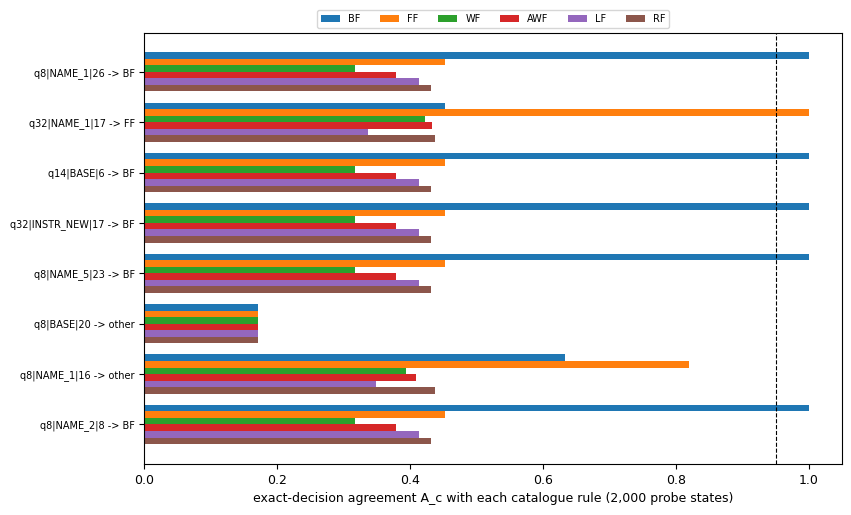

In [28]:
orders_c = analysis.load_orders()
for ex in demo[:2]:
    r0 = rows[ex["metadata_row_id"]]
    B1 = analysis.banned_for(r0["cell"], orders_c[r0["model"]]) if r0["cell"].startswith(("NAME_", "HOLD_", "DESC_")) else []
    print(f"=== {r0['row_id']} ({r0['model_id']}, {r0['engine']})")
    print("prompt condition  :", r0["condition"])
    print("banned set        :", B1)
    print("lexical hits      :", r0["hits_program"], "-> L1 compliant:", analysis.lex(r0, B1))
    print("synonyms (renames):", r0["synonyms"])
    print("agreement A_c     :", {c: round(a, 3) for c, a in r0["A"].items()} if r0.get("A") else None)
    print("class             :", analysis.row_class(r0), "-> mechanistically compliant:", analysis.mech(r0, B1))
    print("extracted program :\n" + r0["code"][:1400] + ("\n    ..." if len(r0["code"]) > 1400 else "") + "\n")

show = [rows[e["metadata_row_id"]] for e in demo if rows[e["metadata_row_id"]].get("A")][:8]
if show:
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(show) + 1.2))
    rules = ["BF", "FF", "WF", "AWF", "LF", "RF"]
    for j, c in enumerate(rules):
        ax.barh(np.arange(len(show)) + (j - 2.5) * 0.13, [r["A"][c] for r in show], height=0.13,
                color=figures.CLASS_COL[c], label=c)
    ax.axvline(0.95, color="k", ls="--", lw=0.8)
    ax.invert_yaxis()
    ax.set_yticks(range(len(show)))
    ax.set_yticklabels([f"{r['row_id']} -> {analysis.row_class(r)}" for r in show], fontsize=7)
    ax.set_xlabel("exact-decision agreement A_c with each catalogue rule (2,000 probe states)")
    ax.legend(fontsize=7, ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    plt.show()

## Do the recomputed rows match the shipped ones?
`outputs.sample_row` builds the shared per-sample schema from each recomputed row. These rows are compared with the labels shipped in
`method_out.json`: mechanism class, L1, mechanistic compliance, validity, the agreement vector, the held-out excess and the code hash.

In [29]:
checks = Counter()
mism = []
for ex in demo:
    s = outputs.sample_row(rows[ex["metadata_row_id"]], orders_c)
    got = {"class": s["label"],
           "L1": "n/a" if s["L1"] is None else ("compliant" if s["L1"] else "violates"),
           "mech": "n/a" if s["mech_compliant"] is None else ("compliant" if s["mech_compliant"] else "non_compliant"),
           "valid": outputs.tri(s["passed"]), "code_sha256": s["code_sha256"]}
    want = {"class": ex["predict_mechanism_class"], "L1": ex["predict_lexical_L1"],
            "mech": ex["predict_mechanistic_compliance"], "valid": ex["predict_valid"],
            "code_sha256": ex["metadata_code_sha256"]}
    for k in got:
        checks[k] += got[k] == want[k]
        if got[k] != want[k]:
            mism.append((ex["metadata_row_id"], k, want[k], got[k]))
    if s["A"] and ex["metadata_A"]:
        checks["A (max |diff| < 1e-6)"] += max(abs(s["A"][c] - ex["metadata_A"][c]) for c in s["A"]) < 1e-6
    if ex["metadata_h_or3_excess"] is not None:
        checks["H-OR3 excess"] += abs((s["h_or3_excess"] or -1) - ex["metadata_h_or3_excess"]) < 1e-9
n_A = sum(1 for ex in demo if ex["metadata_A"])
n_or3 = sum(1 for ex in demo if ex["metadata_h_or3_excess"] is not None)
print(f"agreement with the shipped rows ({len(demo)} programs; A for {n_A}, H-OR3 for {n_or3}):")
for k, v in checks.items():
    print(f"  {k:24s} {v}/{n_A if k.startswith('A ') else n_or3 if k.startswith('H-OR3') else len(demo)}")
print("mismatches:", mism if mism else "none")

agreement with the shipped rows (100 programs; A for 88, H-OR3 for 88):
  class                    100/100
  L1                       100/100
  mech                     100/100
  valid                    100/100
  code_sha256              100/100
  A (max |diff| < 1e-6)    88/88
  H-OR3 excess             88/88
mismatches: none


## s10 — the pre-registered analysis
This calls `analysis.run_all()` exactly as `method.py --stage s10` does, on the replayed subset. A subset of 100 is too small for the
pre-registered verdicts, which need N 30-50 per cell, so the per-cell rates are printed beside the full-run values from
`results/cells.json`.

In [30]:
verdicts = analysis.run_all()
print("verdicts on the demo subset:", verdicts)
ref = data["metadata"]["paper_reference"]
print("full-run verdicts: P1", ref["p1"]["verdict"], "| P2", ref["p2_verdict"], "| P3", ref["p3_verdict"])
cells_demo = read_json(RESULTS / "cells.json")
print(f"\n{'model|cell':18s} {'N':>3s} {'VALID':>5s}   {'L1':>5s} {'mech':>5s} {'gap':>6s}  |  full run: {'N':>3s} {'L1':>5s} {'mech':>5s} {'gap':>6s}")
fmt = lambda x: "  -  " if x is None else f"{x:5.2f}"
for key in sorted(cells_demo, key=lambda k: (k.split("|")[0], figures.CELLS.index(k.split("|")[1]))):
    c, p = cells_demo[key], ref["cells"][key]
    print(f"{key:18s} {c['N']:3d} {c['VALID']:5d}   {fmt(c['L1_valid']['rate'])} {fmt(c['mech_valid']['rate'])} "
          f"{(' ' + fmt(c['gap_valid'])) if c['gap_valid'] is not None else '   -  '}  |            {p['N']:3d} "
          f"{fmt(p['L1_valid'])} {fmt(p['mech_valid'])}  {fmt(p['gap_valid'])}")

p1 = read_json(RESULTS / "p1.json")
for m, v in p1["per_model"].items():
    d, pr = v["d"], ref["p1"]["per_model"][m]
    ci = d.get("paired_newcombe95")
    print(f"\n{m}: NAME_5 gap L1 - mech = {fmt(d.get('gap'))} (paired Newcombe 95% "
          f"{'[' + ', '.join(f'{x:.2f}' for x in ci) + ']' if ci else 'n/a'}, n {d.get('n')}) | full run "
          f"{pr['k5_gap']:+.2f} [{pr['k5_paired_newcombe95'][0]:.2f}, {pr['k5_paired_newcombe95'][1]:.2f}]")
ren = read_json(RESULTS / "rename_table.json")
for m in ["q8", "q14", "q32"]:
    k = f"{m}|NAME_1"
    if k in ren:
        print(f"{k}: {ren[k]['n_mech_noncompliant']}/{ren[k]['n_lex_compliant_valid']} lexically clean programs are still "
              f"a banned rule | full run {ref['rename_table'][k]['n_mech_noncompliant']}/"
              f"{ref['rename_table'][k]['n_lex_compliant_valid']}")
print("\nBASE frequency order recomputed from the replayed BASE rows (the analysis uses the committed order):")
for m in orders:
    base_rows = [r for r in rows.values() if r["model"] == m and r["cell"] == "BASE"]
    if base_rows:
        fo = analysis.frequency_order(base_rows)
        print(f"  {m}: counts {fo['counts']} (+{fo['other']} other) -> {fo['order']}")

15:34:14|INFO   |P1 PARTIAL  P2 PARTIAL  P3 SUPPORTED


verdicts on the demo subset: {'p1': {'verdict': 'PARTIAL', 'run_models': ['q14', 'q32', 'q8'], 'a_in_every_model': False, 'count_holding': {'b': 0, 'c': 2, 'd': 1, 'e': 0}, 'failing_parts': ['a (not in every run model)', 'b (holds in 0 of 3)', 'd (holds in 1 of 3)', 'e (holds in 0 of 3)'], 'reduced_panel': False}, 'p2': {'verdict': 'PARTIAL', 'run_models': ['q32', 'q8'], 'n_holding': 0, 'n_disconfirming': 1, 'reduced_panel': True}, 'p3': 'SUPPORTED'}
full-run verdicts: P1 PARTIAL | P2 DISCONFIRMED | P3 SUPPORTED

model|cell           N VALID      L1  mech    gap  |  full run:   N    L1  mech    gap
q14|BASE             3     3    1.00  0.00   1.00  |             50  0.84  0.00   0.84
q14|NAME_1           3     3    1.00  1.00   0.00  |             30  0.93  1.00  -0.07
q14|NAME_2           1     1    0.00  1.00  -1.00  |             30  0.87  1.00  -0.13
q14|NAME_3           1     1    1.00  1.00   0.00  |             30  0.93  0.85   0.07
q14|NAME_4           1     1    1.00  1.00   0

## Figures F1-F6
These are the original figure functions, run on the replayed subset:

* **F1**: lexical vs mechanistic compliance over k.
* **F2**: class composition per cell.
* **F3**: **MDS behaviour map in decision space**. Every point is a distinct program, placed by classical
  multidimensional scaling of the distance 1 − exact-decision agreement on the 2,000 probe states. Catalogue rules are
  ✚, published heuristics ×/★ and the ab grid grey.
* **F4**: instrument agreement heatmap.
* **F5**: held-out excess.
* **F6**: maximum agreement with a banned rule.

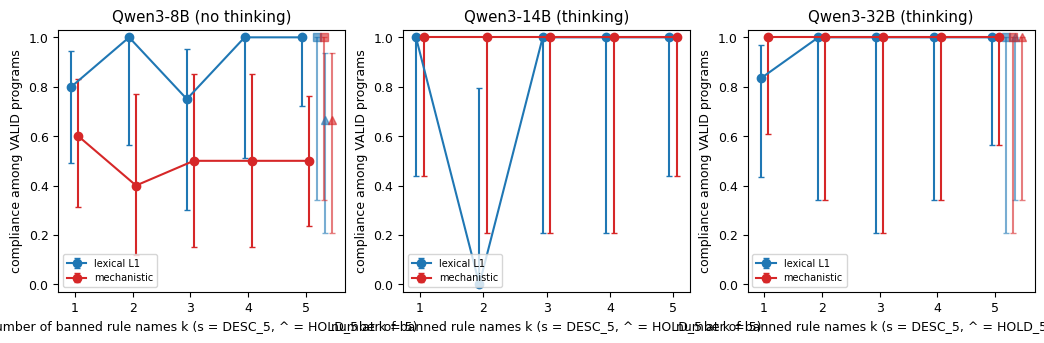

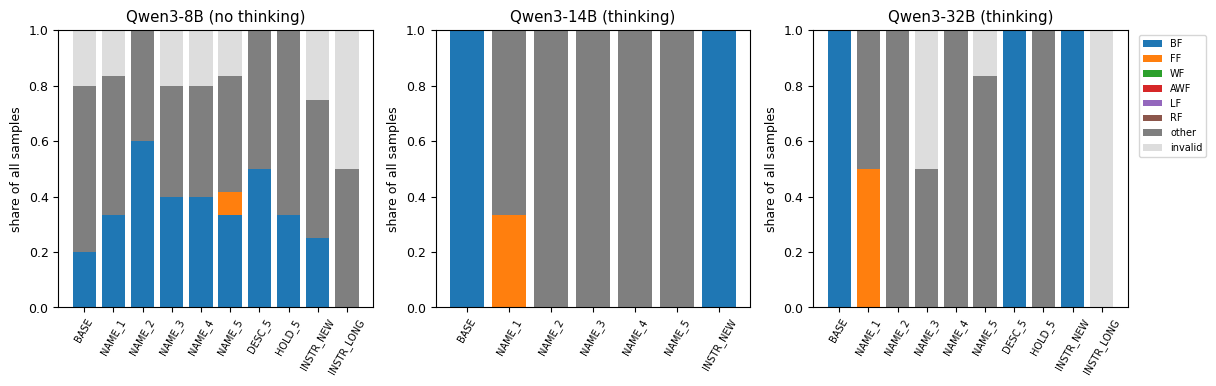

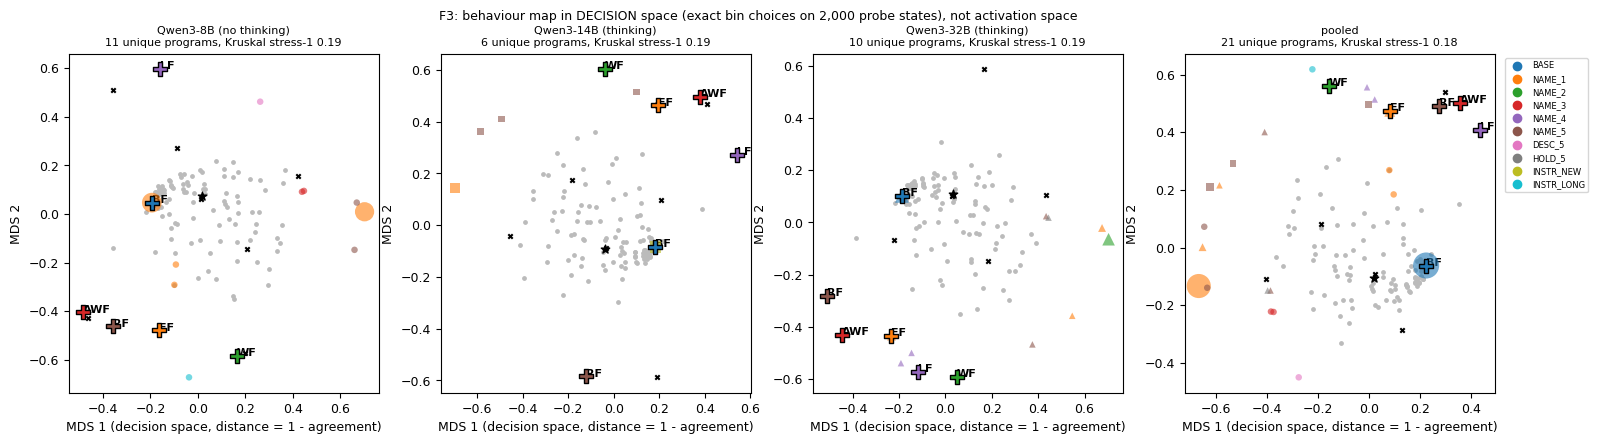

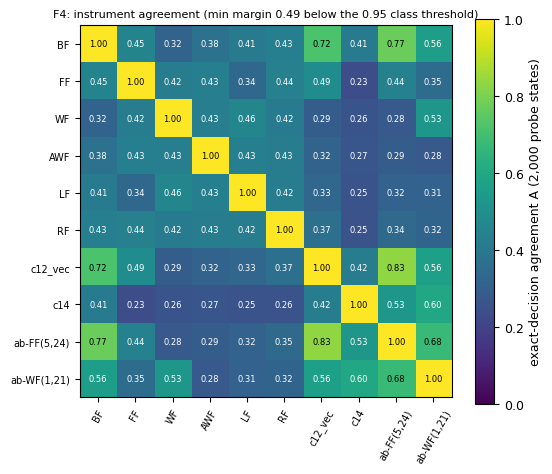

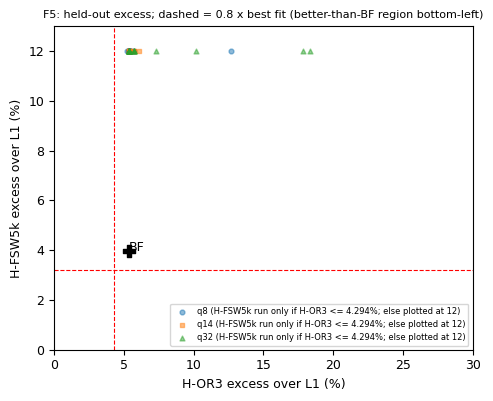

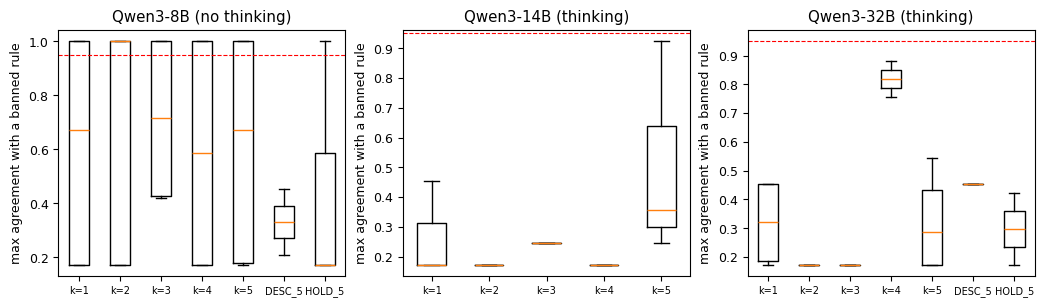

{'F1': 'ok', 'F2': 'ok', 'F3': {'q8': {'n_unique_programs': 11, 'n_programs': 46, 'stress1': 0.188}, 'q14': {'n_unique_programs': 6, 'n_programs': 15, 'stress1': 0.188}, 'q32': {'n_unique_programs': 10, 'n_programs': 27, 'stress1': 0.186}, 'pooled': {'n_unique_programs': 21, 'n_programs': 88, 'stress1': 0.184}}, 'F4': 'ok', 'F5': 'ok', 'F6': 'ok'}


In [31]:
fig_info = figures.run_all()
print({k: (v if isinstance(v, str) else {p: {kk: (round(vv, 3) if isinstance(vv, float) else vv) for kk, vv in d.items()}
                                          for p, d in v.items()}) for k, v in fig_info.items()})

## Summary: what the replayed programs show
The summary plot compares, per model, lexical (L1) and mechanistic compliance under the k = 1 and k = 5 name bans, together with the
share of best-fit programs under no ban (BASE) and under *"Make a new algorithm"* (INSTR_NEW). Bars are the replayed subset;
black ticks are the full run of 1,143 programs.

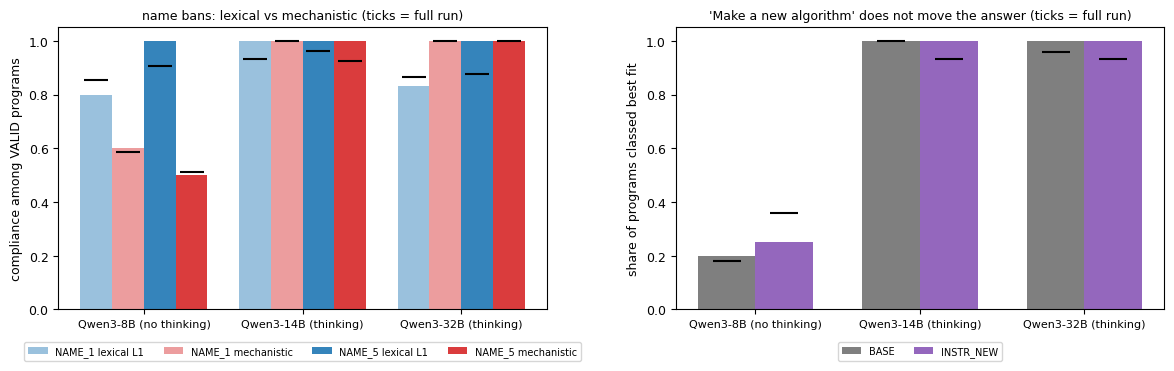

model cell     L1 demo mech demo  L1 full mech full
q8    NAME_1      0.80      0.60     0.85      0.59
q8    NAME_5      1.00      0.50     0.91      0.51
q14   NAME_1      1.00      1.00     0.93      1.00
q14   NAME_5      1.00      1.00     0.96      0.93
q32   NAME_1      0.83      1.00     0.87      1.00
q32   NAME_5      1.00      1.00     0.88      1.00
q14|NAME_1: reasoning traces naming a banned rule 1.00 (full run 1.00); self-identifying near it 1.00 (full run 0.90)
q14|NAME_5: reasoning traces naming a banned rule 1.00 (full run 1.00); self-identifying near it 1.00 (full run 1.00)
q32|NAME_1: reasoning traces naming a banned rule 1.00 (full run 1.00); self-identifying near it 1.00 (full run 0.94)
q32|NAME_5: reasoning traces naming a banned rule 1.00 (full run 1.00); self-identifying near it 1.00 (full run 1.00)


In [32]:
models = [m for m in ["q8", "q14", "q32"] if any(r["model"] == m for r in rows.values())]
name = {"q8": "Qwen3-8B (no thinking)", "q14": "Qwen3-14B (thinking)", "q32": "Qwen3-32B (thinking)"}
panels = [("NAME_1", "L1_valid"), ("NAME_1", "mech_valid"), ("NAME_5", "L1_valid"), ("NAME_5", "mech_valid")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(models))
for j, (cell, key) in enumerate(panels):
    vals = [(cells_demo.get(f"{m}|{cell}") or {}).get(key, {}).get("rate") for m in models]
    refv = [ref["cells"][f"{m}|{cell}"][key] for m in models]
    col = "#1f77b4" if key == "L1_valid" else "#d62728"
    off = (j - 1.5) * 0.2
    axes[0].bar(x + off, [v if v is not None else 0 for v in vals], 0.2, color=col, alpha=0.45 if cell == "NAME_1" else 0.9,
                label=f"{cell} {'lexical L1' if key == 'L1_valid' else 'mechanistic'}")
    axes[0].scatter(x + off, refv, marker="_", s=300, color="k", zorder=3)
axes[0].set_xticks(x)
axes[0].set_xticklabels([name[m] for m in models], fontsize=8)
axes[0].set_ylabel("compliance among VALID programs")
axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
axes[0].set_title("name bans: lexical vs mechanistic (ticks = full run)", fontsize=9)


def bf_share(m, cell, src):
    if src == "demo":
        rs = [r for r in rows.values() if r["model"] == m and r["cell"] == cell]
        return (sum(analysis.row_class(r) == "BF" for r in rs) / len(rs)) if rs else None
    c = ref["cells"][f"{m}|{cell}"]
    return c["class_composition"].get("BF", 0) / c["N"]


for j, cell in enumerate(["BASE", "INSTR_NEW"]):
    vals = [bf_share(m, cell, "demo") for m in models]
    axes[1].bar(x + (j - 0.5) * 0.35, [v or 0 for v in vals], 0.35, color=["#7f7f7f", "#9467bd"][j], label=cell)
    axes[1].scatter(x + (j - 0.5) * 0.35, [bf_share(m, cell, "ref") for m in models], marker="_", s=400, color="k",
                    zorder=3)
axes[1].set_xticks(x)
axes[1].set_xticklabels([name[m] for m in models], fontsize=8)
axes[1].set_ylabel("share of programs classed best fit")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
axes[1].set_title("'Make a new algorithm' does not move the answer (ticks = full run)", fontsize=9)
plt.tight_layout()
plt.show()

print(f"{'model':5s} {'cell':7s} {'L1 demo':>8s} {'mech demo':>9s} {'L1 full':>8s} {'mech full':>9s}")
for m in models:
    for cell in ["NAME_1", "NAME_5"]:
        c = cells_demo.get(f"{m}|{cell}")
        p = ref["cells"][f"{m}|{cell}"]
        if c:
            print(f"{m:5s} {cell:7s} {fmt(c['L1_valid']['rate']):>8s} {fmt(c['mech_valid']['rate']):>9s} "
                  f"{fmt(p['L1_valid']):>8s} {fmt(p['mech_valid']):>9s}")
rs_ = read_json(RESULTS / "reasoning.json")
for k, v in sorted(rs_.items()):
    if k.endswith(("NAME_1", "NAME_5")) and v["n_traces"]:
        pr = ref["reasoning"][k]
        print(f"{k}: reasoning traces naming a banned rule {v['share_mention_banned']:.2f} (full run "
              f"{pr['share_mention_banned']:.2f}); self-identifying near it {v['share_self_identification']:.2f} "
              f"(full run {pr['share_self_identification']:.2f})")

### Reading the results
Numbers are for the committed configuration (`N_EVAL = 100`).

* **Qwen3-8B (no thinking)** mostly obeys a name ban *lexically* but keeps *implementing* the banned rule. At k = 5
  its replayed programs have L1 1.00 but mechanistic compliance 0.50, a gap of **+0.50 [0.12, 0.76]** (paired Newcombe;
  full run +0.40 [0.21, 0.55]). The renamed programs drop the words "best fit" but keep the arg-min-slack logic, under
  names such as *tightest* or *minimum remaining space*, or even the wrong name *First Fit Decreasing*. In the F3 map
  they sit exactly on the BF cross.
* **Qwen3-14B/32B (thinking)** really leave the banned rules: mechanistic compliance is 1.00 at k = 1 and k = 5 and the
  gaps are 0.00. Under the best-fit ban Qwen3-32B often switches to first fit, and every reasoning trace names the banned rule.
* **The novelty instruction does not move the answer.** Every replayed BASE and INSTR_NEW program of the thinking
  models is best fit; the full run has 50/50 and 48/49 (BASE) and 28/29 and 28/28 ("Make a new algorithm").
* The replay reproduces every shipped per-program label exactly (100/100 classes, flags, agreement vectors and held-out
  excess values). Subset rates differ from the full run only through sampling: 1-12 programs per cell here, 30-50 in
  the full run. The mini corpus affects only the novelty score.